# Rekonstruksi Ekosistem Inovasi Pemerintah Daerah Jawa Timur
## Notebook 02: Knowledge Graph & Graph RAG
### STEP 1 — Persiapan Entity Knowledge Graph

Notebook ini merupakan kelanjutan langsung dari output final pipeline clustering pada notebook `Pipeline_Inovasi_Jawa_Timur_Clustering_to_Knowledge_Graph_Final.ipynb`. 

Karena pipeline clustering dan pemetaan wilayah sebelumnya telah berstatus **FINAL**, notebook ini langsung menggunakan basis data hasil clustering final (`kg_source_df.csv`) sebagai **single source of truth** tanpa melakukan preprocessing awal atau pelatihan clustering ulang.

---

### Dua Unit Analisis Final dari Pipeline Clustering

Berdasarkan metodologi final sebelumnya, terdapat pemisahan tegas antara dua unit analisis:

1. **Kabupaten/Kota (Unit Analisis: Wilayah)**
   - Klaster diturunkan dari fitur agregasi tingkat wilayah kabupaten/kota di Jawa Timur.
   - Merepresentasikan profil ekosistem inovasi daerah secara makro.
   - Dalam ontologi Knowledge Graph, entitas ini diinterpretasikan sebagai **`ProfilEkosistemInovasi`**.

2. **Provinsi Jawa Timur (Unit Analisis: Inovasi Individual)**
   - Klaster diturunkan dari fitur individual inovasi perangkat daerah Pemerintah Provinsi Jawa Timur (kematangan, jenis, dan tahapan).
   - Merepresentasikan kelompok inovasi individual yang memiliki pola karakteristik implementasi serupa.
   - Dalam ontologi Knowledge Graph, entitas ini diinterpretasikan sebagai **`ProfilKarakteristikInovasi`**.

Kedua unit analisis ini memiliki makna konseptual yang berbeda dan **tidak boleh dicampuradukkan**. Istilah teknis algoritma (`Cluster` dan `Jenis_Cluster`) tetap dipertahankan pada data tabular, namun secara semantik Knowledge Graph keduanya dimodelkan sebagai dua tipe entitas profil yang terpisah.


## 1. Pemuatan Data Final Hasil Clustering (`kg_source_df`)

Memuat basis data gabungan final yang telah berisi seluruh 679 inovasi lengkap dengan pemetaan wilayah (`Daerah`, `Jenis_Wilayah`), label teknis clustering (`Cluster`, `Jenis_Cluster`), serta tingkat kematangan (`Tingkat_Kematangan`).


In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)

DATA_PATH = Path("kg_source_df.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"File {DATA_PATH} tidak ditemukan.")

kg_source_df = pd.read_csv(DATA_PATH)

print("=== PEMUATAN BASIS DATA FINAL CLUSTERING ===")
print(f"Total baris inovasi : {len(kg_source_df):,}")
print(f"Total kolom         : {kg_source_df.shape[1]}")
print(f"Kolom tersedia      : {kg_source_df.columns.tolist()}")

print("\nDistribusi Jenis Wilayah:")
print(kg_source_df["Jenis_Wilayah"].value_counts(dropna=False).to_string())

print("\nDistribusi Jenis Cluster:")
print(kg_source_df["Jenis_Cluster"].value_counts(dropna=False).to_string())

print("\nDistribusi Tingkat Kematangan:")
print(kg_source_df["Tingkat_Kematangan"].value_counts(dropna=False).to_string())

display(kg_source_df[[
    "Judul Inovasi", "Admin OPD", "Daerah", "Jenis_Wilayah",
    "Cluster", "Jenis_Cluster", "Tingkat_Kematangan"
]].head(5))


=== PEMUATAN BASIS DATA FINAL CLUSTERING ===
Total baris inovasi : 679
Total kolom         : 28
Kolom tersedia      : ['No', 'Judul Inovasi', 'Pemda', 'Admin OPD', 'Inisiator', 'Nama Inisiator', 'Bentuk Inovasi', 'Jenis', 'Asta Cipta', 'Urusan Utama', 'Urusan lain yang beririsan', 'Kematangan', 'Tahapan Inovasi', 'Tanggal Input', 'Tanggal Penerapan', 'Tanggal Pengembangan', 'Koordinat', 'Video', 'Link Video', 'Daerah', 'Jenis_Wilayah', 'Cluster_KabKota', 'Tingkat_Kematangan_KabKota', 'Cluster_Provinsi', 'Tingkat_Kematangan_Provinsi', 'Cluster', 'Jenis_Cluster', 'Tingkat_Kematangan']

Distribusi Jenis Wilayah:
Jenis_Wilayah
Kabupaten/Kota    466
Provinsi          212
NaN                 1

Distribusi Jenis Cluster:
Jenis_Cluster
Cluster_Wilayah             466
Cluster_Inovasi_Provinsi    212
NaN                           1

Distribusi Tingkat Kematangan:
Tingkat_Kematangan
Sedang    482
Tinggi     96
Rendah     94
NaN         7


,Judul Inovasi,Admin OPD,Daerah,Jenis_Wilayah,Cluster,Jenis_Cluster,Tingkat_Kematangan
0,POP SURGA (Penghantaran Obat Pasien Sumberglagah),Dinas Kesehatan UPT. RSK Sumberglagah Mojokerto (jatimprov.dinkes.uptsumberglagahmjk),Kabupaten Mojokerto,Kabupaten/Kota,2.0,Cluster_Wilayah,Sedang
1,PHEC (Pre Hospital Emergency Care),Dinas Kesehatan UPT. RSK Sumberglagah Mojokerto (jatimprov.dinkes.uptsumberglagahmjk),Kabupaten Mojokerto,Kabupaten/Kota,2.0,Cluster_Wilayah,Sedang
2,Naskah Dinas Elektronik (NADINE),Badan Koordinasi Wilayah Pamekasan Provinsi Jawa Timur (jatimprov.bakorwilpamekasan),Provinsi Jawa Timur,Provinsi,1.0,Cluster_Inovasi_Provinsi,Rendah
3,PERMATA ( Pertanian Ramah Lingkungan menuju Masyarakat Tangguh dan Alamiah ),Dinas Pertanian dan Ketahanan Pangan (jatimprov.dispertanian),Provinsi Jawa Timur,Provinsi,3.0,Cluster_Inovasi_Provinsi,Tinggi
4,SIGALON,Dinas Kesehatan UPT. RS Mata Masyarakat (jatimprov.dinkes.uptmatamasy),Provinsi Jawa Timur,Provinsi,3.0,Cluster_Inovasi_Provinsi,Tinggi


## 2. Konsep Semantik & Perancangan Entitas (Entity Nodes)

### Transformasi Konseptual: Dari "Cluster" Menjadi Entitas Profil Semantik

Pada tahap analisis data teknis, hasil pengelompokan disimpan sebagai atribut `Cluster` (nilai numerik 1, 2, 3) dan `Jenis_Cluster`. Namun pada Knowledge Graph, istilah "Cluster" tidak digunakan sebagai entitas semantik utama karena tidak memiliki kejelasan substantif domain.

Sebagai gantinya, Knowledge Graph membedakan secara tegas dua entitas profil:

| Dimensi | `ProfilEkosistemInovasi` | `ProfilKarakteristikInovasi` |
| :--- | :--- | :--- |
| **Unit Analisis** | Wilayah (Kabupaten/Kota) | Inovasi Individual Tingkat Provinsi |
| **Fokus Semantik** | Profil ekosistem inovasi daerah secara agregat | Profil pola kematangan, jenis, dan tahapan implementasi inovasi |
| **Relasi Graf** | `Daerah` → `MEMILIKI_PROFIL_EKOSISTEM` → `ProfilEkosistemInovasi` | `Inovasi` → `MEMILIKI_PROFIL_KARAKTERISTIK` → `ProfilKarakteristikInovasi` |
| **Penamaan Node** | Netral / Objektif (tanpa label subjektif "Unggul" / "Lemah") | Netral / Objektif (tanpa label subjektif "Terbaik") |

### Daftar 10 Entity Tables yang Dibangun:
1. `nodes_inovasi`: Entitas sentral seluruh 679 inovasi dengan primary key deterministic `INV_0001` s/d `INV_0679`.
2. `nodes_opd`: Entitas unit kerja / perangkat daerah / sekolah penyelenggara inovasi.
3. `nodes_daerah`: Entitas wilayah administratif (kabupaten/kota serta provinsi Jawa Timur).
4. `nodes_profil_ekosistem`: Entitas profil ekosistem daerah hasil klaster wilayah makro.
5. `nodes_profil_inovasi_provinsi`: Entitas profil karakteristik inovasi individual level provinsi.
6. `nodes_jenis`: Entitas jenis inovasi (Digital, Non Digital, Teknologi).
7. `nodes_bentuk`: Entitas bentuk regulasi inovasi daerah.
8. `nodes_asta_cipta`: Entitas program prioritas Asta Cipta (hanya nilai valid).
9. `nodes_urusan`: Entitas urusan pemerintahan gabungan (Urusan Utama dan Urusan Irisan).
10. `nodes_tahapan`: Entitas tahapan kematangan implementasi (Inisiatif, Uji Coba, Penerapan).


### Konstruksi Entitas 1: `nodes_inovasi`
Setiap baris pada `kg_source_df` merepresentasikan satu inovasi. Primary key dibangun secara deterministik (`INV_0001` hingga `INV_0679`) untuk menghindari ambiguitas judul yang duplikat.


In [2]:
# ------------------------------------------------------------
# 1. ENTITY TABLE: nodes_inovasi
# ------------------------------------------------------------
nodes_inovasi_list = []

def clean_val(v):
    if pd.isna(v) or str(v).strip() in ["", "-", "nan", "None", "<NA>"]:
        return None
    return str(v).strip()

def clean_float(v):
    try:
        val = float(v)
        return None if np.isnan(val) else val
    except:
        return None

def clean_int(v):
    try:
        if pd.isna(v):
            return None
        return int(float(v))
    except:
        return None

for idx, row in kg_source_df.iterrows():
    inv_id = f"INV_{idx+1:04d}"
    
    nodes_inovasi_list.append({
        "inovasi_id": inv_id,
        "judul_inovasi": str(row["Judul Inovasi"]).strip(),
        "kematangan": clean_float(row.get("Kematangan")),
        "tanggal_input": clean_val(row.get("Tanggal Input")),
        "tanggal_penerapan": clean_val(row.get("Tanggal Penerapan")),
        "tanggal_pengembangan": clean_val(row.get("Tanggal Pengembangan")),
        "inisiator": clean_val(row.get("Inisiator")),
        "daerah": clean_val(row.get("Daerah")),
        "jenis_wilayah": clean_val(row.get("Jenis_Wilayah")),
        "jenis_cluster": clean_val(row.get("Jenis_Cluster")),
        "cluster": clean_int(row.get("Cluster")),
        "tingkat_kematangan": clean_val(row.get("Tingkat_Kematangan")),
        "admin_opd": clean_val(row.get("Admin OPD")),
        "bentuk_inovasi": clean_val(row.get("Bentuk Inovasi")),
        "jenis": clean_val(row.get("Jenis")),
        "asta_cipta": clean_val(row.get("Asta Cipta")),
        "tahapan_inovasi": clean_val(row.get("Tahapan Inovasi")),
        "koordinat": clean_val(row.get("Koordinat")),
        "video": clean_val(row.get("Video")),
        "link_video": clean_val(row.get("Link Video"))
    })

nodes_inovasi = pd.DataFrame(nodes_inovasi_list)

print(f"nodes_inovasi selesai : {nodes_inovasi.shape[0]} baris x {nodes_inovasi.shape[1]} kolom")
print(f"Rentang inovasi_id    : {nodes_inovasi['inovasi_id'].iloc[0]} s/d {nodes_inovasi['inovasi_id'].iloc[-1]}")
display(nodes_inovasi.head(5))


nodes_inovasi selesai : 679 baris x 20 kolom
Rentang inovasi_id    : INV_0001 s/d INV_0679


,inovasi_id,judul_inovasi,kematangan,tanggal_input,tanggal_penerapan,tanggal_pengembangan,inisiator,daerah,jenis_wilayah,jenis_cluster,cluster,tingkat_kematangan,admin_opd,bentuk_inovasi,jenis,asta_cipta,tahapan_inovasi,koordinat,video,link_video
0,INV_0001,POP SURGA (Penghantaran Obat Pasien Sumberglagah),85.0,22-07-2022,29-11-2023,NaN,Kepala Daerah,Kabupaten Mojokerto,Kabupaten/Kota,Cluster_Wilayah,2.0,Sedang,Dinas Kesehatan UPT. RSK Sumberglagah Mojokerto (jatimprov.dinkes.uptsumberglagahmjk),Inovasi pelayanan publik,Digital,"Memperkuat pembangunan sumber daya manusia (SDM), sains, teknologi, pendidikan, kesehatan, prestasi olahraga, keseta...",Penerapan,"-7.60739065953564, 112.54078722662341",Ada,https://www.youtube.com/watch?v=o_TedznOu3U
1,INV_0002,PHEC (Pre Hospital Emergency Care),92.0,22-07-2022,24-06-2023,NaN,OPD,Kabupaten Mojokerto,Kabupaten/Kota,Cluster_Wilayah,2.0,Sedang,Dinas Kesehatan UPT. RSK Sumberglagah Mojokerto (jatimprov.dinkes.uptsumberglagahmjk),Inovasi pelayanan publik,Non Digital,"Memperkuat pembangunan sumber daya manusia (SDM), sains, teknologi, pendidikan, kesehatan, prestasi olahraga, keseta...",Penerapan,"-7.6073109183015, 112.54072288029913",Ada,https://youtu.be/TJaII4_0UkI
2,INV_0003,Naskah Dinas Elektronik (NADINE),110.0,20-06-2023,31-12-2024,31-12-2024,OPD,Provinsi Jawa Timur,Provinsi,Cluster_Inovasi_Provinsi,1.0,Rendah,Badan Koordinasi Wilayah Pamekasan Provinsi Jawa Timur (jatimprov.bakorwilpamekasan),Inovasi tata kelola pemerintahan daerah,Teknologi,"Memperkuat reformasi politik, hukum, dan birokrasi, serta memperkuat pencegahan dan pemberantasan korupsi dan narkoba.",Penerapan,"-7.158553824257441, 113.48272568540575",Ada,https://drive.google.com/file/d/192dhJGWtC4lDcuxiKw_n5B7iFEPUpgne/view
3,INV_0004,PERMATA ( Pertanian Ramah Lingkungan menuju Masyarakat Tangguh dan Alamiah ),60.0,26-06-2023,25-09-2023,NaN,OPD,Provinsi Jawa Timur,Provinsi,Cluster_Inovasi_Provinsi,3.0,Tinggi,Dinas Pertanian dan Ketahanan Pangan (jatimprov.dispertanian),Inovasi Daerah lainnya sesuai dengan Urusan Pemerintahan yang menjadi kewenangan Daerah,Digital,NaN,Uji Coba,NaN,Tidak Ada,NaN
4,INV_0005,SIGALON,52.0,10-07-2023,10-07-2023,NaN,OPD,Provinsi Jawa Timur,Provinsi,Cluster_Inovasi_Provinsi,3.0,Tinggi,Dinas Kesehatan UPT. RS Mata Masyarakat (jatimprov.dinkes.uptmatamasy),Inovasi pelayanan publik,Digital,NaN,Penerapan,NaN,Ada,https://drive.google.com/file/d/1JKCIqN4TRVL-Om9yFgXMyJYJIPe-DMRa/view?usp=drive_link


### Konstruksi Entitas 2 & 3: `nodes_opd` dan `nodes_daerah`
- `nodes_opd`: Diturunkan dari nama unik `Admin OPD` yang telah distandardisasi dan dinormalisasi spasi.
- `nodes_daerah`: Diturunkan dari daftar daerah valid hasil pemetaan wilayah. Entitas 'Tidak Diketahui' tidak dimasukkan sebagai node daerah.


In [3]:
# ------------------------------------------------------------
# 2. ENTITY TABLE: nodes_opd
# ------------------------------------------------------------
raw_opd = [
    str(x).strip() for x in kg_source_df["Admin OPD"].dropna()
    if str(x).strip() not in ["", "-", "nan", "None"]
]
unique_opd = sorted(list(set(raw_opd)))
opd_to_id = {opd: f"OPD_{i+1:03d}" for i, opd in enumerate(unique_opd)}

nodes_opd = pd.DataFrame([
    {"opd_id": opd_to_id[opd], "nama_opd": opd}
    for opd in unique_opd
])

print(f"nodes_opd selesai    : {nodes_opd.shape[0]} baris x {nodes_opd.shape[1]} kolom")
display(nodes_opd.head(5))

# ------------------------------------------------------------
# 3. ENTITY TABLE: nodes_daerah
# ------------------------------------------------------------
raw_daerah = [
    str(x).strip() for x in kg_source_df["Daerah"].dropna()
    if str(x).strip() not in ["", "-", "nan", "None", "Tidak Diketahui", "Belum Terpetakan"]
]
unique_daerah = sorted(list(set(raw_daerah)))
daerah_to_id = {d: f"DAERAH_{i+1:02d}" for i, d in enumerate(unique_daerah)}

nodes_daerah = pd.DataFrame([
    {
        "daerah_id": daerah_to_id[d],
        "nama_daerah": d,
        "level_daerah": "Provinsi" if d == "Provinsi Jawa Timur" else "Kabupaten/Kota"
    }
    for d in unique_daerah
])

print(f"\nnodes_daerah selesai : {nodes_daerah.shape[0]} baris x {nodes_daerah.shape[1]} kolom")
print(f"Distribusi level     :\n{nodes_daerah['level_daerah'].value_counts().to_string()}")
display(nodes_daerah.head(5))


nodes_opd selesai    : 292 baris x 2 kolom


,opd_id,nama_opd
0,OPD_001,Badan Kepegawaian Daerah Provinsi Jawa Timur (jatimprov.bkd)
1,OPD_002,Badan Kesatuan Bangsa dan Politik Provinsi Jawa Timur (jatimprov.bakesbangpol)
2,OPD_003,Badan Koordinasi Wilayah Bojonegoro Provinsi Jawa Timur (jatimprov.bakorwilbojonegoro)
3,OPD_004,Badan Koordinasi Wilayah Jember Provinsi Jawa Timur (jatimprov.bakorwiljember)
4,OPD_005,Badan Koordinasi Wilayah Madiun Provinsi Jawa Timur (jatimprov.bakorwilmadiun)



nodes_daerah selesai : 36 baris x 3 kolom
Distribusi level     :
level_daerah
Kabupaten/Kota    35
Provinsi           1


,daerah_id,nama_daerah,level_daerah
0,DAERAH_01,Kabupaten Bangkalan,Kabupaten/Kota
1,DAERAH_02,Kabupaten Banyuwangi,Kabupaten/Kota
2,DAERAH_03,Kabupaten Blitar,Kabupaten/Kota
3,DAERAH_04,Kabupaten Bojonegoro,Kabupaten/Kota
4,DAERAH_05,Kabupaten Bondowoso,Kabupaten/Kota


### Konstruksi Entitas 4 & 5: `nodes_profil_ekosistem` dan `nodes_profil_inovasi_provinsi`
Mendefinisikan dua entitas profil secara terpisah:
1. `nodes_profil_ekosistem`: Representasi substantif klaster wilayah (Kabupaten/Kota).
2. `nodes_profil_inovasi_provinsi`: Representasi substantif klaster inovasi individual tingkat Provinsi.

Penamaan profil bersifat teknis dan sementara, tanpa label subjektif seperti 'Unggul' atau 'Lemah'.


In [4]:
# ------------------------------------------------------------
# 4. ENTITY TABLE: nodes_profil_ekosistem
# ------------------------------------------------------------
# Klaster Makro Wilayah Kabupaten/Kota (K=3)
nodes_profil_ekosistem = pd.DataFrame([
    {
        "profil_ekosistem_id": "PROFILE_EKO_01",
        "source_cluster_id": 1,
        "jenis_cluster": "Cluster_Wilayah",
        "tingkat_kematangan": "Tinggi",
        "nama_profil": "Profil Ekosistem Wilayah 1"
    },
    {
        "profil_ekosistem_id": "PROFILE_EKO_02",
        "source_cluster_id": 2,
        "jenis_cluster": "Cluster_Wilayah",
        "tingkat_kematangan": "Sedang",
        "nama_profil": "Profil Ekosistem Wilayah 2"
    },
    {
        "profil_ekosistem_id": "PROFILE_EKO_03",
        "source_cluster_id": 3,
        "jenis_cluster": "Cluster_Wilayah",
        "tingkat_kematangan": "Rendah",
        "nama_profil": "Profil Ekosistem Wilayah 3"
    }
])

print(f"nodes_profil_ekosistem selesai : {nodes_profil_ekosistem.shape[0]} baris x {nodes_profil_ekosistem.shape[1]} kolom")
display(nodes_profil_ekosistem)

# ------------------------------------------------------------
# 5. ENTITY TABLE: nodes_profil_inovasi_provinsi
# ------------------------------------------------------------
# Klaster Mikro Inovasi Individual Pemerintah Provinsi (K=3)
nodes_profil_inovasi_provinsi = pd.DataFrame([
    {
        "profil_provinsi_id": "PROFILE_PROV_01",
        "source_cluster_id": 1,
        "jenis_cluster": "Cluster_Inovasi_Provinsi",
        "tingkat_kematangan": "Rendah",
        "nama_profil": "Profil Karakteristik Inovasi Provinsi 1"
    },
    {
        "profil_provinsi_id": "PROFILE_PROV_02",
        "source_cluster_id": 2,
        "jenis_cluster": "Cluster_Inovasi_Provinsi",
        "tingkat_kematangan": "Sedang",
        "nama_profil": "Profil Karakteristik Inovasi Provinsi 2"
    },
    {
        "profil_provinsi_id": "PROFILE_PROV_03",
        "source_cluster_id": 3,
        "jenis_cluster": "Cluster_Inovasi_Provinsi",
        "tingkat_kematangan": "Tinggi",
        "nama_profil": "Profil Karakteristik Inovasi Provinsi 3"
    }
])

print(f"\nnodes_profil_inovasi_provinsi selesai : {nodes_profil_inovasi_provinsi.shape[0]} baris x {nodes_profil_inovasi_provinsi.shape[1]} kolom")
display(nodes_profil_inovasi_provinsi)


nodes_profil_ekosistem selesai : 3 baris x 5 kolom


,profil_ekosistem_id,source_cluster_id,jenis_cluster,tingkat_kematangan,nama_profil
0,PROFILE_EKO_01,1,Cluster_Wilayah,Tinggi,Profil Ekosistem Wilayah 1
1,PROFILE_EKO_02,2,Cluster_Wilayah,Sedang,Profil Ekosistem Wilayah 2
2,PROFILE_EKO_03,3,Cluster_Wilayah,Rendah,Profil Ekosistem Wilayah 3



nodes_profil_inovasi_provinsi selesai : 3 baris x 5 kolom


,profil_provinsi_id,source_cluster_id,jenis_cluster,tingkat_kematangan,nama_profil
0,PROFILE_PROV_01,1,Cluster_Inovasi_Provinsi,Rendah,Profil Karakteristik Inovasi Provinsi 1
1,PROFILE_PROV_02,2,Cluster_Inovasi_Provinsi,Sedang,Profil Karakteristik Inovasi Provinsi 2
2,PROFILE_PROV_03,3,Cluster_Inovasi_Provinsi,Tinggi,Profil Karakteristik Inovasi Provinsi 3


### Konstruksi Entitas 6, 7 & 8: `nodes_jenis`, `nodes_bentuk`, dan `nodes_asta_cipta`
- `nodes_jenis`: Nilai unik aktual (Digital, Non Digital, Teknologi).
- `nodes_bentuk`: Nilai aktual bentuk inovasi daerah tanpa mengubah nilai sumber.
- `nodes_asta_cipta`: Program prioritas nasional yang valid. Nilai `-` dianggap missing dan tidak dibuatkan node.


In [5]:
# ------------------------------------------------------------
# 6. ENTITY TABLE: nodes_jenis
# ------------------------------------------------------------
raw_jenis = [
    str(x).strip() for x in kg_source_df["Jenis"].dropna()
    if str(x).strip() not in ["", "-", "nan", "None"]
]
unique_jenis = sorted(list(set(raw_jenis)))
jenis_to_id = {j: f"JENIS_{i+1:02d}" for i, j in enumerate(unique_jenis)}
nodes_jenis = pd.DataFrame([
    {"jenis_id": jenis_to_id[j], "nama_jenis": j}
    for j in unique_jenis
])

print(f"nodes_jenis selesai      : {nodes_jenis.shape[0]} baris")
display(nodes_jenis)

# ------------------------------------------------------------
# 7. ENTITY TABLE: nodes_bentuk
# ------------------------------------------------------------
raw_bentuk = [
    str(x).strip() for x in kg_source_df["Bentuk Inovasi"].dropna()
    if str(x).strip() not in ["", "-", "nan", "None"]
]
unique_bentuk = sorted(list(set(raw_bentuk)))
bentuk_to_id = {b: f"BENTUK_{i+1:02d}" for i, b in enumerate(unique_bentuk)}
nodes_bentuk = pd.DataFrame([
    {"bentuk_id": bentuk_to_id[b], "nama_bentuk": b}
    for b in unique_bentuk
])

print(f"\nnodes_bentuk selesai     : {nodes_bentuk.shape[0]} baris")
display(nodes_bentuk)

# ------------------------------------------------------------
# 8. ENTITY TABLE: nodes_asta_cipta
# ------------------------------------------------------------
raw_asta = [
    str(x).strip() for x in kg_source_df["Asta Cipta"].dropna()
    if str(x).strip() not in ["", "-", "nan", "None"]
]
unique_asta = sorted(list(set(raw_asta)))
asta_to_id = {a: f"ASTA_{i+1:02d}" for i, a in enumerate(unique_asta)}
nodes_asta_cipta = pd.DataFrame([
    {"asta_cipta_id": asta_to_id[a], "nama_asta_cipta": a}
    for a in unique_asta
])

print(f"\nnodes_asta_cipta selesai : {nodes_asta_cipta.shape[0]} baris")
display(nodes_asta_cipta)


nodes_jenis selesai      : 3 baris


,jenis_id,nama_jenis
0,JENIS_01,Digital
1,JENIS_02,Non Digital
2,JENIS_03,Teknologi



nodes_bentuk selesai     : 3 baris


,bentuk_id,nama_bentuk
0,BENTUK_01,Inovasi Daerah lainnya sesuai dengan Urusan Pemerintahan yang menjadi kewenangan Daerah
1,BENTUK_02,Inovasi pelayanan publik
2,BENTUK_03,Inovasi tata kelola pemerintahan daerah



nodes_asta_cipta selesai : 8 baris


,asta_cipta_id,nama_asta_cipta
0,ASTA_01,Melanjutkan hilirisasi dan industrialisasi untuk meningkatkan nilai tambah di dalam negeri.
1,ASTA_02,"Memantapkan sistem pertahanan keamanan negara dan mendorong kemandirian bangsa melalui swasembada pangan, energi, ai..."
2,ASTA_03,Membangun dari desa dan dari bawah untuk pemerataan ekonomi dan pemberantasan kemiskinan.
3,ASTA_04,"Memperkokoh ideologi Pancasila, demokrasi, dan hak asasi manusia (HAM)."
4,ASTA_05,"Memperkuat pembangunan sumber daya manusia (SDM), sains, teknologi, pendidikan, kesehatan, prestasi olahraga, keseta..."
5,ASTA_06,"Memperkuat penyelarasan kehidupan yang harmonis dengan lingkungan, alam, dan budaya, serta peningkatan toleransi ant..."
6,ASTA_07,"Memperkuat reformasi politik, hukum, dan birokrasi, serta memperkuat pencegahan dan pemberantasan korupsi dan narkoba."
7,ASTA_08,"Meningkatkan lapangan kerja yang berkualitas, mendorong kewirausahaan, mengembangkan industri kreatif, dan melanjutk..."


### Konstruksi Entitas 9 & 10: `nodes_urusan` dan `nodes_tahapan`
- `nodes_urusan`: Mengonsolidasikan `Urusan Utama` dan `Urusan lain yang beririsan` (diparsing dari string multi-nilai) menjadi satu himpunan node urusan unik tanpa duplikasi. Atribut `jenis_urusan` mencatat apakah urusan tersebut muncul sebagai `utama`, `irisan`, atau `utama & irisan`.
- `nodes_tahapan`: Tiga tahapan kematangan inovasi (Inisiatif, Uji Coba, Penerapan).


In [6]:
# ------------------------------------------------------------
# 9. ENTITY TABLE: nodes_urusan
# ------------------------------------------------------------
def parse_multi_urusan(text):
    if pd.isna(text):
        return []
    items = [x.strip().lower() for x in str(text).split(",")]
    return [x for x in items if x and x not in ["-", "nan", "none", "null"]]

urusan_utama_set = set()
for u in kg_source_df["Urusan Utama"].dropna():
    u_clean = str(u).strip().lower()
    if u_clean and u_clean not in ["", "-", "nan", "none"]:
        urusan_utama_set.add(u_clean)

urusan_irisan_set = set()
for u_multi in kg_source_df["Urusan lain yang beririsan"].dropna():
    for item in parse_multi_urusan(u_multi):
        urusan_irisan_set.add(item)

all_urusan_set = sorted(list(urusan_utama_set | urusan_irisan_set))
urusan_to_id = {u: f"URUSAN_{i+1:03d}" for i, u in enumerate(all_urusan_set)}

nodes_urusan_list = []
for u in all_urusan_set:
    in_utama = u in urusan_utama_set
    in_irisan = u in urusan_irisan_set
    if in_utama and in_irisan:
        jenis_src = "utama & irisan"
    elif in_utama:
        jenis_src = "utama"
    else:
        jenis_src = "irisan"
    nodes_urusan_list.append({
        "urusan_id": urusan_to_id[u],
        "nama_urusan": u,
        "jenis_urusan": jenis_src
    })

nodes_urusan = pd.DataFrame(nodes_urusan_list)
print(f"nodes_urusan selesai     : {nodes_urusan.shape[0]} baris")
print(f"Distribusi jenis urusan  :\n{nodes_urusan['jenis_urusan'].value_counts().to_string()}")
display(nodes_urusan.head(5))

# ------------------------------------------------------------
# 10. ENTITY TABLE: nodes_tahapan
# ------------------------------------------------------------
raw_tahapan = [
    str(x).strip() for x in kg_source_df["Tahapan Inovasi"].dropna()
    if str(x).strip() not in ["", "-", "nan", "None"]
]
unique_tahapan = sorted(list(set(raw_tahapan)))
tahapan_to_id = {t: f"TAHAPAN_{i+1:02d}" for i, t in enumerate(unique_tahapan)}
nodes_tahapan = pd.DataFrame([
    {"tahapan_id": tahapan_to_id[t], "nama_tahapan": t}
    for t in unique_tahapan
])

print(f"\nnodes_tahapan selesai    : {nodes_tahapan.shape[0]} baris")
display(nodes_tahapan)


nodes_urusan selesai     : 43 baris
Distribusi jenis urusan  :
jenis_urusan
utama & irisan    28
irisan            12
utama              3


,urusan_id,nama_urusan,jenis_urusan
0,URUSAN_001,administrasi kependudukan dan pencatatan sipil,utama & irisan
1,URUSAN_002,dan menengah,irisan
2,URUSAN_003,dan pelindungan masyarakat,irisan
3,URUSAN_004,energi dan sumber daya mineral,utama & irisan
4,URUSAN_005,fungsi penunjang lainnya sesuai dengan ketentuan peraturan perundang-undangan,utama & irisan



nodes_tahapan selesai    : 3 baris


,tahapan_id,nama_tahapan
0,TAHAPAN_01,Inisiatif
1,TAHAPAN_02,Penerapan
2,TAHAPAN_03,Uji Coba


## 3. Validasi Integritas Data dan Kualitas Entitas

Seluruh entitas yang telah dibentuk diperiksa secara ketat untuk memastikan tidak ada inovasi yang hilang, tidak ada duplikasi primary key, dan tidak ada pembentukan kategori semu dari missing value.


In [7]:
# ------------------------------------------------------------
# VALIDASI KETAT INTEGRITAS SELURUH ENTITAS
# ------------------------------------------------------------
validation_results = {
    "Entity Table": [
        "nodes_inovasi",
        "nodes_opd",
        "nodes_daerah",
        "nodes_profil_ekosistem",
        "nodes_profil_inovasi_provinsi",
        "nodes_jenis",
        "nodes_bentuk",
        "nodes_asta_cipta",
        "nodes_urusan",
        "nodes_tahapan"
    ],
    "Primary Key": [
        "inovasi_id",
        "opd_id",
        "daerah_id",
        "profil_ekosistem_id",
        "profil_provinsi_id",
        "jenis_id",
        "bentuk_id",
        "asta_cipta_id",
        "urusan_id",
        "tahapan_id"
    ],
    "Jumlah Baris": [
        len(nodes_inovasi),
        len(nodes_opd),
        len(nodes_daerah),
        len(nodes_profil_ekosistem),
        len(nodes_profil_inovasi_provinsi),
        len(nodes_jenis),
        len(nodes_bentuk),
        len(nodes_asta_cipta),
        len(nodes_urusan),
        len(nodes_tahapan)
    ],
    "Unique PK": [
        nodes_inovasi["inovasi_id"].nunique(),
        nodes_opd["opd_id"].nunique(),
        nodes_daerah["daerah_id"].nunique(),
        nodes_profil_ekosistem["profil_ekosistem_id"].nunique(),
        nodes_profil_inovasi_provinsi["profil_provinsi_id"].nunique(),
        nodes_jenis["jenis_id"].nunique(),
        nodes_bentuk["bentuk_id"].nunique(),
        nodes_asta_cipta["asta_cipta_id"].nunique(),
        nodes_urusan["urusan_id"].nunique(),
        nodes_tahapan["tahapan_id"].nunique()
    ]
}

df_val = pd.DataFrame(validation_results)
df_val["PK Valid (No Dups)"] = df_val["Jumlah Baris"] == df_val["Unique PK"]

print("=== HASIL VALIDASI INTEGRITAS ENTITAS ===")
display(df_val)

# Assertion checks
assert len(nodes_inovasi) == 679, f"Jumlah inovasi {len(nodes_inovasi)} tidak sama dengan 679!"
assert nodes_inovasi["inovasi_id"].nunique() == 679, "Terdapat duplikasi ID inovasi!"
assert "Tidak Diketahui" not in nodes_daerah["nama_daerah"].values, "Ditemukan node 'Tidak Diketahui' pada daerah!"
assert "-" not in nodes_asta_cipta["nama_asta_cipta"].values, "Ditemukan nilai '-' pada node Asta Cipta!"
assert df_val["PK Valid (No Dups)"].all(), "Terdapat duplikasi primary key pada entity tables!"

print("\nSeluruh assertion checks lolos tanpa error.")


=== HASIL VALIDASI INTEGRITAS ENTITAS ===


,Entity Table,Primary Key,Jumlah Baris,Unique PK,PK Valid (No Dups)
0,nodes_inovasi,inovasi_id,679,679,True
1,nodes_opd,opd_id,292,292,True
2,nodes_daerah,daerah_id,36,36,True
3,nodes_profil_ekosistem,profil_ekosistem_id,3,3,True
4,nodes_profil_inovasi_provinsi,profil_provinsi_id,3,3,True
5,nodes_jenis,jenis_id,3,3,True
6,nodes_bentuk,bentuk_id,3,3,True
7,nodes_asta_cipta,asta_cipta_id,8,8,True
8,nodes_urusan,urusan_id,43,43,True
9,nodes_tahapan,tahapan_id,3,3,True



Seluruh assertion checks lolos tanpa error.


# STEP 1 CHECKPOINT — KG ENTITIES

Tahap 1 konstruksi Knowledge Graph telah selesai dengan ringkasan evaluasi sebagai berikut:

---

### 1. Rekapitulasi Kuantitatif Seluruh Entitas

1. **`nodes_inovasi`**: 679 entitas (`INV_0001` s/d `INV_0679`).
2. **`nodes_opd`**: 292 entitas perangkat daerah / unit pelaksana teknis / sekolah.
3. **`nodes_daerah`**: 36 entitas wilayah administratif (35 Kabupaten/Kota terpetakan + 1 Provinsi Jawa Timur; tanpa kategori palsu untuk data unmapped).
4. **`nodes_profil_ekosistem`**: 3 entitas profil ekosistem inovasi makro wilayah (`PROFILE_EKO_01`, `PROFILE_EKO_02`, `PROFILE_EKO_03`).
5. **`nodes_profil_inovasi_provinsi`**: 3 entitas profil karakteristik inovasi individual pemprov (`PROFILE_PROV_01`, `PROFILE_PROV_02`, `PROFILE_PROV_03`).
6. **`nodes_jenis`**: 3 entitas jenis inovasi (Digital, Non Digital, Teknologi).
7. **`nodes_bentuk`**: 3 entitas bentuk inovasi daerah.
8. **`nodes_asta_cipta`**: 8 entitas pilar Asta Cipta (seluruh entri bernilai missing `-` telah dieliminasi).
9. **`nodes_urusan`**: 43 entitas urusan pemerintahan terpadu (gabungan Urusan Utama dan Urusan Irisan tanpa redundansi).
10. **`nodes_tahapan`**: 3 entitas tahapan implementasi inovasi (Inisiatif, Uji Coba, Penerapan).

---

### 2. Hubungan Konseptual Antar Entitas (Ontologi Tingkat Entitas)

Meskipun tabel edge belum dibangun pada Step 1 ini, relasi konseptual yang dirancang adalah sebagai berikut:

- **`Inovasi`** `→ DIKELOLA_OLEH →` **`OPD`**
- **`Inovasi`** `→ BERLOKASI_DI →` **`Daerah`**
- **`Daerah`** `→ MEMILIKI_PROFIL_EKOSISTEM →` **`ProfilEkosistemInovasi`** *(Khusus Kabupaten/Kota)*
- **`Inovasi`** `→ MEMILIKI_PROFIL_KARAKTERISTIK →` **`ProfilKarakteristikInovasi`** *(Khusus Inovasi Pemprov Jatim)*
- **`Inovasi`** `→ MEMILIKI_JENIS →` **`Jenis`**
- **`Inovasi`** `→ MEMILIKI_BENTUK →` **`Bentuk`**
- **`Inovasi`** `→ MENDUKUNG_ASTA_CIPTA →` **`AstaCipta`**
- **`Inovasi`** `→ MEMILIKI_URUSAN_UTAMA →` **`Urusan`**
- **`Inovasi`** `→ MEMILIKI_URUSAN_IRISAN →` **`Urusan`**
- **`Inovasi`** `→ BERADA_PADA_TAHAPAN →` **`Tahapan`**

---

### 3. Perbedaan Substantif: `ProfilEkosistemInovasi` vs `ProfilKarakteristikInovasi`

- **Profil Ekosistem Inovasi (Tingkat Wilayah):** Ditautkan ke node `Daerah` (Kabupaten/Kota). Menggambarkan kondisi ekosistem inovasi daerah secara agregat (akumulasi volume inovasi, stabilitas rata-rata kematangan, serta sebaran tematik wilayah). Suatu inovasi kabupaten/kota terhubung ke profil ini melalui wilayah administrasinya.
- **Profil Karakteristik Inovasi (Tingkat Pemprov):** Ditautkan langsung ke node `Inovasi` milik Provinsi Jawa Timur. Menggambarkan klaster pola kematangan spesifik suatu inovasi individual milik OPD provinsi tanpa mengagregasikannya menjadi satu titik wilayah, karena unit analisisnya adalah individualitas inovasi.

---

### 4. Validasi Pemeliharaan Data Sumber (Data Preservation)

- Seluruh **679 inovasi** dari dataset mentah `data_inovasi.xlsx` dipertahankan 100% tanpa ada data yang terbuang.
- Nilai missing (seperti ketiadaan tanggal pengembangan, koordinat kosong, atau inovasi tanpa label klaster pada data yang dieksklusi dari pelatihan model) tetap dipelihara sebagai `None` / `<NA>`, tidak diubah menjadi string buatan atau kategori artifisial.


In [8]:
# ============================================================
# CONTOH 5 BARIS SETIAP ENTITAS PENTING
# ============================================================

print("=== 1. CONTOH nodes_inovasi (5 baris) ===")
display(nodes_inovasi[["inovasi_id", "judul_inovasi", "kematangan", "daerah", "jenis_wilayah", "cluster", "tingkat_kematangan"]].head(5))

print("\n=== 2. CONTOH nodes_opd (5 baris) ===")
display(nodes_opd.head(5))

print("\n=== 3. CONTOH nodes_daerah (5 baris) ===")
display(nodes_daerah.head(5))

print("\n=== 4. nodes_profil_ekosistem (seluruh profil) ===")
display(nodes_profil_ekosistem)

print("\n=== 5. nodes_profil_inovasi_provinsi (seluruh profil) ===")
display(nodes_profil_inovasi_provinsi)

print("\n=== 6. CONTOH nodes_urusan (5 baris) ===")
display(nodes_urusan.head(5))

print("\n=== 7. nodes_asta_cipta (seluruh pilar valid) ===")
display(nodes_asta_cipta)


=== 1. CONTOH nodes_inovasi (5 baris) ===


,inovasi_id,judul_inovasi,kematangan,daerah,jenis_wilayah,cluster,tingkat_kematangan
0,INV_0001,POP SURGA (Penghantaran Obat Pasien Sumberglagah),85.0,Kabupaten Mojokerto,Kabupaten/Kota,2.0,Sedang
1,INV_0002,PHEC (Pre Hospital Emergency Care),92.0,Kabupaten Mojokerto,Kabupaten/Kota,2.0,Sedang
2,INV_0003,Naskah Dinas Elektronik (NADINE),110.0,Provinsi Jawa Timur,Provinsi,1.0,Rendah
3,INV_0004,PERMATA ( Pertanian Ramah Lingkungan menuju Masyarakat Tangguh dan Alamiah ),60.0,Provinsi Jawa Timur,Provinsi,3.0,Tinggi
4,INV_0005,SIGALON,52.0,Provinsi Jawa Timur,Provinsi,3.0,Tinggi



=== 2. CONTOH nodes_opd (5 baris) ===


,opd_id,nama_opd
0,OPD_001,Badan Kepegawaian Daerah Provinsi Jawa Timur (jatimprov.bkd)
1,OPD_002,Badan Kesatuan Bangsa dan Politik Provinsi Jawa Timur (jatimprov.bakesbangpol)
2,OPD_003,Badan Koordinasi Wilayah Bojonegoro Provinsi Jawa Timur (jatimprov.bakorwilbojonegoro)
3,OPD_004,Badan Koordinasi Wilayah Jember Provinsi Jawa Timur (jatimprov.bakorwiljember)
4,OPD_005,Badan Koordinasi Wilayah Madiun Provinsi Jawa Timur (jatimprov.bakorwilmadiun)



=== 3. CONTOH nodes_daerah (5 baris) ===


...

,profil_provinsi_id,source_cluster_id,jenis_cluster,tingkat_kematangan,nama_profil
0,PROFILE_PROV_01,1,Cluster_Inovasi_Provinsi,Rendah,Profil Karakteristik Inovasi Provinsi 1
1,PROFILE_PROV_02,2,Cluster_Inovasi_Provinsi,Sedang,Profil Karakteristik Inovasi Provinsi 2
2,PROFILE_PROV_03,3,Cluster_Inovasi_Provinsi,Tinggi,Profil Karakteristik Inovasi Provinsi 3



=== 6. CONTOH nodes_urusan (5 baris) ===


,urusan_id,nama_urusan,jenis_urusan
0,URUSAN_001,administrasi kependudukan dan pencatatan sipil,utama & irisan
1,URUSAN_002,dan menengah,irisan
2,URUSAN_003,dan pelindungan masyarakat,irisan
3,URUSAN_004,energi dan sumber daya mineral,utama & irisan
4,URUSAN_005,fungsi penunjang lainnya sesuai dengan ketentuan peraturan perundang-undangan,utama & irisan



=== 7. nodes_asta_cipta (seluruh pilar valid) ===


,asta_cipta_id,nama_asta_cipta
0,ASTA_01,Melanjutkan hilirisasi dan industrialisasi untuk meningkatkan nilai tambah di dalam negeri.
1,ASTA_02,"Memantapkan sistem pertahanan keamanan negara dan mendorong kemandirian bangsa melalui swasembada pangan, energi, ai..."
2,ASTA_03,Membangun dari desa dan dari bawah untuk pemerataan ekonomi dan pemberantasan kemiskinan.
3,ASTA_04,"Memperkokoh ideologi Pancasila, demokrasi, dan hak asasi manusia (HAM)."
4,ASTA_05,"Memperkuat pembangunan sumber daya manusia (SDM), sains, teknologi, pendidikan, kesehatan, prestasi olahraga, keseta..."
5,ASTA_06,"Memperkuat penyelarasan kehidupan yang harmonis dengan lingkungan, alam, dan budaya, serta peningkatan toleransi ant..."
6,ASTA_07,"Memperkuat reformasi politik, hukum, dan birokrasi, serta memperkuat pencegahan dan pemberantasan korupsi dan narkoba."
7,ASTA_08,"Meningkatkan lapangan kerja yang berkualitas, mendorong kewirausahaan, mengembangkan industri kreatif, dan melanjutk..."


## STEP 2 — Konstruksi Relationship / Edge Knowledge Graph

Menghubungkan seluruh entity yang sudah dibuat menjadi Knowledge Graph berdasarkan hubungan yang didukung oleh data.

Setiap edge table berisi kolom:
- `source_id`: ID node asal (subject)
- `target_id`: ID node tujuan (object)
- `relation`: nama relasi / tipe edge

---

### Daftar Relasi

| No | Relasi | Asal | Tujuan |
|---|---|---|---|
| 1 | `DIKELOLA_OLEH` | Inovasi | Admin OPD |
| 2 | `BERADA_DI` | Inovasi | Daerah |
| 3 | `BERJENIS` | Inovasi | Jenis |
| 4 | `BERBENTUK` | Inovasi | Bentuk Inovasi |
| 5 | `BERPILAR` | Inovasi | Asta Cipta |
| 6 | `MENANGANI_URUSAN` | Inovasi | Urusan Utama |
| 7 | `BERSINGGUNGAN_DENGAN` | Inovasi | Urusan Irisan |
| 8 | `BERADA_DI_TAHAPAN` | Inovasi | Tahapan Inovasi |
| 9 | `TERMASUK_PROFIL_EKOSISTEM` | Daerah | Profil Ekosistem Wilayah |
| 10 | `DICIRIKAN_PROFIL` | Inovasi | Profil Inovasi Provinsi |

### Edge 1–5: Relasi Dasar Inovasi

Relasi satu-ke-satu antara `nodes_inovasi` dengan OPD, Daerah, Jenis, Bentuk, dan Asta Cipta.
Setiap edge hanya dibuat jika nilai kolom sumber valid (tidak `None`/missing).

In [9]:
# ==============================================================
# EDGE 1: Inovasi → Admin OPD  (DIKELOLA_OLEH)
# ==============================================================
edges_dikelola_oleh = []
for _, row in nodes_inovasi.iterrows():
    opd_nama = row["admin_opd"]
    if opd_nama and opd_nama in opd_to_id:
        edges_dikelola_oleh.append({
            "source_id": row["inovasi_id"],
            "relation": "DIKELOLA_OLEH",
            "target_id": opd_to_id[opd_nama]
        })

edges_dikelola_oleh = pd.DataFrame(edges_dikelola_oleh)
print(f"edges_dikelola_oleh : {len(edges_dikelola_oleh):>5} edge")

# ==============================================================
# EDGE 2: Inovasi → Daerah  (BERADA_DI)
# Hanya dibuat jika Daerah valid (ada di nodes_daerah)
# ==============================================================
edges_berada_di = []
for _, row in nodes_inovasi.iterrows():
    d = row["daerah"]
    if d and d in daerah_to_id:
        edges_berada_di.append({
            "source_id": row["inovasi_id"],
            "relation": "BERADA_DI",
            "target_id": daerah_to_id[d]
        })

edges_berada_di = pd.DataFrame(edges_berada_di)
print(f"edges_berada_di     : {len(edges_berada_di):>5} edge")

# ==============================================================
# EDGE 3: Inovasi → Jenis  (BERJENIS)
# ==============================================================
edges_berjenis = []
for _, row in nodes_inovasi.iterrows():
    j = row["jenis"]
    if j and j in jenis_to_id:
        edges_berjenis.append({
            "source_id": row["inovasi_id"],
            "relation": "BERJENIS",
            "target_id": jenis_to_id[j]
        })

edges_berjenis = pd.DataFrame(edges_berjenis)
print(f"edges_berjenis      : {len(edges_berjenis):>5} edge")

# ==============================================================
# EDGE 4: Inovasi → Bentuk Inovasi  (BERBENTUK)
# ==============================================================
edges_berbentuk = []
for _, row in nodes_inovasi.iterrows():
    b = row["bentuk_inovasi"]
    if b and b in bentuk_to_id:
        edges_berbentuk.append({
            "source_id": row["inovasi_id"],
            "relation": "BERBENTUK",
            "target_id": bentuk_to_id[b]
        })

edges_berbentuk = pd.DataFrame(edges_berbentuk)
print(f"edges_berbentuk     : {len(edges_berbentuk):>5} edge")

# ==============================================================
# EDGE 5: Inovasi → Asta Cipta  (BERPILAR)
# ==============================================================
edges_berpilar = []
for _, row in nodes_inovasi.iterrows():
    a = row["asta_cipta"]
    if a and a in asta_to_id:
        edges_berpilar.append({
            "source_id": row["inovasi_id"],
            "relation": "BERPILAR",
            "target_id": asta_to_id[a]
        })

edges_berpilar = pd.DataFrame(edges_berpilar)
print(f"edges_berpilar      : {len(edges_berpilar):>5} edge")

edges_dikelola_oleh :   679 edge
edges_berada_di     :   678 edge
edges_berjenis      :   679 edge
edges_berbentuk     :   679 edge
edges_berpilar      :   587 edge


### Edge 6–8: Urusan Pemerintahan & Tahapan Inovasi

- `MENANGANI_URUSAN` — Inovasi ke Urusan Utama (satu inovasi, satu urusan utama)
- `BERSINGGUNGAN_DENGAN` — Inovasi ke Urusan yang beririsan (multi-value, diparse dari koma)
- `BERADA_DI_TAHAPAN` — Inovasi ke Tahapan Inovasi

In [10]:
# ==============================================================
# EDGE 6: Inovasi → Urusan Utama  (MENANGANI_URUSAN)
# ==============================================================
edges_menangani_urusan = []
for _, row_src in kg_source_df.iterrows():
    inv_id = f"INV_{row_src.name+1:04d}"
    u_utama = str(row_src.get("Urusan Utama", "")).strip().lower()
    if u_utama and u_utama not in ["", "-", "nan", "none"] and u_utama in urusan_to_id:
        edges_menangani_urusan.append({
            "source_id": inv_id,
            "relation": "MENANGANI_URUSAN",
            "target_id": urusan_to_id[u_utama]
        })

edges_menangani_urusan = pd.DataFrame(edges_menangani_urusan)
print(f"edges_menangani_urusan      : {len(edges_menangani_urusan):>5} edge")

# ==============================================================
# EDGE 7: Inovasi → Urusan Irisan  (BERSINGGUNGAN_DENGAN)
# Satu inovasi bisa punya banyak urusan irisan
# ==============================================================
edges_bersinggungan = []
for _, row_src in kg_source_df.iterrows():
    inv_id = f"INV_{row_src.name+1:04d}"
    multi_val = row_src.get("Urusan lain yang beririsan", "")
    if pd.isna(multi_val):
        continue
    items = [x.strip().lower() for x in str(multi_val).split(",")]
    for item in items:
        if item and item not in ["-", "nan", "none", "null"] and item in urusan_to_id:
            edges_bersinggungan.append({
                "source_id": inv_id,
                "relation": "BERSINGGUNGAN_DENGAN",
                "target_id": urusan_to_id[item]
            })

edges_bersinggungan = pd.DataFrame(edges_bersinggungan)
print(f"edges_bersinggungan_dengan  : {len(edges_bersinggungan):>5} edge")

# ==============================================================
# EDGE 8: Inovasi → Tahapan Inovasi  (BERADA_DI_TAHAPAN)
# ==============================================================
edges_tahapan = []
for _, row in nodes_inovasi.iterrows():
    t = row["tahapan_inovasi"]
    if t and t in tahapan_to_id:
        edges_tahapan.append({
            "source_id": row["inovasi_id"],
            "relation": "BERADA_DI_TAHAPAN",
            "target_id": tahapan_to_id[t]
        })

edges_tahapan = pd.DataFrame(edges_tahapan)
print(f"edges_berada_di_tahapan     : {len(edges_tahapan):>5} edge")

edges_menangani_urusan      :   679 edge
edges_bersinggungan_dengan  :   795 edge
edges_berada_di_tahapan     :   679 edge


### Edge 9–10: Relasi Profil Klaster

- `TERMASUK_PROFIL_EKOSISTEM` — Daerah (Kab/Kota) → Profil Ekosistem Wilayah  
  Dibuat berdasarkan kolom `Cluster` pada data `nodes_daerah` via `kg_source_df`.  
  Hanya untuk inovasi bertipe `Cluster_Wilayah`.

- `DICIRIKAN_PROFIL` — Inovasi (Provinsi) → Profil Inovasi Provinsi  
  Hanya untuk inovasi dengan `jenis_cluster == 'Cluster_Inovasi_Provinsi'`.

In [11]:
# ==============================================================
# EDGE 9: Daerah → Profil Ekosistem Wilayah  (TERMASUK_PROFIL_EKOSISTEM)
#
# Sumber: kg_source_df, filter Jenis_Cluster == 'Cluster_Wilayah'
# Mapping: Daerah → Cluster → profil_ekosistem_id
# ==============================================================

# Bangun peta: cluster_wilayah_id → profil_ekosistem_id
eko_cluster_map = {
    row["source_cluster_id"]: row["profil_ekosistem_id"]
    for _, row in nodes_profil_ekosistem.iterrows()
}

# Bangun peta: nama_daerah → cluster_id (khusus Cluster_Wilayah)
daerah_cluster_wilayah = (
    kg_source_df[kg_source_df["Jenis_Cluster"] == "Cluster_Wilayah"]
    [["Daerah", "Cluster"]]
    .dropna()
    .drop_duplicates(subset=["Daerah"])
)

edges_profil_ekosistem = []
for _, row in daerah_cluster_wilayah.iterrows():
    d_nama = str(row["Daerah"]).strip()
    cluster_val = row["Cluster"]
    # Validasi: daerah harus ada di nodes_daerah, cluster harus ada di peta
    if d_nama in daerah_to_id and int(cluster_val) in eko_cluster_map:
        edges_profil_ekosistem.append({
            "source_id": daerah_to_id[d_nama],
            "relation": "TERMASUK_PROFIL_EKOSISTEM",
            "target_id": eko_cluster_map[int(cluster_val)]
        })

edges_profil_ekosistem = pd.DataFrame(edges_profil_ekosistem)
print(f"edges_termasuk_profil_ekosistem : {len(edges_profil_ekosistem):>5} edge")

# ==============================================================
# EDGE 10: Inovasi (Provinsi) → Profil Inovasi Provinsi  (DICIRIKAN_PROFIL)
#
# Hanya untuk inovasi dengan Jenis_Cluster == 'Cluster_Inovasi_Provinsi'
# ==============================================================

# Bangun peta: cluster_provinsi_id → profil_provinsi_id
prov_cluster_map = {
    row["source_cluster_id"]: row["profil_provinsi_id"]
    for _, row in nodes_profil_inovasi_provinsi.iterrows()
}

edges_dicirikan_profil = []
for idx_src, row_src in kg_source_df.iterrows():
    jenis_cl = str(row_src.get("Jenis_Cluster", "")).strip()
    cluster_val = row_src.get("Cluster")
    if jenis_cl == "Cluster_Inovasi_Provinsi" and pd.notna(cluster_val):
        inv_id = f"INV_{idx_src+1:04d}"
        cluster_int = int(cluster_val)
        if cluster_int in prov_cluster_map:
            edges_dicirikan_profil.append({
                "source_id": inv_id,
                "relation": "DICIRIKAN_PROFIL",
                "target_id": prov_cluster_map[cluster_int]
            })

edges_dicirikan_profil = pd.DataFrame(edges_dicirikan_profil)
print(f"edges_dicirikan_profil          : {len(edges_dicirikan_profil):>5} edge")

edges_termasuk_profil_ekosistem :    35 edge
edges_dicirikan_profil          :   206 edge


### Validasi Integritas Seluruh Edge

Cek:
1. Tidak ada `source_id` / `target_id` yang `NaN` atau kosong
2. Semua `source_id` merujuk ke node yang ada di node table yang sesuai
3. Semua `target_id` merujuk ke node yang ada di node table yang sesuai

In [12]:
# ==============================================================
# VALIDASI INTEGRITAS SELURUH EDGE TABLE
# ==============================================================

all_inovasi_ids  = set(nodes_inovasi["inovasi_id"])
all_opd_ids      = set(nodes_opd["opd_id"])
all_daerah_ids   = set(nodes_daerah["daerah_id"])
all_jenis_ids    = set(nodes_jenis["jenis_id"])
all_bentuk_ids   = set(nodes_bentuk["bentuk_id"])
all_asta_ids     = set(nodes_asta_cipta["asta_cipta_id"])
all_urusan_ids   = set(nodes_urusan["urusan_id"])
all_tahapan_ids  = set(nodes_tahapan["tahapan_id"])
all_eko_ids      = set(nodes_profil_ekosistem["profil_ekosistem_id"])
all_prov_ids     = set(nodes_profil_inovasi_provinsi["profil_provinsi_id"])

edge_spec = [
    ("DIKELOLA_OLEH",               edges_dikelola_oleh,   all_inovasi_ids, all_opd_ids),
    ("BERADA_DI",                   edges_berada_di,       all_inovasi_ids, all_daerah_ids),
    ("BERJENIS",                    edges_berjenis,        all_inovasi_ids, all_jenis_ids),
    ("BERBENTUK",                   edges_berbentuk,       all_inovasi_ids, all_bentuk_ids),
    ("BERPILAR",                    edges_berpilar,        all_inovasi_ids, all_asta_ids),
    ("MENANGANI_URUSAN",            edges_menangani_urusan,all_inovasi_ids, all_urusan_ids),
    ("BERSINGGUNGAN_DENGAN",        edges_bersinggungan,   all_inovasi_ids, all_urusan_ids),
    ("BERADA_DI_TAHAPAN",           edges_tahapan,         all_inovasi_ids, all_tahapan_ids),
    ("TERMASUK_PROFIL_EKOSISTEM",   edges_profil_ekosistem, all_daerah_ids, all_eko_ids),
    ("DICIRIKAN_PROFIL",            edges_dicirikan_profil, all_inovasi_ids, all_prov_ids),
]

print("=== VALIDASI INTEGRITAS EDGE TABLE ===\n")
print(f"{'Relasi':<35} {'Total':>7} {'Src OK':>7} {'Tgt OK':>7} {'Status':>8}")
print("-" * 70)

all_ok = True
for rel, df_edge, valid_src, valid_tgt in edge_spec:
    if df_edge.empty:
        print(f"{rel:<35} {'0':>7} {'-':>7} {'-':>7} {'⚠ EMPTY':>8}")
        continue
    n_total   = len(df_edge)
    n_src_ok  = df_edge["source_id"].isin(valid_src).sum()
    n_tgt_ok  = df_edge["target_id"].isin(valid_tgt).sum()
    status = "✓ OK" if (n_src_ok == n_total and n_tgt_ok == n_total) else "✗ ERROR"
    if status != "✓ OK":
        all_ok = False
    print(f"{rel:<35} {n_total:>7} {n_src_ok:>7} {n_tgt_ok:>7} {status:>8}")

print("-" * 70)
assert all_ok, "Terdapat edge dengan referensi node tidak valid!"
print("\nSeluruh validasi edge lolos tanpa error.")

=== VALIDASI INTEGRITAS EDGE TABLE ===

Relasi                                Total  Src OK  Tgt OK   Status
----------------------------------------------------------------------
DIKELOLA_OLEH                           679     679     679     ✓ OK
BERADA_DI                               678     678     678     ✓ OK
BERJENIS                                679     679     679     ✓ OK
BERBENTUK                               679     679     679     ✓ OK
BERPILAR                                587     587     587     ✓ OK
MENANGANI_URUSAN                        679     679     679     ✓ OK
BERSINGGUNGAN_DENGAN                    795     795     795     ✓ OK
BERADA_DI_TAHAPAN                       679     679     679     ✓ OK
TERMASUK_PROFIL_EKOSISTEM                35      35      35     ✓ OK
DICIRIKAN_PROFIL                        206     206     206     ✓ OK
----------------------------------------------------------------------

Seluruh validasi edge lolos tanpa error.


In [13]:
# ==============================================================
# RINGKASAN TOTAL EDGE KNOWLEDGE GRAPH
# ==============================================================

edge_tables = {
    "edges_dikelola_oleh"     : edges_dikelola_oleh,
    "edges_berada_di"         : edges_berada_di,
    "edges_berjenis"          : edges_berjenis,
    "edges_berbentuk"         : edges_berbentuk,
    "edges_berpilar"          : edges_berpilar,
    "edges_menangani_urusan"  : edges_menangani_urusan,
    "edges_bersinggungan"     : edges_bersinggungan,
    "edges_tahapan"           : edges_tahapan,
    "edges_profil_ekosistem"  : edges_profil_ekosistem,
    "edges_dicirikan_profil"  : edges_dicirikan_profil,
}

print("=== RINGKASAN EDGE KNOWLEDGE GRAPH ===\n")
total_edges = 0
for name, df_e in edge_tables.items():
    n = len(df_e)
    total_edges += n
    print(f"  {name:<35}: {n:>5} edge")

print(f"\n  {'TOTAL EDGE SELURUH KG':<35}: {total_edges:>5} edge")

print("\nContoh 3 baris edges_dikelola_oleh :")
display(edges_dikelola_oleh.head(3))

print("\nContoh 3 baris edges_berada_di :")
display(edges_berada_di.head(3))

print("\nContoh 3 baris edges_bersinggungan :")
display(edges_bersinggungan.head(3) if len(edges_bersinggungan) else pd.DataFrame())

print("\nContoh edges_profil_ekosistem (seluruh) :")
display(edges_profil_ekosistem)

print("\nContoh edges_dicirikan_profil (5 baris) :")
display(edges_dicirikan_profil.head(5))

=== RINGKASAN EDGE KNOWLEDGE GRAPH ===

  edges_dikelola_oleh                :   679 edge
  edges_berada_di                    :   678 edge
  edges_berjenis                     :   679 edge
  edges_berbentuk                    :   679 edge
  edges_berpilar                     :   587 edge
  edges_menangani_urusan             :   679 edge
  edges_bersinggungan                :   795 edge
  edges_tahapan                      :   679 edge
  edges_profil_ekosistem             :    35 edge
  edges_dicirikan_profil             :   206 edge

  TOTAL EDGE SELURUH KG              :  5696 edge

Contoh 3 baris edges_dikelola_oleh :


,source_id,relation,target_id
0,INV_0001,DIKELOLA_OLEH,OPD_030
1,INV_0002,DIKELOLA_OLEH,OPD_030
2,INV_0003,DIKELOLA_OLEH,OPD_006



Contoh 3 baris edges_berada_di :


,source_id,relation,target_id
0,INV_0001,BERADA_DI,DAERAH_15
1,INV_0002,BERADA_DI,DAERAH_15
2,INV_0003,BERADA_DI,DAERAH_36



Contoh 3 baris edges_bersinggungan :


,source_id,relation,target_id
0,INV_0001,BERSINGGUNGAN_DENGAN,URUSAN_023
1,INV_0002,BERSINGGUNGAN_DENGAN,URUSAN_012
2,INV_0003,BERSINGGUNGAN_DENGAN,URUSAN_005



Contoh edges_profil_ekosistem (seluruh) :


,source_id,relation,target_id
0,DAERAH_15,TERMASUK_PROFIL_EKOSISTEM,PROFILE_EKO_02
1,DAERAH_17,TERMASUK_PROFIL_EKOSISTEM,PROFILE_EKO_02
2,DAERAH_12,TERMASUK_PROFIL_EKOSISTEM,PROFILE_EKO_02
3,DAERAH_02,TERMASUK_PROFIL_EKOSISTEM,PROFILE_EKO_02
4,DAERAH_08,TERMASUK_PROFIL_EKOSISTEM,PROFILE_EKO_02
5,DAERAH_21,TERMASUK_PROFIL_EKOSISTEM,PROFILE_EKO_02
6,DAERAH_01,TERMASUK_PROFIL_EKOSISTEM,PROFILE_EKO_02
7,DAERAH_03,TERMASUK_PROFIL_EKOSISTEM,PROFILE_EKO_02
8,DAERAH_14,TERMASUK_PROFIL_EKOSISTEM,PROFILE_EKO_01
9,DAERAH_23,TERMASUK_PROFIL_EKOSISTEM,PROFILE_EKO_02



Contoh edges_dicirikan_profil (5 baris) :


,source_id,relation,target_id
0,INV_0003,DICIRIKAN_PROFIL,PROFILE_PROV_01
1,INV_0004,DICIRIKAN_PROFIL,PROFILE_PROV_03
2,INV_0005,DICIRIKAN_PROFIL,PROFILE_PROV_03
3,INV_0006,DICIRIKAN_PROFIL,PROFILE_PROV_03
4,INV_0007,DICIRIKAN_PROFIL,PROFILE_PROV_03


---

## STEP 2 CHECKPOINT — KG RELATIONSHIPS

### Ringkasan Edge yang Berhasil Dibangun

| Edge Table | Relasi | Asal → Tujuan |
|---|---|---|
| `edges_dikelola_oleh` | `DIKELOLA_OLEH` | Inovasi → OPD |
| `edges_berada_di` | `BERADA_DI` | Inovasi → Daerah |
| `edges_berjenis` | `BERJENIS` | Inovasi → Jenis |
| `edges_berbentuk` | `BERBENTUK` | Inovasi → Bentuk Inovasi |
| `edges_berpilar` | `BERPILAR` | Inovasi → Asta Cipta |
| `edges_menangani_urusan` | `MENANGANI_URUSAN` | Inovasi → Urusan Utama |
| `edges_bersinggungan` | `BERSINGGUNGAN_DENGAN` | Inovasi → Urusan Irisan |
| `edges_tahapan` | `BERADA_DI_TAHAPAN` | Inovasi → Tahapan |
| `edges_profil_ekosistem` | `TERMASUK_PROFIL_EKOSISTEM` | Daerah → Profil Ekosistem |
| `edges_dicirikan_profil` | `DICIRIKAN_PROFIL` | Inovasi Provinsi → Profil Provinsi |

STEP 2 selesai. Lanjut ke STEP 3 — Weighted Relationship.

---

## STEP 3 — Weighted Graph Analytics

Pada STEP 2, seluruh hubungan dibangun berdasarkan fakta data — satu inovasi terhubung ke satu OPD, satu Daerah, satu Jenis, dan seterusnya. Hubungan tersebut bersifat faktual dan tidak memerlukan bobot.

Di sini, bobot ditambahkan pada hubungan *agregatif*, yaitu hubungan antara **node profil klaster** (ProfilEkosistemInovasi dan ProfilInovasiProvinsi) dengan kategori karakteristik (Jenis, Urusan, Tahapan, Bentuk).

Bobot didefinisikan sebagai **proporsi** — berapa persen inovasi dalam profil tertentu yang memiliki karakteristik tersebut. Semua nilai berasal dari data, bukan asumsi subjektif.

Relationship faktual dari STEP 2 **tidak diubah**.

---

### Skema Weighted Relationship

```
ProfilEkosistem / ProfilProvinsi
    ──DOMINAN_JENIS──►  Jenis          (weight = proporsi jenis dlm profil)
    ──DOMINAN_URUSAN──► Urusan         (weight = proporsi urusan utama dlm profil)
    ──DOMINAN_TAHAPAN─► Tahapan        (weight = proporsi tahapan dlm profil)
    ──DOMINAN_BENTUK──► Bentuk Inovasi (weight = proporsi bentuk dlm profil)
```

Seluruh kategori yang ada dalam profil disimpan, bukan hanya yang terbesar, agar graph bisa digunakan untuk analisis distribusi penuh.

In [14]:
# ==============================================================
# PERSIAPAN: Mapping inovasi ke profil
# ==============================================================

# Profil Ekosistem → inovasi yang terhubung via BERADA_DI + TERMASUK_PROFIL_EKOSISTEM
# Logika: inovasi (Cluster_Wilayah) → Daerah → ProfilEkosistem
# Ambil langsung dari kg_source_df kolom Cluster + Jenis_Cluster

df_wilayah = kg_source_df[kg_source_df["Jenis_Cluster"] == "Cluster_Wilayah"].copy()
df_provinsi = kg_source_df[kg_source_df["Jenis_Cluster"] == "Cluster_Inovasi_Provinsi"].copy()

# Bangun inv_id untuk seluruh baris (sesuai index)
kg_source_df["_inv_id"] = [f"INV_{i+1:04d}" for i in range(len(kg_source_df))]
df_wilayah  = kg_source_df[kg_source_df["Jenis_Cluster"] == "Cluster_Wilayah"].copy()
df_provinsi = kg_source_df[kg_source_df["Jenis_Cluster"] == "Cluster_Inovasi_Provinsi"].copy()

# Map cluster_wilayah → profil_ekosistem_id
eko_cluster_to_profil = {
    row["source_cluster_id"]: row["profil_ekosistem_id"]
    for _, row in nodes_profil_ekosistem.iterrows()
}
# Map cluster_provinsi → profil_provinsi_id
prov_cluster_to_profil = {
    row["source_cluster_id"]: row["profil_provinsi_id"]
    for _, row in nodes_profil_inovasi_provinsi.iterrows()
}

df_wilayah["profil_id"]  = df_wilayah["Cluster"].apply(
    lambda c: eko_cluster_to_profil.get(int(c)) if pd.notna(c) else None
)
df_provinsi["profil_id"] = df_provinsi["Cluster"].apply(
    lambda c: prov_cluster_to_profil.get(int(c)) if pd.notna(c) else None
)

print(f"Inovasi Cluster_Wilayah  : {len(df_wilayah)} baris")
print(f"Inovasi Cluster_Provinsi : {len(df_provinsi)} baris")
print()
print("Distribusi profil ekosistem:")
print(df_wilayah["profil_id"].value_counts().to_string())
print()
print("Distribusi profil provinsi:")
print(df_provinsi["profil_id"].value_counts().to_string())

Inovasi Cluster_Wilayah  : 466 baris
Inovasi Cluster_Provinsi : 212 baris

Distribusi profil ekosistem:
profil_id
PROFILE_EKO_02    409
PROFILE_EKO_01     50
PROFILE_EKO_03      7

Distribusi profil provinsi:
profil_id
PROFILE_PROV_01    87
PROFILE_PROV_02    73
PROFILE_PROV_03    46


In [15]:
# ==============================================================
# HELPER: Hitung distribusi proporsi (weight) per profil
# ==============================================================

def hitung_weight_distribusi(df_profil, kolom_nilai, profil_col="profil_id",
                              id_map=None, id_col_name=None, val_col_name=None):
    """
    Menghitung distribusi proporsi suatu kolom kategorikal per profil.

    Parameters
    ----------
    df_profil     : DataFrame sumber (sudah difilter per jenis cluster)
    kolom_nilai   : nama kolom kategori (mis. 'Jenis', 'Tahapan Inovasi')
    profil_col    : kolom ID profil
    id_map        : dict {nama_nilai: id_node} untuk lookup ID node
    id_col_name   : nama kolom ID hasil (mis. 'jenis_id')
    val_col_name  : nama kolom nilai hasil (mis. 'jenis')

    Returns
    -------
    DataFrame dengan kolom:
        profil_id, <id_col_name>, <val_col_name>,
        jumlah_inovasi, total_inovasi_profil, weight, percentage
    """
    rows = []
    for profil_id, grp in df_profil.groupby(profil_col):
        total = len(grp)
        counts = (
            grp[kolom_nilai]
            .dropna()
            .apply(lambda x: str(x).strip())
            .replace({"": None, "-": None, "nan": None, "None": None})
            .dropna()
            .value_counts()
        )
        for nilai, jumlah in counts.items():
            weight = jumlah / total
            node_id = id_map.get(nilai) if id_map else None
            row = {
                "profil_id"            : profil_id,
                id_col_name            : node_id,
                val_col_name           : nilai,
                "jumlah_inovasi"       : int(jumlah),
                "total_inovasi_profil" : int(total),
                "weight"               : weight,
                "percentage"           : round(weight * 100, 2)
            }
            rows.append(row)
    result = pd.DataFrame(rows)
    result = result.sort_values(["profil_id", "weight"], ascending=[True, False])
    return result.reset_index(drop=True)

print("Helper hitung_weight_distribusi siap digunakan.")

Helper hitung_weight_distribusi siap digunakan.


### Weighted Profil Ekosistem Wilayah

Distribusi karakteristik inovasi dihitung untuk tiga profil ekosistem wilayah Kabupaten/Kota (K=3).

Setiap tabel di bawah menunjukkan proporsi kategori tertentu di dalam masing-masing profil.

In [16]:
# ==============================================================
# WEIGHTED PROFIL EKOSISTEM → JENIS
# ==============================================================
weighted_profil_eko_jenis = hitung_weight_distribusi(
    df_profil     = df_wilayah,
    kolom_nilai   = "Jenis",
    profil_col    = "profil_id",
    id_map        = jenis_to_id,
    id_col_name   = "jenis_id",
    val_col_name  = "jenis"
)
print("=== weighted_profil_eko_jenis ===")
display(weighted_profil_eko_jenis)

# ==============================================================
# WEIGHTED PROFIL EKOSISTEM → URUSAN UTAMA
# ==============================================================
# Urusan Utama sudah lowercase di urusan_to_id, perlu normalize
df_wilayah_urusan = df_wilayah.copy()
df_wilayah_urusan["_urusan_norm"] = df_wilayah_urusan["Urusan Utama"].apply(
    lambda x: str(x).strip().lower() if pd.notna(x) else None
)
weighted_profil_eko_urusan = hitung_weight_distribusi(
    df_profil     = df_wilayah_urusan,
    kolom_nilai   = "_urusan_norm",
    profil_col    = "profil_id",
    id_map        = urusan_to_id,
    id_col_name   = "urusan_id",
    val_col_name  = "urusan"
)
print("\n=== weighted_profil_eko_urusan (Top 5 per profil) ===")
display(weighted_profil_eko_urusan.groupby("profil_id").head(5))

# ==============================================================
# WEIGHTED PROFIL EKOSISTEM → TAHAPAN
# ==============================================================
weighted_profil_eko_tahapan = hitung_weight_distribusi(
    df_profil     = df_wilayah,
    kolom_nilai   = "Tahapan Inovasi",
    profil_col    = "profil_id",
    id_map        = tahapan_to_id,
    id_col_name   = "tahapan_id",
    val_col_name  = "tahapan"
)
print("\n=== weighted_profil_eko_tahapan ===")
display(weighted_profil_eko_tahapan)

# ==============================================================
# WEIGHTED PROFIL EKOSISTEM → BENTUK
# ==============================================================
weighted_profil_eko_bentuk = hitung_weight_distribusi(
    df_profil     = df_wilayah,
    kolom_nilai   = "Bentuk Inovasi",
    profil_col    = "profil_id",
    id_map        = bentuk_to_id,
    id_col_name   = "bentuk_id",
    val_col_name  = "bentuk"
)
print("\n=== weighted_profil_eko_bentuk ===")
display(weighted_profil_eko_bentuk)

=== weighted_profil_eko_jenis ===


,profil_id,jenis_id,jenis,jumlah_inovasi,total_inovasi_profil,weight,percentage
0,PROFILE_EKO_01,JENIS_03,Teknologi,23,50,0.460000,46.00
1,PROFILE_EKO_01,JENIS_02,Non Digital,20,50,0.400000,40.00
2,PROFILE_EKO_01,JENIS_01,Digital,7,50,0.140000,14.00
3,PROFILE_EKO_02,JENIS_02,Non Digital,259,409,0.633252,63.33
4,PROFILE_EKO_02,JENIS_01,Digital,132,409,0.322738,32.27
5,PROFILE_EKO_02,JENIS_03,Teknologi,18,409,0.044010,4.40
6,PROFILE_EKO_03,JENIS_02,Non Digital,4,7,0.571429,57.14
7,PROFILE_EKO_03,JENIS_01,Digital,3,7,0.428571,42.86



=== weighted_profil_eko_urusan (Top 5 per profil) ===


,profil_id,urusan_id,urusan,jumlah_inovasi,total_inovasi_profil,weight,percentage
0,PROFILE_EKO_01,URUSAN_012,kesehatan,33,50,0.660000,66.00
1,PROFILE_EKO_01,URUSAN_027,pendidikan,17,50,0.340000,34.00
2,PROFILE_EKO_02,URUSAN_027,pendidikan,346,409,0.845966,84.60
3,PROFILE_EKO_02,URUSAN_012,kesehatan,35,409,0.085575,8.56
4,PROFILE_EKO_02,URUSAN_019,"koperasi, usaha kecil, dan menengah",5,409,0.012225,1.22
5,PROFILE_EKO_02,URUSAN_020,lingkungan hidup,4,409,0.009780,0.98
6,PROFILE_EKO_02,URUSAN_024,pemberdayaan masyarakat dan desa,4,409,0.009780,0.98
17,PROFILE_EKO_03,URUSAN_027,pendidikan,7,7,1.000000,100.00



=== weighted_profil_eko_tahapan ===


,profil_id,tahapan_id,tahapan,jumlah_inovasi,total_inovasi_profil,weight,percentage
0,PROFILE_EKO_01,TAHAPAN_02,Penerapan,50,50,1.000000,100.00
1,PROFILE_EKO_02,TAHAPAN_02,Penerapan,386,409,0.943765,94.38
2,PROFILE_EKO_02,TAHAPAN_01,Inisiatif,17,409,0.041565,4.16
3,PROFILE_EKO_02,TAHAPAN_03,Uji Coba,6,409,0.014670,1.47
4,PROFILE_EKO_03,TAHAPAN_01,Inisiatif,4,7,0.571429,57.14
5,PROFILE_EKO_03,TAHAPAN_02,Penerapan,3,7,0.428571,42.86



=== weighted_profil_eko_bentuk ===


,profil_id,bentuk_id,bentuk,jumlah_inovasi,total_inovasi_profil,weight,percentage
0,PROFILE_EKO_01,BENTUK_02,Inovasi pelayanan publik,45,50,0.900000,90.00
1,PROFILE_EKO_01,BENTUK_01,Inovasi Daerah lainnya sesuai dengan Urusan Pemerintahan yang menjadi kewenangan Daerah,3,50,0.060000,6.00
2,PROFILE_EKO_01,BENTUK_03,Inovasi tata kelola pemerintahan daerah,2,50,0.040000,4.00
3,PROFILE_EKO_02,BENTUK_02,Inovasi pelayanan publik,249,409,0.608802,60.88
4,PROFILE_EKO_02,BENTUK_01,Inovasi Daerah lainnya sesuai dengan Urusan Pemerintahan yang menjadi kewenangan Daerah,139,409,0.339853,33.99
5,PROFILE_EKO_02,BENTUK_03,Inovasi tata kelola pemerintahan daerah,21,409,0.051345,5.13
6,PROFILE_EKO_03,BENTUK_02,Inovasi pelayanan publik,6,7,0.857143,85.71
7,PROFILE_EKO_03,BENTUK_01,Inovasi Daerah lainnya sesuai dengan Urusan Pemerintahan yang menjadi kewenangan Daerah,1,7,0.142857,14.29


### Weighted Profil Inovasi Provinsi

Profil ini berasal dari clustering inovasi individual milik Pemerintah Provinsi Jawa Timur (K=3). Analisis distribusinya dipisah sepenuhnya dari profil ekosistem wilayah Kabupaten/Kota.

In [17]:
# ==============================================================
# WEIGHTED PROFIL INOVASI PROVINSI
# ==============================================================

# Jenis
wp_jenis = hitung_weight_distribusi(
    df_profil   = df_provinsi,
    kolom_nilai = "Jenis",
    profil_col  = "profil_id",
    id_map      = jenis_to_id,
    id_col_name = "jenis_id",
    val_col_name= "jenis"
)

# Urusan Utama
df_provinsi_urusan = df_provinsi.copy()
df_provinsi_urusan["_urusan_norm"] = df_provinsi_urusan["Urusan Utama"].apply(
    lambda x: str(x).strip().lower() if pd.notna(x) else None
)
wp_urusan = hitung_weight_distribusi(
    df_profil   = df_provinsi_urusan,
    kolom_nilai = "_urusan_norm",
    profil_col  = "profil_id",
    id_map      = urusan_to_id,
    id_col_name = "urusan_id",
    val_col_name= "urusan"
)

# Tahapan
wp_tahapan = hitung_weight_distribusi(
    df_profil   = df_provinsi,
    kolom_nilai = "Tahapan Inovasi",
    profil_col  = "profil_id",
    id_map      = tahapan_to_id,
    id_col_name = "tahapan_id",
    val_col_name= "tahapan"
)

# Bentuk
wp_bentuk = hitung_weight_distribusi(
    df_profil   = df_provinsi,
    kolom_nilai = "Bentuk Inovasi",
    profil_col  = "profil_id",
    id_map      = bentuk_to_id,
    id_col_name = "bentuk_id",
    val_col_name= "bentuk"
)

# Gabungkan jadi satu tabel profil provinsi
wp_jenis["dimensi"]   = "Jenis"
wp_urusan["dimensi"]  = "Urusan Utama"
wp_tahapan["dimensi"] = "Tahapan"
wp_bentuk["dimensi"]  = "Bentuk"

# Buat kolom node_id dan nilai generik untuk concat
def standardize(df_in, id_col, val_col):
    d = df_in.copy()
    d["node_id"] = d[id_col]
    d["nilai"]   = d[val_col]
    return d[["profil_id","dimensi","node_id","nilai",
               "jumlah_inovasi","total_inovasi_profil","weight","percentage"]]

weighted_profil_provinsi = pd.concat([
    standardize(wp_jenis,   "jenis_id",   "jenis"),
    standardize(wp_urusan,  "urusan_id",  "urusan"),
    standardize(wp_tahapan, "tahapan_id", "tahapan"),
    standardize(wp_bentuk,  "bentuk_id",  "bentuk"),
], ignore_index=True)
weighted_profil_provinsi = weighted_profil_provinsi.sort_values(
    ["profil_id", "dimensi", "weight"], ascending=[True, True, False]
)

print("=== weighted_profil_provinsi (ringkasan per profil + dimensi) ===")
display(weighted_profil_provinsi.groupby(["profil_id","dimensi"]).head(3))

print(f"\nTotal baris: {len(weighted_profil_provinsi)}")

=== weighted_profil_provinsi (ringkasan per profil + dimensi) ===


,profil_id,dimensi,node_id,nilai,jumlah_inovasi,total_inovasi_profil,weight,percentage
72,PROFILE_PROV_01,Bentuk,BENTUK_02,Inovasi pelayanan publik,72,87,0.827586,82.76
73,PROFILE_PROV_01,Bentuk,BENTUK_01,Inovasi Daerah lainnya sesuai dengan Urusan Pemerintahan yang menjadi kewenangan Daerah,10,87,0.114943,11.49
74,PROFILE_PROV_01,Bentuk,BENTUK_03,Inovasi tata kelola pemerintahan daerah,5,87,0.057471,5.75
0,PROFILE_PROV_01,Jenis,JENIS_03,Teknologi,56,87,0.643678,64.37
1,PROFILE_PROV_01,Jenis,JENIS_02,Non Digital,31,87,0.356322,35.63
67,PROFILE_PROV_01,Tahapan,TAHAPAN_02,Penerapan,86,87,0.988506,98.85
68,PROFILE_PROV_01,Tahapan,TAHAPAN_01,Inisiatif,1,87,0.011494,1.15
7,PROFILE_PROV_01,Urusan Utama,URUSAN_012,kesehatan,17,87,0.195402,19.54
8,PROFILE_PROV_01,Urusan Utama,URUSAN_039,sosial,17,87,0.195402,19.54
9,PROFILE_PROV_01,Urusan Utama,URUSAN_033,perhubungan,9,87,0.103448,10.34



Total baris: 81


### Konstruksi `weighted_edges` — Edge Agregatif Berbobot

Seluruh pasangan (profil, karakteristik) dari tabel distribusi digabungkan ke dalam satu DataFrame `weighted_edges`. Format ini memungkinkan graph engine untuk langsung membaca bobot pada tiap hubungan tanpa mengubah edge faktual dari STEP 2.

In [18]:
# ==============================================================
# BANGUN weighted_edges — Agregasi seluruh DOMINAN_* relationship
# ==============================================================

def build_weighted_edges(df_weight, source_type, target_id_col, target_type, relation):
    """Konversi tabel distribusi menjadi format edge berbobot."""
    rows = []
    for _, row in df_weight.iterrows():
        rows.append({
            "source_id"   : row["profil_id"],
            "source_type" : source_type,
            "relationship": relation,
            "target_id"   : row[target_id_col],
            "target_type" : target_type,
            "weight"      : row["weight"],
            "count"       : row["jumlah_inovasi"],
            "total"       : row["total_inovasi_profil"],
            "percentage"  : row["percentage"]
        })
    return pd.DataFrame(rows)

# -- Profil Ekosistem Wilayah --
we_eko_jenis    = build_weighted_edges(weighted_profil_eko_jenis,   "ProfilEkosistem", "jenis_id",   "Jenis",   "DOMINAN_JENIS")
we_eko_urusan   = build_weighted_edges(weighted_profil_eko_urusan,  "ProfilEkosistem", "urusan_id",  "Urusan",  "DOMINAN_URUSAN")
we_eko_tahapan  = build_weighted_edges(weighted_profil_eko_tahapan, "ProfilEkosistem", "tahapan_id", "Tahapan", "DOMINAN_TAHAPAN")
we_eko_bentuk   = build_weighted_edges(weighted_profil_eko_bentuk,  "ProfilEkosistem", "bentuk_id",  "Bentuk",  "DOMINAN_BENTUK")

# -- Profil Inovasi Provinsi --
we_prov_jenis   = build_weighted_edges(wp_jenis,   "ProfilProvinsi", "jenis_id",   "Jenis",   "DOMINAN_JENIS")
we_prov_urusan  = build_weighted_edges(wp_urusan,  "ProfilProvinsi", "urusan_id",  "Urusan",  "DOMINAN_URUSAN")
we_prov_tahapan = build_weighted_edges(wp_tahapan, "ProfilProvinsi", "tahapan_id", "Tahapan", "DOMINAN_TAHAPAN")
we_prov_bentuk  = build_weighted_edges(wp_bentuk,  "ProfilProvinsi", "bentuk_id",  "Bentuk",  "DOMINAN_BENTUK")

weighted_edges = pd.concat([
    we_eko_jenis, we_eko_urusan, we_eko_tahapan, we_eko_bentuk,
    we_prov_jenis, we_prov_urusan, we_prov_tahapan, we_prov_bentuk
], ignore_index=True)

print(f"Total weighted_edges : {len(weighted_edges)} baris")
print(f"Source types         : {weighted_edges['source_type'].unique().tolist()}")
print(f"Relationship types   : {weighted_edges['relationship'].unique().tolist()}")
print()
print("=== Contoh weighted_edges (10 baris pertama) ===")
display(weighted_edges.head(10))

Total weighted_edges : 121 baris
Source types         : ['ProfilEkosistem', 'ProfilProvinsi']
Relationship types   : ['DOMINAN_JENIS', 'DOMINAN_URUSAN', 'DOMINAN_TAHAPAN', 'DOMINAN_BENTUK']

=== Contoh weighted_edges (10 baris pertama) ===


,source_id,source_type,relationship,target_id,target_type,weight,count,total,percentage
0,PROFILE_EKO_01,ProfilEkosistem,DOMINAN_JENIS,JENIS_03,Jenis,0.460000,23,50,46.00
1,PROFILE_EKO_01,ProfilEkosistem,DOMINAN_JENIS,JENIS_02,Jenis,0.400000,20,50,40.00
2,PROFILE_EKO_01,ProfilEkosistem,DOMINAN_JENIS,JENIS_01,Jenis,0.140000,7,50,14.00
3,PROFILE_EKO_02,ProfilEkosistem,DOMINAN_JENIS,JENIS_02,Jenis,0.633252,259,409,63.33
4,PROFILE_EKO_02,ProfilEkosistem,DOMINAN_JENIS,JENIS_01,Jenis,0.322738,132,409,32.27
5,PROFILE_EKO_02,ProfilEkosistem,DOMINAN_JENIS,JENIS_03,Jenis,0.044010,18,409,4.40
6,PROFILE_EKO_03,ProfilEkosistem,DOMINAN_JENIS,JENIS_02,Jenis,0.571429,4,7,57.14
7,PROFILE_EKO_03,ProfilEkosistem,DOMINAN_JENIS,JENIS_01,Jenis,0.428571,3,7,42.86
8,PROFILE_EKO_01,ProfilEkosistem,DOMINAN_URUSAN,URUSAN_012,Urusan,0.660000,33,50,66.00
9,PROFILE_EKO_01,ProfilEkosistem,DOMINAN_URUSAN,URUSAN_027,Urusan,0.340000,17,50,34.00


### Validasi Weight

Untuk setiap profil, jumlah weight seluruh kategori dalam satu dimensi harus sama dengan 1.0 (toleransi floating point 1e-9). Jika ada profil yang tidak lolos, akan ditampilkan secara eksplisit.

In [19]:
# ==============================================================
# VALIDASI: Sum weight per profil per dimensi = 1.0
# ==============================================================
TOLERANCE = 1e-9

def validasi_weight_sum(df_weight, label, profil_col="profil_id"):
    """Cek bahwa sum(weight) per profil = 1.0 ± tolerance."""
    agg = df_weight.groupby(profil_col)["weight"].sum()
    mask_fail = (agg - 1.0).abs() > TOLERANCE
    if mask_fail.any():
        print(f"  [FAIL] {label}: profil berikut tidak lolos:")
        print(agg[mask_fail].to_string())
        return False
    else:
        print(f"  [OK]   {label}: semua profil sum(weight) = 1.0 ✓")
        return True

print("=== VALIDASI SUM WEIGHT PER PROFIL ===\n")
print("--- Profil Ekosistem Wilayah ---")
ok1 = validasi_weight_sum(weighted_profil_eko_jenis,   "DOMINAN_JENIS   (Ekosistem)")
ok2 = validasi_weight_sum(weighted_profil_eko_urusan,  "DOMINAN_URUSAN  (Ekosistem)")
ok3 = validasi_weight_sum(weighted_profil_eko_tahapan, "DOMINAN_TAHAPAN (Ekosistem)")
ok4 = validasi_weight_sum(weighted_profil_eko_bentuk,  "DOMINAN_BENTUK  (Ekosistem)")

print()
print("--- Profil Inovasi Provinsi ---")
ok5 = validasi_weight_sum(wp_jenis,   "DOMINAN_JENIS   (Provinsi)")
ok6 = validasi_weight_sum(wp_urusan,  "DOMINAN_URUSAN  (Provinsi)")
ok7 = validasi_weight_sum(wp_tahapan, "DOMINAN_TAHAPAN (Provinsi)")
ok8 = validasi_weight_sum(wp_bentuk,  "DOMINAN_BENTUK  (Provinsi)")

all_valid = all([ok1, ok2, ok3, ok4, ok5, ok6, ok7, ok8])
print()
if all_valid:
    print("Seluruh validasi weight lolos.")
else:
    raise AssertionError("Terdapat profil dengan sum(weight) != 1.0. Periksa output di atas.")

=== VALIDASI SUM WEIGHT PER PROFIL ===

--- Profil Ekosistem Wilayah ---
  [OK]   DOMINAN_JENIS   (Ekosistem): semua profil sum(weight) = 1.0 ✓
  [OK]   DOMINAN_URUSAN  (Ekosistem): semua profil sum(weight) = 1.0 ✓
  [OK]   DOMINAN_TAHAPAN (Ekosistem): semua profil sum(weight) = 1.0 ✓
  [OK]   DOMINAN_BENTUK  (Ekosistem): semua profil sum(weight) = 1.0 ✓

--- Profil Inovasi Provinsi ---
  [OK]   DOMINAN_JENIS   (Provinsi): semua profil sum(weight) = 1.0 ✓
  [OK]   DOMINAN_URUSAN  (Provinsi): semua profil sum(weight) = 1.0 ✓
  [OK]   DOMINAN_TAHAPAN (Provinsi): semua profil sum(weight) = 1.0 ✓
  [OK]   DOMINAN_BENTUK  (Provinsi): semua profil sum(weight) = 1.0 ✓

Seluruh validasi weight lolos.


### Tabel Interpretasi: `profil_weight_summary`

Tabel ini merangkum karakteristik dominan setiap profil dalam satu baris. Istilah yang digunakan: *dominan*, *proporsi*, *karakteristik*, *distribusi* — bukan penilaian kualitas.

In [20]:
# ==============================================================
# TABEL INTERPRETASI: profil_weight_summary
# ==============================================================

def get_dominant(df_weight, profil_col, val_col, profil_ids):
    """Ambil nilai dengan weight tertinggi per profil."""
    dom = df_weight.loc[df_weight.groupby(profil_col)["weight"].idxmax()]
    dom = dom.set_index(profil_col)
    result = {}
    for pid in profil_ids:
        if pid in dom.index:
            result[pid] = (dom.loc[pid, val_col], dom.loc[pid, "percentage"])
        else:
            result[pid] = (None, None)
    return result

def build_summary(df_src, profil_list, df_jenis, df_urusan, df_tahapan, df_bentuk,
                  profil_col="profil_id", label="profil"):
    rows = []
    dom_jenis   = get_dominant(df_jenis,   profil_col, df_jenis.columns[2],   profil_list)
    dom_urusan  = get_dominant(df_urusan,  profil_col, df_urusan.columns[2],  profil_list)
    dom_tahapan = get_dominant(df_tahapan, profil_col, df_tahapan.columns[2], profil_list)
    dom_bentuk  = get_dominant(df_bentuk,  profil_col, df_bentuk.columns[2],  profil_list)

    for pid in profil_list:
        grp = df_src[df_src[profil_col] == pid]
        n_inv  = len(grp)
        avg_km = round(grp["Kematangan"].mean(), 2) if "Kematangan" in grp.columns else None

        j_val, j_pct   = dom_jenis.get(pid, (None, None))
        u_val, u_pct   = dom_urusan.get(pid, (None, None))
        t_val, t_pct   = dom_tahapan.get(pid, (None, None))
        b_val, b_pct   = dom_bentuk.get(pid, (None, None))

        rows.append({
            "profil_id"             : pid,
            "jumlah_inovasi"        : n_inv,
            "rata_rata_kematangan"  : avg_km,
            "jenis_dominan"         : j_val,
            "pct_jenis_dominan"     : j_pct,
            "urusan_dominan"        : u_val,
            "pct_urusan_dominan"    : u_pct,
            "tahapan_dominan"       : t_val,
            "pct_tahapan_dominan"   : t_pct,
            "bentuk_dominan"        : b_val,
            "pct_bentuk_dominan"    : b_pct,
        })
    return pd.DataFrame(rows)

# --- Profil Ekosistem ---
profil_eko_ids  = nodes_profil_ekosistem["profil_ekosistem_id"].tolist()
summary_eko = build_summary(
    df_wilayah, profil_eko_ids,
    weighted_profil_eko_jenis, weighted_profil_eko_urusan,
    weighted_profil_eko_tahapan, weighted_profil_eko_bentuk
)
# Tambah nama profil
summary_eko = summary_eko.merge(
    nodes_profil_ekosistem[["profil_ekosistem_id","nama_profil","tingkat_kematangan"]],
    left_on="profil_id", right_on="profil_ekosistem_id", how="left"
).drop(columns=["profil_ekosistem_id"])

# --- Profil Provinsi ---
profil_prov_ids = nodes_profil_inovasi_provinsi["profil_provinsi_id"].tolist()
summary_prov = build_summary(
    df_provinsi, profil_prov_ids,
    wp_jenis, wp_urusan, wp_tahapan, wp_bentuk
)
summary_prov = summary_prov.merge(
    nodes_profil_inovasi_provinsi[["profil_provinsi_id","nama_profil","tingkat_kematangan"]],
    left_on="profil_id", right_on="profil_provinsi_id", how="left"
).drop(columns=["profil_provinsi_id"])

profil_weight_summary = pd.concat([summary_eko, summary_prov], ignore_index=True)

print("=== profil_weight_summary — Profil Ekosistem Wilayah ===")
display(summary_eko[["profil_id","nama_profil","tingkat_kematangan","jumlah_inovasi",
                      "rata_rata_kematangan","jenis_dominan","pct_jenis_dominan",
                      "urusan_dominan","pct_urusan_dominan",
                      "tahapan_dominan","pct_tahapan_dominan",
                      "bentuk_dominan","pct_bentuk_dominan"]])

print("\n=== profil_weight_summary — Profil Inovasi Provinsi ===")
display(summary_prov[["profil_id","nama_profil","tingkat_kematangan","jumlah_inovasi",
                       "rata_rata_kematangan","jenis_dominan","pct_jenis_dominan",
                       "urusan_dominan","pct_urusan_dominan",
                       "tahapan_dominan","pct_tahapan_dominan",
                       "bentuk_dominan","pct_bentuk_dominan"]])

=== profil_weight_summary — Profil Ekosistem Wilayah ===


,profil_id,nama_profil,tingkat_kematangan,jumlah_inovasi,rata_rata_kematangan,jenis_dominan,pct_jenis_dominan,urusan_dominan,pct_urusan_dominan,tahapan_dominan,pct_tahapan_dominan,bentuk_dominan,pct_bentuk_dominan
0,PROFILE_EKO_01,Profil Ekosistem Wilayah 1,Tinggi,50,91.08,Teknologi,46.00,kesehatan,66.0,Penerapan,100.00,Inovasi pelayanan publik,90.00
1,PROFILE_EKO_02,Profil Ekosistem Wilayah 2,Sedang,409,77.36,Non Digital,63.33,pendidikan,84.6,Penerapan,94.38,Inovasi pelayanan publik,60.88
2,PROFILE_EKO_03,Profil Ekosistem Wilayah 3,Rendah,7,15.43,Non Digital,57.14,pendidikan,100.0,Inisiatif,57.14,Inovasi pelayanan publik,85.71



=== profil_weight_summary — Profil Inovasi Provinsi ===


,profil_id,nama_profil,tingkat_kematangan,jumlah_inovasi,rata_rata_kematangan,jenis_dominan,pct_jenis_dominan,urusan_dominan,pct_urusan_dominan,tahapan_dominan,pct_tahapan_dominan,bentuk_dominan,pct_bentuk_dominan
0,PROFILE_PROV_01,Profil Karakteristik Inovasi Provinsi 1,Rendah,87,108.86,Teknologi,64.37,kesehatan,19.54,Penerapan,98.85,Inovasi pelayanan publik,82.76
1,PROFILE_PROV_02,Profil Karakteristik Inovasi Provinsi 2,Sedang,73,105.66,Digital,71.23,kesehatan,9.59,Penerapan,100.00,Inovasi pelayanan publik,50.68
2,PROFILE_PROV_03,Profil Karakteristik Inovasi Provinsi 3,Tinggi,46,63.24,Digital,76.09,pekerjaan umum dan penataan ruang,17.39,Penerapan,97.83,Inovasi pelayanan publik,69.57


---

## Visualisasi Weighted Graph Analytics

Tiga visualisasi berikut menggambarkan distribusi karakteristik pada setiap profil klaster.

### Visualisasi 1 — Distribusi Jenis per Profil Ekosistem

Setiap bar menunjukkan proporsi tipe inovasi (Digital, Non Digital, Teknologi) dalam profil ekosistem wilayah Kabupaten/Kota.

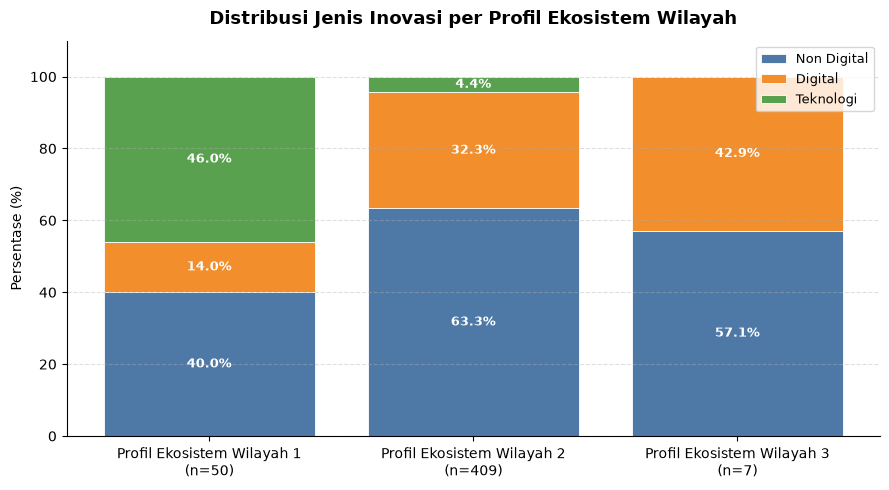

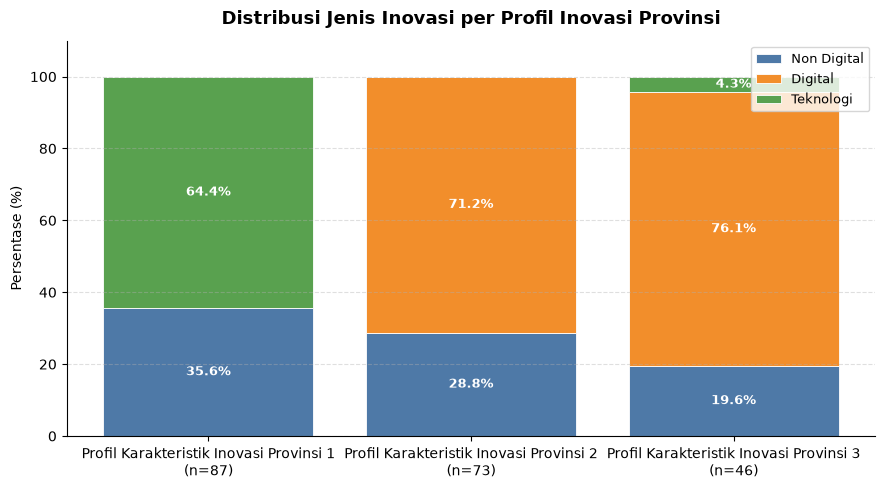

In [21]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# Persiapan data pivot
profil_labels_eko = {
    pid: f"{row['nama_profil']}\n(n={row['jumlah_inovasi']})"
    for _, row in summary_eko.iterrows()
    for pid in [row["profil_id"]]
}

pivot_jenis_eko = weighted_profil_eko_jenis.pivot_table(
    index="profil_id", columns="jenis", values="percentage", fill_value=0
).reindex(profil_eko_ids)
pivot_jenis_eko.index = [profil_labels_eko.get(pid, pid) for pid in pivot_jenis_eko.index]

# Urutan jenis
jenis_cols = [c for c in ["Non Digital", "Digital", "Teknologi"] if c in pivot_jenis_eko.columns]
pivot_jenis_eko = pivot_jenis_eko[jenis_cols]

# Warna
colors_jenis = {"Non Digital": "#4E79A7", "Digital": "#F28E2B", "Teknologi": "#59A14F"}

fig, ax = plt.subplots(figsize=(9, 5))
bottom = np.zeros(len(pivot_jenis_eko))
for col in jenis_cols:
    vals = pivot_jenis_eko[col].values
    bars = ax.bar(pivot_jenis_eko.index, vals, bottom=bottom,
                  label=col, color=colors_jenis.get(col, "#888"),
                  edgecolor="white", linewidth=0.6)
    # Label persen di tengah segment
    for rect, val, bot in zip(bars, vals, bottom):
        if val > 3:
            ax.text(rect.get_x() + rect.get_width()/2,
                    bot + val/2, f"{val:.1f}%",
                    ha="center", va="center", fontsize=9,
                    color="white", fontweight="bold")
    bottom += vals

ax.set_title("Distribusi Jenis Inovasi per Profil Ekosistem Wilayah", fontsize=13, fontweight="bold", pad=12)
ax.set_ylabel("Persentase (%)", fontsize=10)
ax.set_ylim(0, 110)
ax.legend(loc="upper right", fontsize=9, framealpha=0.8)
ax.spines[["top","right"]].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()
print()

# --- Versi Provinsi ---
profil_labels_prov = {
    pid: f"{row['nama_profil']}\n(n={row['jumlah_inovasi']})"
    for _, row in summary_prov.iterrows()
    for pid in [row["profil_id"]]
}

pivot_jenis_prov = wp_jenis.pivot_table(
    index="profil_id", columns="jenis", values="percentage", fill_value=0
).reindex(profil_prov_ids)
pivot_jenis_prov.index = [profil_labels_prov.get(pid, pid) for pid in pivot_jenis_prov.index]
jenis_cols_p = [c for c in ["Non Digital", "Digital", "Teknologi"] if c in pivot_jenis_prov.columns]
pivot_jenis_prov = pivot_jenis_prov[jenis_cols_p]

fig2, ax2 = plt.subplots(figsize=(9, 5))
bottom2 = np.zeros(len(pivot_jenis_prov))
for col in jenis_cols_p:
    vals2 = pivot_jenis_prov[col].values
    bars2 = ax2.bar(pivot_jenis_prov.index, vals2, bottom=bottom2,
                    label=col, color=colors_jenis.get(col, "#888"),
                    edgecolor="white", linewidth=0.6)
    for rect, val, bot in zip(bars2, vals2, bottom2):
        if val > 3:
            ax2.text(rect.get_x() + rect.get_width()/2,
                     bot + val/2, f"{val:.1f}%",
                     ha="center", va="center", fontsize=9,
                     color="white", fontweight="bold")
    bottom2 += vals2

ax2.set_title("Distribusi Jenis Inovasi per Profil Inovasi Provinsi", fontsize=13, fontweight="bold", pad=12)
ax2.set_ylabel("Persentase (%)", fontsize=10)
ax2.set_ylim(0, 110)
ax2.legend(loc="upper right", fontsize=9, framealpha=0.8)
ax2.spines[["top","right"]].set_visible(False)
ax2.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

### Visualisasi 2 — Top Urusan Utama per Profil

Menampilkan 5 urusan utama dengan proporsi tertinggi pada setiap profil ekosistem wilayah (sorted descending).

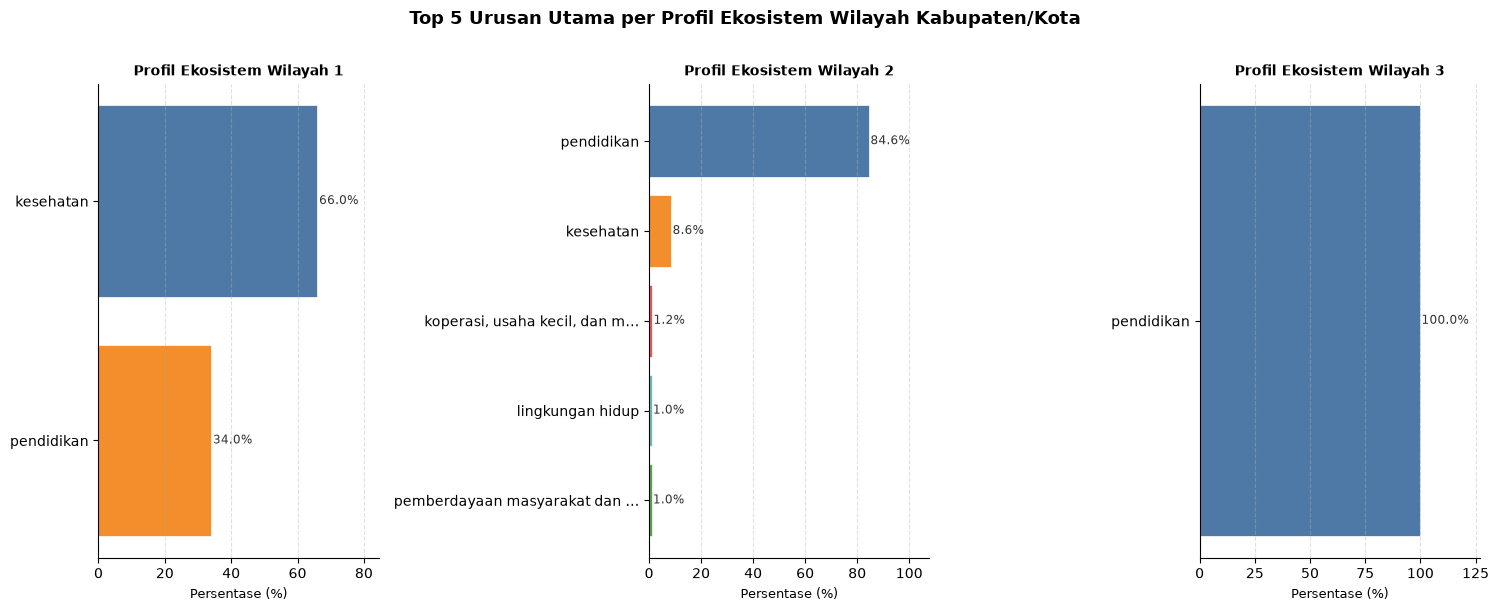

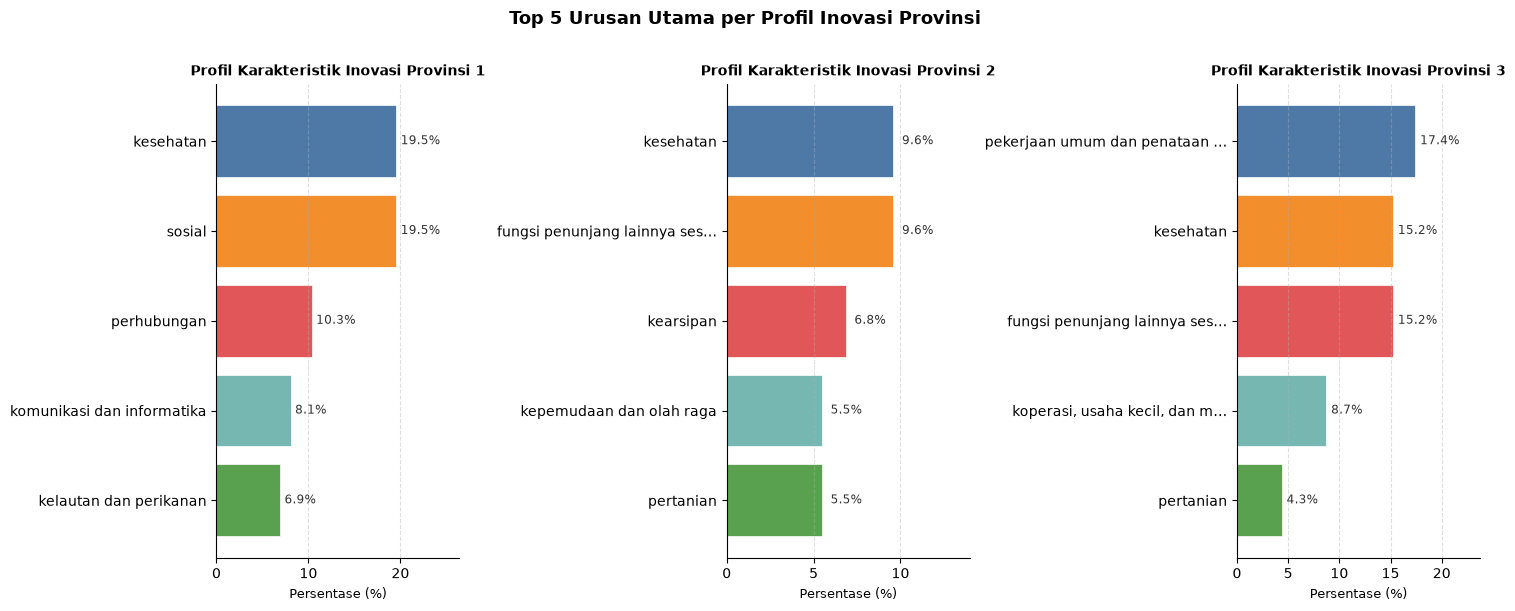

In [22]:
# ==============================================================
# VISUALISASI 2: Top 5 Urusan per Profil Ekosistem
# ==============================================================
top_n = 5
profil_eko_ordered = sorted(profil_eko_ids)

n_profil = len(profil_eko_ordered)
fig, axes = plt.subplots(1, n_profil, figsize=(5 * n_profil, 6), sharey=False)

palette = ["#4E79A7","#F28E2B","#E15759","#76B7B2","#59A14F"]

for ax, pid in zip(axes, profil_eko_ordered):
    sub = weighted_profil_eko_urusan[weighted_profil_eko_urusan["profil_id"] == pid].head(top_n)
    label = f"{nodes_profil_ekosistem.loc[nodes_profil_ekosistem['profil_ekosistem_id']==pid,'nama_profil'].values[0]}"
    # Potong nama urusan panjang
    urusan_labels = [u[:28] + "…" if len(u) > 28 else u for u in sub["urusan"].tolist()]
    bars = ax.barh(urusan_labels, sub["percentage"].values,
                   color=palette[:len(sub)], edgecolor="white", linewidth=0.5)
    for bar, pct in zip(bars, sub["percentage"].values):
        ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
                f"{pct:.1f}%", va="center", fontsize=8.5, color="#333")
    ax.set_title(label, fontsize=10, fontweight="bold")
    ax.set_xlabel("Persentase (%)", fontsize=9)
    ax.invert_yaxis()
    ax.spines[["top","right"]].set_visible(False)
    ax.grid(axis="x", linestyle="--", alpha=0.4)
    ax.set_xlim(0, sub["percentage"].max() * 1.25 + 2)

fig.suptitle("Top 5 Urusan Utama per Profil Ekosistem Wilayah Kabupaten/Kota",
             fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

# --- Profil Provinsi ---
profil_prov_ordered = sorted(profil_prov_ids)
n_prov = len(profil_prov_ordered)
fig2, axes2 = plt.subplots(1, n_prov, figsize=(5 * n_prov, 6), sharey=False)

for ax, pid in zip(axes2, profil_prov_ordered):
    sub = wp_urusan[wp_urusan["profil_id"] == pid].head(top_n)
    label = f"{nodes_profil_inovasi_provinsi.loc[nodes_profil_inovasi_provinsi['profil_provinsi_id']==pid,'nama_profil'].values[0]}"
    urusan_labels = [u[:28] + "…" if len(u) > 28 else u for u in sub["urusan"].tolist()]
    bars = ax.barh(urusan_labels, sub["percentage"].values,
                   color=palette[:len(sub)], edgecolor="white", linewidth=0.5)
    for bar, pct in zip(bars, sub["percentage"].values):
        ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
                f"{pct:.1f}%", va="center", fontsize=8.5, color="#333")
    ax.set_title(label, fontsize=10, fontweight="bold")
    ax.set_xlabel("Persentase (%)", fontsize=9)
    ax.invert_yaxis()
    ax.spines[["top","right"]].set_visible(False)
    ax.grid(axis="x", linestyle="--", alpha=0.4)
    ax.set_xlim(0, sub["percentage"].max() * 1.25 + 2)

fig2.suptitle("Top 5 Urusan Utama per Profil Inovasi Provinsi",
              fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

### Visualisasi 3 — Contoh Weighted Subgraph

Menampilkan satu profil ekosistem pilihan beserta seluruh hubungan berbobot ke kategori Jenis, Urusan, Tahapan, dan Bentuk. Tebal garis merepresentasikan weight relatif.

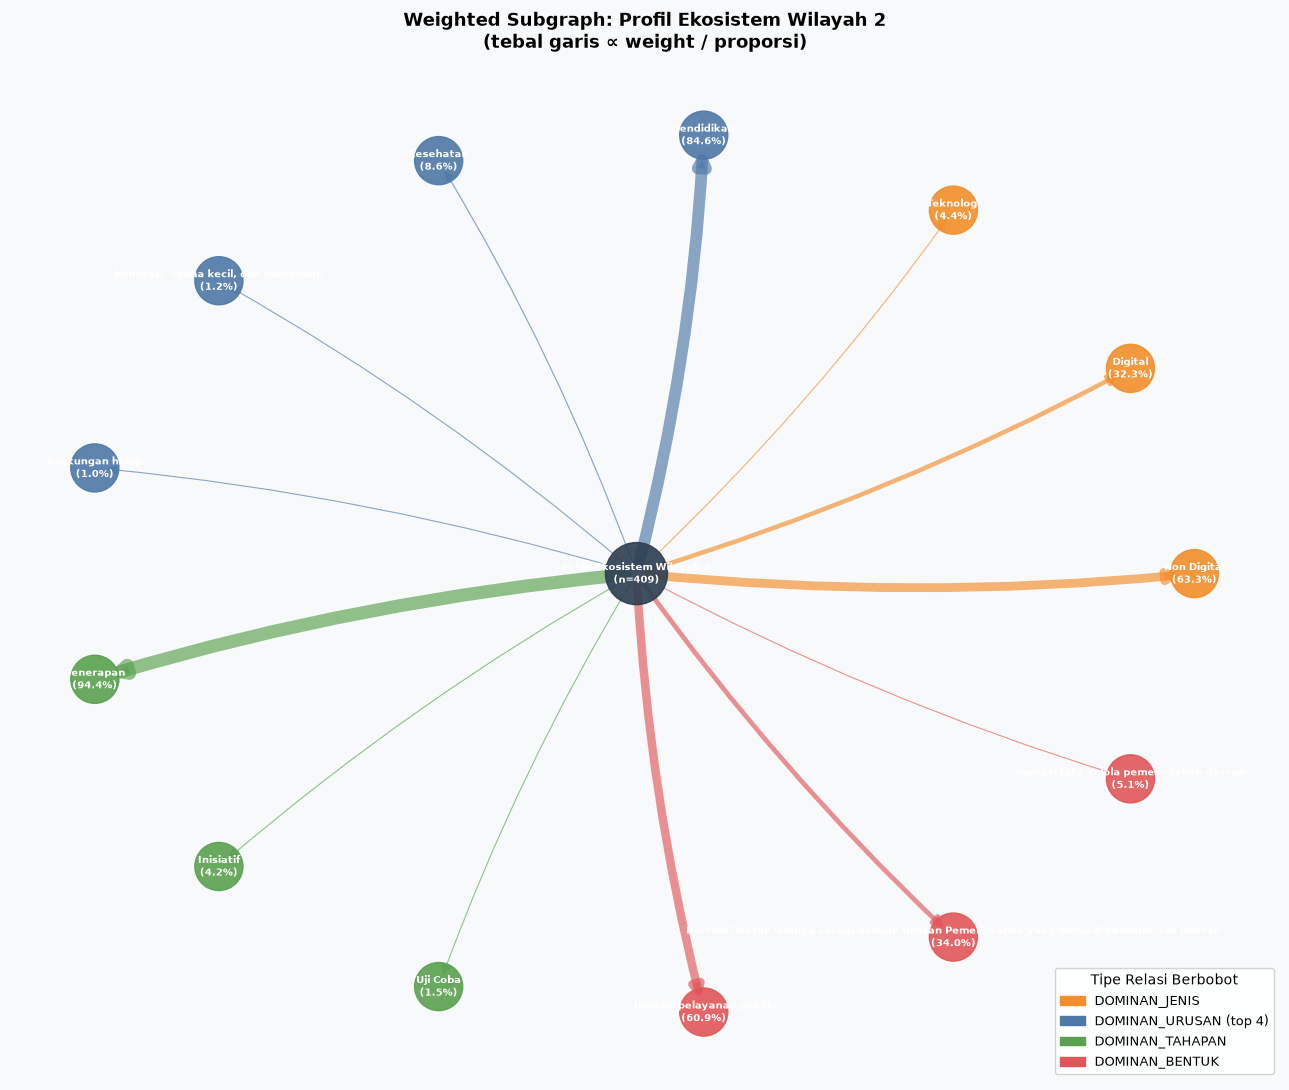

In [23]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.cm as cm

# Gunakan profil dengan jumlah inovasi terbanyak sebagai contoh
target_profil = summary_eko.loc[summary_eko["jumlah_inovasi"].idxmax(), "profil_id"]
target_nama   = summary_eko.loc[summary_eko["jumlah_inovasi"].idxmax(), "nama_profil"]
target_n      = summary_eko.loc[summary_eko["jumlah_inovasi"].idxmax(), "jumlah_inovasi"]

G = nx.DiGraph()

# Node pusat
center_label = f"{target_nama}\n(n={target_n})"
G.add_node(center_label, ntype="profil")

dim_configs = [
    (weighted_profil_eko_jenis,   "jenis",   "DOMINAN_JENIS",    "#F28E2B"),
    (weighted_profil_eko_urusan.groupby("profil_id").head(4), "urusan",  "DOMINAN_URUSAN",   "#4E79A7"),
    (weighted_profil_eko_tahapan, "tahapan", "DOMINAN_TAHAPAN",  "#59A14F"),
    (weighted_profil_eko_bentuk,  "bentuk",  "DOMINAN_BENTUK",   "#E15759"),
]

edge_list = []
color_map_node = {center_label: "#2C3E50"}
for df_w, val_col, rel, color in dim_configs:
    sub = df_w[df_w["profil_id"] == target_profil]
    for _, row in sub.iterrows():
        val = row[val_col]
        pct = row["percentage"]
        node_label = f"{val}\n({pct:.1f}%)"
        G.add_node(node_label, ntype=rel)
        G.add_edge(center_label, node_label, weight=row["weight"], rel=rel)
        edge_list.append((center_label, node_label, row["weight"], color))
        color_map_node[node_label] = color

# Layout manual: center + ring
pos = {center_label: (0, 0)}
n_nodes = G.number_of_nodes() - 1
import math
for i, node in enumerate([n for n in G.nodes() if n != center_label]):
    angle = 2 * math.pi * i / n_nodes
    r = 2.8
    pos[node] = (r * math.cos(angle), r * math.sin(angle))

fig, ax = plt.subplots(figsize=(13, 11))
ax.set_facecolor("#F8F9FA")
fig.patch.set_facecolor("#F8F9FA")

node_colors = [color_map_node.get(n, "#AAA") for n in G.nodes()]
node_sizes  = [2000 if n == center_label else 1200 for n in G.nodes()]

nx.draw_networkx_nodes(G, pos, ax=ax, node_color=node_colors,
                       node_size=node_sizes, alpha=0.9)
nx.draw_networkx_labels(G, pos, ax=ax, font_size=7.5,
                        font_color="white", font_weight="bold")

# Gambar edge dengan ketebalan proporsional
for src, tgt, w, color in edge_list:
    lw = max(0.8, w * 10)
    nx.draw_networkx_edges(G, pos, edgelist=[(src, tgt)], ax=ax,
                           width=lw, edge_color=color, alpha=0.65,
                           arrows=True, arrowsize=15,
                           connectionstyle="arc3,rad=0.05")

# Legend
legend_items = [
    mpatches.Patch(color="#F28E2B", label="DOMINAN_JENIS"),
    mpatches.Patch(color="#4E79A7", label="DOMINAN_URUSAN (top 4)"),
    mpatches.Patch(color="#59A14F", label="DOMINAN_TAHAPAN"),
    mpatches.Patch(color="#E15759", label="DOMINAN_BENTUK"),
]
ax.legend(handles=legend_items, loc="lower right", fontsize=9,
          framealpha=0.85, title="Tipe Relasi Berbobot")
ax.set_title(f"Weighted Subgraph: {target_nama}\n(tebal garis ∝ weight / proporsi)",
             fontsize=13, fontweight="bold", pad=14)
ax.axis("off")
plt.tight_layout()
plt.show()

---

## Visualisasi Tambahan STEP 2 — KG Relationship Overview

Menampilkan subgraph Knowledge Graph faktual menggunakan beberapa contoh inovasi. Tujuannya bukan menampilkan seluruh 679 node, melainkan menunjukkan struktur hubungan multi-level: Inovasi → OPD, Daerah, Profil Ekosistem, Jenis, Urusan, dan Tahapan.

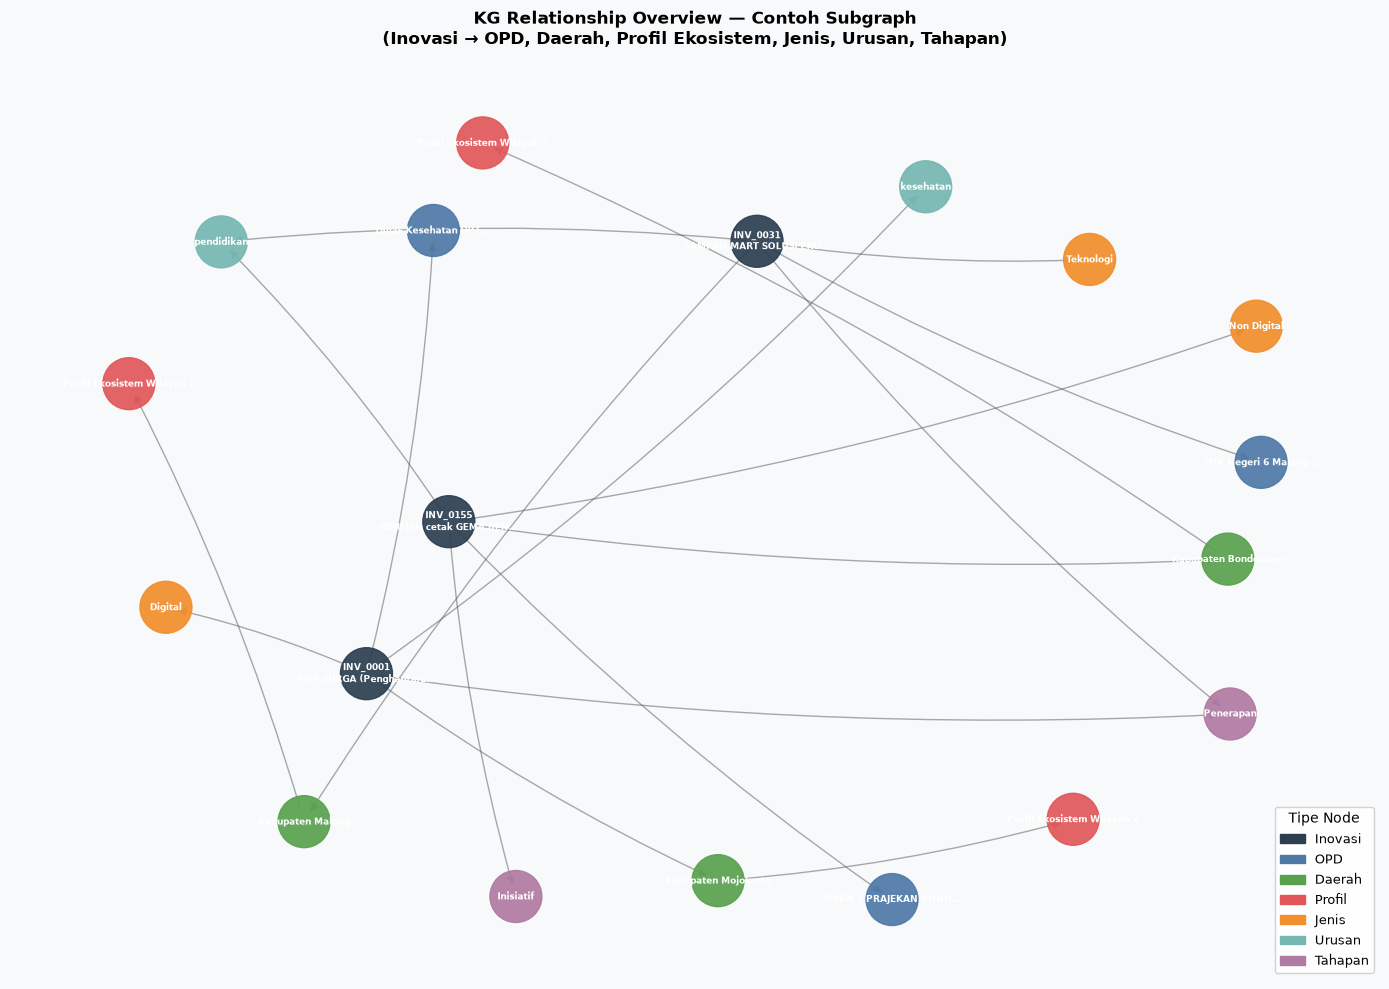

In [24]:
# ==============================================================
# KG RELATIONSHIP OVERVIEW — SUBGRAPH CONTOH
# ==============================================================
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Pilih 4 inovasi contoh dari profil yang berbeda
sample_inv_ids = []
for pid in profil_eko_ids[:3]:
    # Ambil 1-2 inovasi per profil
    match = [f"INV_{i+1:04d}" for i, r in kg_source_df.iterrows()
             if r.get("Jenis_Cluster") == "Cluster_Wilayah"
             and int(r["Cluster"]) == nodes_profil_ekosistem.loc[
                 nodes_profil_ekosistem["profil_ekosistem_id"]==pid, "source_cluster_id"].values[0]]
    sample_inv_ids.extend(match[:1])

G2 = nx.DiGraph()

node_colors2 = {}

def add_node(G, label, ntype, color):
    G.add_node(label, ntype=ntype)
    node_colors2[label] = color

type_color = {
    "Inovasi"  : "#2C3E50",
    "OPD"      : "#4E79A7",
    "Daerah"   : "#59A14F",
    "Profil"   : "#E15759",
    "Jenis"    : "#F28E2B",
    "Urusan"   : "#76B7B2",
    "Tahapan"  : "#B07AA1",
}

for inv_id in sample_inv_ids:
    row_inv = nodes_inovasi[nodes_inovasi["inovasi_id"] == inv_id].iloc[0]
    # Potong judul
    judul_short = row_inv["judul_inovasi"][:22] + "…" if len(row_inv["judul_inovasi"]) > 22 else row_inv["judul_inovasi"]
    inv_label = f"{inv_id}\n{judul_short}"
    add_node(G2, inv_label, "Inovasi", type_color["Inovasi"])

    # OPD
    opd_edge = edges_dikelola_oleh[edges_dikelola_oleh["source_id"] == inv_id]
    if not opd_edge.empty:
        opd_id_val = opd_edge.iloc[0]["target_id"]
        opd_nama = nodes_opd[nodes_opd["opd_id"]==opd_id_val]["nama_opd"].values
        if len(opd_nama):
            opd_l = opd_nama[0][:20]+"…" if len(opd_nama[0])>20 else opd_nama[0]
            add_node(G2, opd_l, "OPD", type_color["OPD"])
            G2.add_edge(inv_label, opd_l, rel="DIKELOLA_OLEH")

    # Daerah
    d_edge = edges_berada_di[edges_berada_di["source_id"] == inv_id]
    if not d_edge.empty:
        d_id_val = d_edge.iloc[0]["target_id"]
        d_nama = nodes_daerah[nodes_daerah["daerah_id"]==d_id_val]["nama_daerah"].values
        if len(d_nama):
            add_node(G2, d_nama[0], "Daerah", type_color["Daerah"])
            G2.add_edge(inv_label, d_nama[0], rel="BERADA_DI")

            # Profil Ekosistem via Daerah
            prof_edge = edges_profil_ekosistem[edges_profil_ekosistem["source_id"]==d_id_val]
            if not prof_edge.empty:
                prof_id_val = prof_edge.iloc[0]["target_id"]
                prof_nama = nodes_profil_ekosistem[
                    nodes_profil_ekosistem["profil_ekosistem_id"]==prof_id_val]["nama_profil"].values
                if len(prof_nama):
                    pn = prof_nama[0]
                    add_node(G2, pn, "Profil", type_color["Profil"])
                    G2.add_edge(d_nama[0], pn, rel="TERMASUK_PROFIL_EKOSISTEM")

    # Jenis
    j_edge = edges_berjenis[edges_berjenis["source_id"] == inv_id]
    if not j_edge.empty:
        j_id_val = j_edge.iloc[0]["target_id"]
        j_nama = nodes_jenis[nodes_jenis["jenis_id"]==j_id_val]["nama_jenis"].values
        if len(j_nama):
            add_node(G2, j_nama[0], "Jenis", type_color["Jenis"])
            G2.add_edge(inv_label, j_nama[0], rel="BERJENIS")

    # Urusan Utama
    u_edge = edges_menangani_urusan[edges_menangani_urusan["source_id"] == inv_id]
    if not u_edge.empty:
        u_id_val = u_edge.iloc[0]["target_id"]
        u_nama = nodes_urusan[nodes_urusan["urusan_id"]==u_id_val]["nama_urusan"].values
        if len(u_nama):
            u_short = u_nama[0][:20]+"…" if len(u_nama[0])>20 else u_nama[0]
            add_node(G2, u_short, "Urusan", type_color["Urusan"])
            G2.add_edge(inv_label, u_short, rel="MENANGANI_URUSAN")

    # Tahapan
    t_edge = edges_tahapan[edges_tahapan["source_id"] == inv_id]
    if not t_edge.empty:
        t_id_val = t_edge.iloc[0]["target_id"]
        t_nama = nodes_tahapan[nodes_tahapan["tahapan_id"]==t_id_val]["nama_tahapan"].values
        if len(t_nama):
            add_node(G2, t_nama[0], "Tahapan", type_color["Tahapan"])
            G2.add_edge(inv_label, t_nama[0], rel="BERADA_DI_TAHAPAN")

pos2 = nx.spring_layout(G2, seed=42, k=2.2)

fig3, ax3 = plt.subplots(figsize=(14, 10))
ax3.set_facecolor("#F8F9FA")
fig3.patch.set_facecolor("#F8F9FA")

n_colors = [node_colors2.get(n, "#888") for n in G2.nodes()]
nx.draw_networkx_nodes(G2, pos2, ax=ax3, node_color=n_colors,
                       node_size=1400, alpha=0.92)
nx.draw_networkx_labels(G2, pos2, ax=ax3, font_size=6.5,
                        font_color="white", font_weight="bold")
nx.draw_networkx_edges(G2, pos2, ax=ax3, edge_color="#555",
                       alpha=0.5, arrows=True, arrowsize=12,
                       connectionstyle="arc3,rad=0.05")

legend_items2 = [mpatches.Patch(color=v, label=k) for k,v in type_color.items()]
ax3.legend(handles=legend_items2, loc="lower right", fontsize=9,
           framealpha=0.88, title="Tipe Node")
ax3.set_title("KG Relationship Overview — Contoh Subgraph\n(Inovasi → OPD, Daerah, Profil Ekosistem, Jenis, Urusan, Tahapan)",
              fontsize=12, fontweight="bold", pad=14)
ax3.axis("off")
plt.tight_layout()
plt.show()

---

# STEP 3 CHECKPOINT — WEIGHTED GRAPH ANALYTICS

## 1. Tabel Weighted Relationship

Seluruh edge agregatif tersimpan dalam `weighted_edges` dengan format:

| Kolom | Keterangan |
|---|---|
| `source_id` | ID node profil (ProfilEkosistem / ProfilProvinsi) |
| `source_type` | Tipe node asal |
| `relationship` | `DOMINAN_JENIS` / `DOMINAN_URUSAN` / `DOMINAN_TAHAPAN` / `DOMINAN_BENTUK` |
| `target_id` | ID node karakteristik |
| `target_type` | Tipe node tujuan |
| `weight` | Proporsi (0–1), tidak dibulatkan |
| `count` | Jumlah inovasi dengan karakteristik tersebut |
| `total` | Total inovasi dalam profil |
| `percentage` | `weight × 100`, dibulatkan 2 desimal |

---

## 2. Contoh Perhitungan Weight

Contoh: `PROFILE_EKO_02` memiliki 409 inovasi dari Cluster_Wilayah 2.

Jika 150 inovasi berjenis "Non Digital":

```
weight(PROFILE_EKO_02, Non Digital) = 150 / 409 = 0.3667...
percentage = 36.67%
```

Perhitungan dilakukan langsung dari data tanpa pembulatan selama proses.

---

## 3. Validasi Sum Weight

Untuk setiap profil, `sum(weight)` atas seluruh kategori dalam satu dimensi = 1.0 (toleransi 1e-9).  
Lihat output cell validasi di atas.

---

## 4. Profil dengan Karakteristik Dominan

Lihat tabel `profil_weight_summary` di atas.  
Karakteristik dominan menunjukkan distribusi mayoritas — bukan penilaian kualitas profil.

---

## 5. Visualisasi Distribusi

- **Visualisasi 1**: Stacked bar distribusi Jenis per profil (Ekosistem & Provinsi)
- **Visualisasi 2**: Horizontal bar Top-5 Urusan per profil
- **Visualisasi 3**: Weighted subgraph satu profil dengan tebal edge ∝ weight

---

## 6. Contoh Weighted Subgraph

Lihat Visualisasi 3 di atas. Profil dengan inovasi terbanyak dipilih sebagai contoh representatif.

---

## 7. Asal-usul Weight

> Weighted relationship digunakan secara selektif pada hubungan agregatif untuk merepresentasikan dominansi karakteristik berdasarkan proporsi data. Relationship faktual tetap tidak diberi bobot.

Tidak ada satu pun nilai weight yang ditentukan secara manual atau subjektif. Seluruh bobot berasal dari perhitungan frekuensi relatif dalam data clustering final.

In [25]:
# ==============================================================
# CHECKPOINT: Ringkasan weighted_edges
# ==============================================================
print("=== RINGKASAN weighted_edges ===\n")
summary_we = (
    weighted_edges
    .groupby(["source_type", "relationship"])
    .agg(total_edge=("weight","count"),
         avg_weight=("weight","mean"),
         min_weight=("weight","min"),
         max_weight=("weight","max"))
    .round(4)
    .reset_index()
)
display(summary_we)

print(f"\nTotal weighted_edges : {len(weighted_edges)}")
print(f"Source types         : {sorted(weighted_edges['source_type'].unique())}")
print(f"Relationship types   : {sorted(weighted_edges['relationship'].unique())}")
print()
print("=== 10 Edge dengan Weight Tertinggi ===")
display(weighted_edges.sort_values("weight", ascending=False).head(10))

=== RINGKASAN weighted_edges ===



,source_type,relationship,total_edge,avg_weight,min_weight,max_weight
0,ProfilEkosistem,DOMINAN_BENTUK,8,0.3750,0.0400,0.9000
1,ProfilEkosistem,DOMINAN_JENIS,8,0.3750,0.0440,0.6333
2,ProfilEkosistem,DOMINAN_TAHAPAN,6,0.5000,0.0147,1.0000
3,ProfilEkosistem,DOMINAN_URUSAN,18,0.1667,0.0024,1.0000
4,ProfilProvinsi,DOMINAN_BENTUK,9,0.3333,0.0575,0.8276
5,ProfilProvinsi,DOMINAN_JENIS,7,0.4286,0.0435,0.7609
6,ProfilProvinsi,DOMINAN_TAHAPAN,5,0.6000,0.0115,1.0000
7,ProfilProvinsi,DOMINAN_URUSAN,60,0.0500,0.0115,0.1954



Total weighted_edges : 121
Source types         : ['ProfilEkosistem', 'ProfilProvinsi']
Relationship types   : ['DOMINAN_BENTUK', 'DOMINAN_JENIS', 'DOMINAN_TAHAPAN', 'DOMINAN_URUSAN']

=== 10 Edge dengan Weight Tertinggi ===


,source_id,source_type,relationship,target_id,target_type,weight,count,total,percentage
25,PROFILE_EKO_03,ProfilEkosistem,DOMINAN_URUSAN,URUSAN_027,Urusan,1.000000,7,7,100.00
26,PROFILE_EKO_01,ProfilEkosistem,DOMINAN_TAHAPAN,TAHAPAN_02,Tahapan,1.000000,50,50,100.00
109,PROFILE_PROV_02,ProfilProvinsi,DOMINAN_TAHAPAN,TAHAPAN_02,Tahapan,1.000000,73,73,100.00
107,PROFILE_PROV_01,ProfilProvinsi,DOMINAN_TAHAPAN,TAHAPAN_02,Tahapan,0.988506,86,87,98.85
110,PROFILE_PROV_03,ProfilProvinsi,DOMINAN_TAHAPAN,TAHAPAN_02,Tahapan,0.978261,45,46,97.83
27,PROFILE_EKO_02,ProfilEkosistem,DOMINAN_TAHAPAN,TAHAPAN_02,Tahapan,0.943765,386,409,94.38
32,PROFILE_EKO_01,ProfilEkosistem,DOMINAN_BENTUK,BENTUK_02,Bentuk,0.900000,45,50,90.00
38,PROFILE_EKO_03,ProfilEkosistem,DOMINAN_BENTUK,BENTUK_02,Bentuk,0.857143,6,7,85.71
10,PROFILE_EKO_02,ProfilEkosistem,DOMINAN_URUSAN,URUSAN_027,Urusan,0.845966,346,409,84.60
112,PROFILE_PROV_01,ProfilProvinsi,DOMINAN_BENTUK,BENTUK_02,Bentuk,0.827586,72,87,82.76


---

## STEP 4 — Build Knowledge Graph dan Graph Traversal

Pada tahap ini seluruh entitas, relationship faktual (STEP 2), dan weighted relationship (STEP 3) digabungkan ke dalam satu objek graph menggunakan `networkx.MultiDiGraph`.

Hasilnya adalah Knowledge Graph aktual yang bisa:
- ditelusuri dari satu node ke node lainnya (traversal),
- di-query secara multi-hop (misal: inovasi Digital di daerah yang masuk Profil Ekosistem tertentu),
- digunakan untuk analisis struktur maupun distribusi berbobot.

Tidak ada LLM, embedding, atau RAG di sini. Semua operasi berbasis graph traversal biasa.

---

### Skema Node Type

| Node Type | Sumber |
|---|---|
| `Inovasi` | `nodes_inovasi` |
| `AdminOPD` | `nodes_opd` |
| `Daerah` | `nodes_daerah` |
| `ProfilEkosistemInovasi` | `nodes_profil_ekosistem` |
| `ProfilKarakteristikInovasi` | `nodes_profil_inovasi_provinsi` |
| `Jenis` | `nodes_jenis` |
| `BentukInovasi` | `nodes_bentuk` |
| `AstaCipta` | `nodes_asta_cipta` |
| `Urusan` | `nodes_urusan` |
| `Tahapan` | `nodes_tahapan` |

### 4.1 — Tambah Node ke Graph

Setiap node dimasukkan beserta seluruh properti yang tersedia dari tabel entitas STEP 1. Property `type` ditambahkan untuk membedakan node berdasarkan kategori.

In [26]:
import networkx as nx

# ==============================================================
# INISIALISASI GRAPH
# ==============================================================
G = nx.MultiDiGraph()

# --------------------------------------------------------------
# 1. Inovasi
# --------------------------------------------------------------
for _, row in nodes_inovasi.iterrows():
    G.add_node(
        row["inovasi_id"],
        type="Inovasi",
        judul_inovasi     = row["judul_inovasi"],
        kematangan        = row["kematangan"],
        tanggal_input     = row["tanggal_input"],
        tanggal_penerapan = row["tanggal_penerapan"],
        inisiator         = row["inisiator"],
        daerah            = row["daerah"],
        jenis_wilayah     = row["jenis_wilayah"],
        jenis_cluster     = row["jenis_cluster"],
        cluster           = row["cluster"],
        tingkat_kematangan= row["tingkat_kematangan"],
        admin_opd         = row["admin_opd"],
        bentuk_inovasi    = row["bentuk_inovasi"],
        jenis             = row["jenis"],
        asta_cipta        = row["asta_cipta"],
        tahapan_inovasi   = row["tahapan_inovasi"],
    )

# --------------------------------------------------------------
# 2. Admin OPD
# --------------------------------------------------------------
for _, row in nodes_opd.iterrows():
    G.add_node(row["opd_id"], type="AdminOPD", nama_opd=row["nama_opd"])

# --------------------------------------------------------------
# 3. Daerah
# --------------------------------------------------------------
for _, row in nodes_daerah.iterrows():
    G.add_node(
        row["daerah_id"],
        type        = "Daerah",
        nama_daerah = row["nama_daerah"],
        level_daerah= row["level_daerah"],
    )

# --------------------------------------------------------------
# 4. Profil Ekosistem Inovasi (Wilayah)
# --------------------------------------------------------------
for _, row in nodes_profil_ekosistem.iterrows():
    G.add_node(
        row["profil_ekosistem_id"],
        type               = "ProfilEkosistemInovasi",
        nama_profil        = row["nama_profil"],
        jenis_cluster      = row["jenis_cluster"],
        source_cluster_id  = row["source_cluster_id"],
        tingkat_kematangan = row["tingkat_kematangan"],
    )

# --------------------------------------------------------------
# 5. Profil Karakteristik Inovasi (Provinsi)
# --------------------------------------------------------------
for _, row in nodes_profil_inovasi_provinsi.iterrows():
    G.add_node(
        row["profil_provinsi_id"],
        type               = "ProfilKarakteristikInovasi",
        nama_profil        = row["nama_profil"],
        jenis_cluster      = row["jenis_cluster"],
        source_cluster_id  = row["source_cluster_id"],
        tingkat_kematangan = row["tingkat_kematangan"],
    )

# --------------------------------------------------------------
# 6. Jenis
# --------------------------------------------------------------
for _, row in nodes_jenis.iterrows():
    G.add_node(row["jenis_id"], type="Jenis", nama_jenis=row["nama_jenis"])

# --------------------------------------------------------------
# 7. Bentuk Inovasi
# --------------------------------------------------------------
for _, row in nodes_bentuk.iterrows():
    G.add_node(row["bentuk_id"], type="BentukInovasi", nama_bentuk=row["nama_bentuk"])

# --------------------------------------------------------------
# 8. Asta Cipta
# --------------------------------------------------------------
for _, row in nodes_asta_cipta.iterrows():
    G.add_node(row["asta_cipta_id"], type="AstaCipta", nama_asta_cipta=row["nama_asta_cipta"])

# --------------------------------------------------------------
# 9. Urusan
# --------------------------------------------------------------
for _, row in nodes_urusan.iterrows():
    G.add_node(
        row["urusan_id"],
        type        = "Urusan",
        nama_urusan = row["nama_urusan"],
        jenis_urusan= row["jenis_urusan"],
    )

# --------------------------------------------------------------
# 10. Tahapan
# --------------------------------------------------------------
for _, row in nodes_tahapan.iterrows():
    G.add_node(row["tahapan_id"], type="Tahapan", nama_tahapan=row["nama_tahapan"])

print(f"Total node dalam G : {G.number_of_nodes():>5}")
print()
type_count = {}
for nid, data in G.nodes(data=True):
    t = data.get("type","?")
    type_count[t] = type_count.get(t, 0) + 1
for t, c in sorted(type_count.items()):
    print(f"  {t:<35}: {c:>5} node")

Total node dalam G :  1073

  AdminOPD                           :   292 node
  AstaCipta                          :     8 node
  BentukInovasi                      :     3 node
  Daerah                             :    36 node
  Inovasi                            :   679 node
  Jenis                              :     3 node
  ProfilEkosistemInovasi             :     3 node
  ProfilKarakteristikInovasi         :     3 node
  Tahapan                            :     3 node
  Urusan                             :    43 node


### 4.2 — Tambah Edge ke Graph

Seluruh relationship dari STEP 2 (faktual, tanpa weight) dan STEP 3 (`weighted_edges`) dimasukkan ke graph. Keduanya disimpan sebagai edge berbeda pada `MultiDiGraph`.

In [27]:
# ==============================================================
# TAMBAH EDGE FAKTUAL (STEP 2) — tanpa weight
# ==============================================================

factual_edge_tables = [
    (edges_dikelola_oleh,    "DIKELOLA_OLEH"),
    (edges_berada_di,        "BERADA_DI"),
    (edges_berjenis,         "BERJENIS"),
    (edges_berbentuk,        "BERBENTUK"),
    (edges_berpilar,         "BERPILAR"),
    (edges_menangani_urusan, "MENANGANI_URUSAN"),
    (edges_bersinggungan,    "BERSINGGUNGAN_DENGAN"),
    (edges_tahapan,          "BERADA_DI_TAHAPAN"),
    (edges_profil_ekosistem, "TERMASUK_PROFIL_EKOSISTEM"),
    (edges_dicirikan_profil, "DICIRIKAN_PROFIL"),
]

n_factual = 0
for df_edge, rel in factual_edge_tables:
    for _, row in df_edge.iterrows():
        G.add_edge(
            row["source_id"],
            row["target_id"],
            relation = rel,
            weighted = False,
        )
        n_factual += 1

print(f"Edge faktual ditambahkan  : {n_factual:>5}")

# ==============================================================
# TAMBAH WEIGHTED EDGE (STEP 3) — dengan weight
# ==============================================================
n_weighted = 0
for _, row in weighted_edges.iterrows():
    G.add_edge(
        row["source_id"],
        row["target_id"],
        relation     = row["relationship"],
        weighted     = True,
        weight       = row["weight"],
        count        = row["count"],
        total        = row["total"],
        percentage   = row["percentage"],
        source_type  = row["source_type"],
        target_type  = row["target_type"],
    )
    n_weighted += 1

print(f"Edge weighted ditambahkan : {n_weighted:>5}")
print(f"Total edge dalam G        : {G.number_of_edges():>5}")

Edge faktual ditambahkan  :  5696
Edge weighted ditambahkan :   121
Total edge dalam G        :  5817


### 4.3 — Statistik Graph

In [28]:
# ==============================================================
# GRAPH STATISTICS
# ==============================================================

print("=" * 55)
print("  KNOWLEDGE GRAPH STATISTICS")
print("=" * 55)
print(f"  Total node : {G.number_of_nodes():>6}")
print(f"  Total edge : {G.number_of_edges():>6}")
print()

# Node per type
print("  Node Distribution:")
type_count = {}
for nid, data in G.nodes(data=True):
    t = data.get("type","?")
    type_count[t] = type_count.get(t, 0) + 1
for t, c in sorted(type_count.items()):
    print(f"    {t:<38}: {c:>5}")

print()

# Edge per relation
print("  Edge Distribution:")
rel_count = {}
for u, v, data in G.edges(data=True):
    r = data.get("relation","?")
    rel_count[r] = rel_count.get(r, 0) + 1
for r, c in sorted(rel_count.items()):
    tag = " [weighted]" if r.startswith("DOMINAN") else " [faktual] "
    print(f"    {r:<35}{tag}: {c:>5}")

print()
n_w  = sum(1 for u,v,d in G.edges(data=True) if d.get("weighted"))
n_uw = sum(1 for u,v,d in G.edges(data=True) if not d.get("weighted"))
print(f"  Weighted edge   : {n_w:>5}")
print(f"  Unweighted edge : {n_uw:>5}")
print("=" * 55)

# Assertion
assert type_count.get("Inovasi", 0) == 679,     f"Jumlah node Inovasi {type_count.get('Inovasi',0)} != 679!"
assert type_count.get("AdminOPD", 0) == len(nodes_opd), "OPD count mismatch!"
assert type_count.get("Daerah",   0) == len(nodes_daerah), "Daerah count mismatch!"
assert type_count.get("ProfilEkosistemInovasi", 0) == len(nodes_profil_ekosistem)
assert type_count.get("ProfilKarakteristikInovasi", 0) == len(nodes_profil_inovasi_provinsi)

print()
print("Semua assertion node count lolos.")

  KNOWLEDGE GRAPH STATISTICS
  Total node :   1073
  Total edge :   5817

  Node Distribution:
    AdminOPD                              :   292
    AstaCipta                             :     8
    BentukInovasi                         :     3
    Daerah                                :    36
    Inovasi                               :   679
    Jenis                                 :     3
    ProfilEkosistemInovasi                :     3
    ProfilKarakteristikInovasi            :     3
    Tahapan                               :     3
    Urusan                                :    43

  Edge Distribution:
    BERADA_DI                           [faktual] :   678
    BERADA_DI_TAHAPAN                   [faktual] :   679
    BERBENTUK                           [faktual] :   679
    BERJENIS                            [faktual] :   679
    BERPILAR                            [faktual] :   587
    BERSINGGUNGAN_DENGAN                [faktual] :   795
    DICIRIKAN_PROFIL               

### 4.4 — Validasi Integritas Graph

Memastikan tidak ada dangling edge, tidak ada hubungan langsung `Inovasi → ProfilEkosistemInovasi`, dan tidak ada self-loop tidak semestinya.

In [29]:
# ==============================================================
# VALIDASI INTEGRITAS GRAPH
# ==============================================================

all_nodes = set(G.nodes())
errors = []

print("=== GRAPH INTEGRITY CHECK ===\n")

# 1. Semua source dan target ada di graph
for u, v, d in G.edges(data=True):
    if u not in all_nodes:
        errors.append(f"Source tidak ada di graph: {u}")
    if v not in all_nodes:
        errors.append(f"Target tidak ada di graph: {v}")

if errors:
    print(f"[FAIL] Ditemukan {len(errors)} dangling edge:")
    for e in errors[:5]: print(f"  {e}")
else:
    print("[OK] Tidak ada dangling edge.")

# 2. Tidak ada Inovasi → ProfilEkosistemInovasi secara langsung
direct_inv_profil = [
    (u, v) for u, v, d in G.edges(data=True)
    if G.nodes[u].get("type") == "Inovasi"
    and G.nodes[v].get("type") == "ProfilEkosistemInovasi"
]
if direct_inv_profil:
    print(f"[FAIL] Ditemukan {len(direct_inv_profil)} edge langsung Inovasi→ProfilEkosistemInovasi!")
else:
    print("[OK] Tidak ada edge langsung Inovasi → ProfilEkosistemInovasi.")

# 3. ProfilEkosistemInovasi hanya dari clustering wilayah
for nid, data in G.nodes(data=True):
    if data.get("type") == "ProfilEkosistemInovasi":
        if data.get("jenis_cluster") != "Cluster_Wilayah":
            errors.append(f"ProfilEkosistemInovasi {nid} bukan dari Cluster_Wilayah!")

# 4. ProfilKarakteristikInovasi hanya dari clustering Provinsi
for nid, data in G.nodes(data=True):
    if data.get("type") == "ProfilKarakteristikInovasi":
        if data.get("jenis_cluster") != "Cluster_Inovasi_Provinsi":
            errors.append(f"ProfilKarakteristikInovasi {nid} bukan dari Cluster_Inovasi_Provinsi!")

if not errors:
    print("[OK] Semua node ProfilEkosistemInovasi berasal dari Cluster_Wilayah.")
    print("[OK] Semua node ProfilKarakteristikInovasi berasal dari Cluster_Inovasi_Provinsi.")

# 5. Self-loop check
self_loops = [(u,v) for u,v in G.edges() if u == v]
if self_loops:
    print(f"[WARN] Ditemukan {len(self_loops)} self-loop.")
else:
    print("[OK] Tidak ada self-loop.")

# 6. Cek jalur Inovasi → Daerah → ProfilEkosistemInovasi (harus bisa)
sample_inv = list(nodes_inovasi[nodes_inovasi["daerah"].notna()]["inovasi_id"])[0]
daerah_neighbors = [v for u,v,d in G.out_edges(sample_inv, data=True) if d.get("relation")=="BERADA_DI"]
profil_reachable = []
for d_id in daerah_neighbors:
    for u2,v2,d2 in G.out_edges(d_id, data=True):
        if d2.get("relation") == "TERMASUK_PROFIL_EKOSISTEM":
            profil_reachable.append(v2)
if profil_reachable:
    print(f"[OK] Inovasi {sample_inv} → Daerah → ProfilEkosistemInovasi: {profil_reachable}")
else:
    print(f"[INFO] Inovasi {sample_inv} tidak memiliki jalur ke ProfilEkosistemInovasi (mungkin Provinsi).")

print()
if not errors:
    print("Semua validasi integritas graph lolos.")
else:
    print(f"Ditemukan {len(errors)} masalah integritas:")
    for e in errors: print(f"  {e}")

=== GRAPH INTEGRITY CHECK ===

[OK] Tidak ada dangling edge.
[OK] Tidak ada edge langsung Inovasi → ProfilEkosistemInovasi.
[OK] Semua node ProfilEkosistemInovasi berasal dari Cluster_Wilayah.
[OK] Semua node ProfilKarakteristikInovasi berasal dari Cluster_Inovasi_Provinsi.
[OK] Tidak ada self-loop.
[OK] Inovasi INV_0001 → Daerah → ProfilEkosistemInovasi: ['PROFILE_EKO_02']

Semua validasi integritas graph lolos.


### 4.5 — Helper Functions

Kumpulan fungsi utilitas untuk query graph tanpa harus menulis traversal manual setiap kali.

In [30]:
# ==============================================================
# HELPER FUNCTIONS
# ==============================================================

def get_node(node_id):
    """Kembalikan properti node berdasarkan ID-nya."""
    if node_id not in G:
        return None
    return {"id": node_id, **G.nodes[node_id]}


def get_neighbors(node_id, direction="out"):
    """
    Kembalikan daftar (neighbor_id, relation) untuk node_id.
    direction: 'out' (keluar), 'in' (masuk), 'both'.
    """
    result = []
    if direction in ("out", "both"):
        for u, v, data in G.out_edges(node_id, data=True):
            result.append({
                "direction" : "→",
                "node_id"   : v,
                "type"      : G.nodes[v].get("type","?"),
                "relation"  : data.get("relation","?"),
                "weighted"  : data.get("weighted", False),
                "weight"    : data.get("weight"),
            })
    if direction in ("in", "both"):
        for u, v, data in G.in_edges(node_id, data=True):
            result.append({
                "direction" : "←",
                "node_id"   : u,
                "type"      : G.nodes[u].get("type","?"),
                "relation"  : data.get("relation","?"),
                "weighted"  : data.get("weighted", False),
                "weight"    : data.get("weight"),
            })
    return result


def get_relationships(node_id):
    """Ringkasan semua relasi yang dimiliki node_id."""
    rels = {}
    for nb_info in get_neighbors(node_id, direction="both"):
        r = nb_info["relation"]
        rels[r] = rels.get(r, 0) + 1
    return rels


def find_nodes_by_type(node_type):
    """Kembalikan daftar ID node berdasarkan type."""
    return [nid for nid, data in G.nodes(data=True) if data.get("type") == node_type]


def find_innovations_by_jenis(jenis_str):
    """Cari inovasi berdasarkan nilai Jenis (Digital/Non Digital/Teknologi)."""
    jenis_id = jenis_to_id.get(jenis_str)
    if not jenis_id:
        return []
    return [u for u, v, d in G.in_edges(jenis_id, data=True) if d.get("relation") == "BERJENIS"]


def find_innovations_by_urusan(urusan_str):
    """Cari inovasi berdasarkan nama Urusan Utama (lowercase)."""
    u_id = urusan_to_id.get(urusan_str.lower())
    if not u_id:
        return []
    return [u for u, v, d in G.in_edges(u_id, data=True) if d.get("relation") == "MENANGANI_URUSAN"]


def find_innovations_by_daerah(daerah_str):
    """Cari inovasi berdasarkan nama Daerah."""
    d_id = daerah_to_id.get(daerah_str)
    if not d_id:
        return []
    return [u for u, v, d in G.in_edges(d_id, data=True) if d.get("relation") == "BERADA_DI"]


def find_innovations_by_opd(opd_str):
    """Cari inovasi berdasarkan nama OPD."""
    o_id = opd_to_id.get(opd_str)
    if not o_id:
        return []
    return [u for u, v, d in G.in_edges(o_id, data=True) if d.get("relation") == "DIKELOLA_OLEH"]


print("Helper functions siap:")
print("  get_node(node_id)")
print("  get_neighbors(node_id, direction='out'/'in'/'both')")
print("  get_relationships(node_id)")
print("  find_nodes_by_type(node_type)")
print("  find_innovations_by_jenis(jenis_str)")
print("  find_innovations_by_urusan(urusan_str)")
print("  find_innovations_by_daerah(daerah_str)")
print("  find_innovations_by_opd(opd_str)")

Helper functions siap:
  get_node(node_id)
  get_neighbors(node_id, direction='out'/'in'/'both')
  get_relationships(node_id)
  find_nodes_by_type(node_type)
  find_innovations_by_jenis(jenis_str)
  find_innovations_by_urusan(urusan_str)
  find_innovations_by_daerah(daerah_str)
  find_innovations_by_opd(opd_str)


### 4.6 — Traversal 1: Profil Lengkap Satu Inovasi

Telusuri seluruh hubungan langsung dari satu inovasi ke seluruh node tetangganya.

In [31]:
# ==============================================================
# TRAVERSAL 1 — PROFIL LENGKAP SATU INOVASI
# ==============================================================

# Pilih inovasi yang punya hampir semua relasi (asta_cipta valid)
sample_row = nodes_inovasi[
    nodes_inovasi["asta_cipta"].notna() &
    nodes_inovasi["daerah"].notna()
].iloc[5]

target_inv = sample_row["inovasi_id"]
print(f"Inovasi yang dipilih : {target_inv}")
print(f"Judul                : {sample_row['judul_inovasi']}")
print(f"Kematangan           : {sample_row['kematangan']}")
print(f"Tingkat Kematangan   : {sample_row['tingkat_kematangan']}")
print()

rows_display = []

for u, v, data in G.out_edges(target_inv, data=True):
    tgt_data = G.nodes[v]
    # Tentukan label node tujuan
    ntype = tgt_data.get("type","?")
    if ntype == "AdminOPD":
        label = tgt_data.get("nama_opd","")
    elif ntype == "Daerah":
        label = tgt_data.get("nama_daerah","")
    elif ntype == "Jenis":
        label = tgt_data.get("nama_jenis","")
    elif ntype == "BentukInovasi":
        label = tgt_data.get("nama_bentuk","")
    elif ntype == "Urusan":
        label = tgt_data.get("nama_urusan","")
    elif ntype == "Tahapan":
        label = tgt_data.get("nama_tahapan","")
    elif ntype == "AstaCipta":
        label = tgt_data.get("nama_asta_cipta","")
    elif ntype == "ProfilKarakteristikInovasi":
        label = tgt_data.get("nama_profil","")
    else:
        label = v
    rows_display.append({
        "Relasi"          : data.get("relation","?"),
        "Target Node Type": ntype,
        "Target ID"       : v,
        "Nilai/Label"     : label,
    })

df_trav1 = pd.DataFrame(rows_display)
print(f"=== Seluruh Hubungan Langsung {target_inv} ===")
display(df_trav1)

# Cek jalur ke Profil Ekosistem via Daerah
daerah_ids = [v for u,v,d in G.out_edges(target_inv, data=True) if d.get("relation")=="BERADA_DI"]
print("\nJalur ke ProfilEkosistemInovasi:")
if daerah_ids:
    for did in daerah_ids:
        d_nama = G.nodes[did].get("nama_daerah","")
        for u2,v2,d2 in G.out_edges(did, data=True):
            if d2.get("relation")=="TERMASUK_PROFIL_EKOSISTEM":
                p_nama = G.nodes[v2].get("nama_profil","")
                print(f"  {target_inv} → BERADA_DI → {d_nama} → TERMASUK_PROFIL_EKOSISTEM → {p_nama}")
else:
    print("  (Inovasi ini tidak terhubung ke daerah yang masuk Profil Ekosistem)")

Inovasi yang dipilih : INV_0016
Judul                : SAPA (Semangat Pagi) DP3AK JATIM
Kematangan           : 103.0
Tingkat Kematangan   : Sedang

=== Seluruh Hubungan Langsung INV_0016 ===


,Relasi,Target Node Type,Target ID,Nilai/Label
0,DIKELOLA_OLEH,AdminOPD,OPD_291,admin.jawa.timur (iga2025.provinsi.jawa.timur)
1,BERADA_DI,Daerah,DAERAH_36,Provinsi Jawa Timur
2,BERJENIS,Jenis,JENIS_01,Digital
3,BERBENTUK,BentukInovasi,BENTUK_02,Inovasi pelayanan publik
4,BERPILAR,AstaCipta,ASTA_05,"Memperkuat pembangunan sumber daya manusia (SDM), sains, teknologi, pendidikan, kesehatan, prestasi olahraga, keseta..."
5,MENANGANI_URUSAN,Urusan,URUSAN_025,pemberdayaan perempuan dan pelindungan anak
6,BERADA_DI_TAHAPAN,Tahapan,TAHAPAN_02,Penerapan
7,DICIRIKAN_PROFIL,ProfilKarakteristikInovasi,PROFILE_PROV_02,Profil Karakteristik Inovasi Provinsi 2



Jalur ke ProfilEkosistemInovasi:


### 4.7 — Traversal 2: Daerah → Profil Ekosistem → Inovasi

Telusuri dari satu Kabupaten/Kota ke profil ekosistemnya, kemudian ke inovasi yang berada di daerah tersebut.

In [32]:
# ==============================================================
# TRAVERSAL 2 — DAERAH → PROFIL EKOSISTEM → INOVASI
# ==============================================================

# Pilih daerah yang terhubung ke profil (Kab/Kota, bukan Provinsi)
kabkota_daerah = nodes_daerah[nodes_daerah["level_daerah"] == "Kabupaten/Kota"]
# Pilih daerah yang inovasinya cukup banyak
daerah_inv_count = {}
for d_id in kabkota_daerah["daerah_id"]:
    n = sum(1 for u,v,da in G.in_edges(d_id, data=True) if da.get("relation")=="BERADA_DI")
    daerah_inv_count[d_id] = n

target_daerah_id = max(daerah_inv_count, key=daerah_inv_count.get)
target_daerah_nama = G.nodes[target_daerah_id].get("nama_daerah","")

print(f"Daerah yang dipilih : {target_daerah_nama} ({target_daerah_id})")
print()

# Profil Ekosistem
profil_ids_daerah = [v for u,v,d in G.out_edges(target_daerah_id, data=True)
                     if d.get("relation")=="TERMASUK_PROFIL_EKOSISTEM"]
if profil_ids_daerah:
    p_id = profil_ids_daerah[0]
    p_nama = G.nodes[p_id].get("nama_profil","")
    p_km   = G.nodes[p_id].get("tingkat_kematangan","")
    print(f"Profil Ekosistem    : {p_nama} ({p_id})")
    print(f"Tingkat Kematangan  : {p_km}")
else:
    print("Daerah ini tidak terhubung ke ProfilEkosistemInovasi.")

# Inovasi di daerah ini
inv_di_daerah = [u for u,v,d in G.in_edges(target_daerah_id, data=True) if d.get("relation")=="BERADA_DI"]
print(f"Jumlah inovasi      : {len(inv_di_daerah)}")

km_values = [G.nodes[i].get("kematangan") for i in inv_di_daerah
             if G.nodes[i].get("kematangan") is not None]
if km_values:
    print(f"Rata-rata kematangan: {sum(km_values)/len(km_values):.2f}")

# Distribusi jenis
jenis_dist = {}
for inv_id in inv_di_daerah:
    j = G.nodes[inv_id].get("jenis","")
    if j:
        jenis_dist[j] = jenis_dist.get(j, 0) + 1
print(f"\nDistribusi Jenis di {target_daerah_nama}:")
for j, c in sorted(jenis_dist.items(), key=lambda x: -x[1]):
    pct = c / len(inv_di_daerah) * 100
    print(f"  {j:<15}: {c:>3} ({pct:.1f}%)")

# Distribusi urusan utama
urusan_dist = {}
for inv_id in inv_di_daerah:
    for u,v,d in G.out_edges(inv_id, data=True):
        if d.get("relation") == "MENANGANI_URUSAN":
            u_nama = G.nodes[v].get("nama_urusan","")
            urusan_dist[u_nama] = urusan_dist.get(u_nama, 0) + 1
urusan_dominan = max(urusan_dist, key=urusan_dist.get) if urusan_dist else "-"
print(f"\nUrusan Utama dominan: {urusan_dominan} ({urusan_dist.get(urusan_dominan,0)} inovasi)")
print()

# Tampilkan 5 inovasi contoh
rows_inv = []
for inv_id in inv_di_daerah[:5]:
    nd = G.nodes[inv_id]
    rows_inv.append({
        "inovasi_id"   : inv_id,
        "judul"        : nd.get("judul_inovasi","")[:40] + "…",
        "kematangan"   : nd.get("kematangan"),
        "jenis"        : nd.get("jenis",""),
        "tahapan"      : nd.get("tahapan_inovasi",""),
        "tingkat_km"   : nd.get("tingkat_kematangan",""),
    })
print(f"=== Contoh 5 Inovasi di {target_daerah_nama} ===")
display(pd.DataFrame(rows_inv))

Daerah yang dipilih : Kabupaten Madiun (DAERAH_12)

Profil Ekosistem    : Profil Ekosistem Wilayah 2 (PROFILE_EKO_02)
Tingkat Kematangan  : Sedang
Jumlah inovasi      : 61
Rata-rata kematangan: 95.98

Distribusi Jenis di Kabupaten Madiun:
  Digital        :  30 (49.2%)
  Non Digital    :  21 (34.4%)
  Teknologi      :  10 (16.4%)

Urusan Utama dominan: kesehatan (28 inovasi)

=== Contoh 5 Inovasi di Kabupaten Madiun ===


,inovasi_id,judul,kematangan,jenis,tahapan,tingkat_km
0,INV_0010,‘E-KOMITE’ SISTEM MONITORING PELAYANAN P…,0.0,Digital,Penerapan,Sedang
1,INV_0057,KE MALANG (KEGIATAN MANDIRI PENGOLAHAN T…,97.0,Non Digital,Penerapan,Sedang
2,INV_0069,TAS BALIMCIAGA ( Tas Bahan Limbah Compos…,105.0,Non Digital,Penerapan,Sedang
3,INV_0080,MEMBENTUK KARAKTER ANAK TUNAGRAHITA MELA…,86.0,Non Digital,Penerapan,Sedang
4,INV_0091,3M (Monday Moral Message)…,100.0,Digital,Penerapan,Sedang


### 4.8 — Traversal 3: Profil Ekosistem → Daerah → Inovasi

Telusuri dari satu profil ke seluruh daerah yang termasuk di dalamnya, lalu ke inovasi-inovasi di setiap daerah.

In [33]:
# ==============================================================
# TRAVERSAL 3 — PROFIL EKOSISTEM → DAERAH → INOVASI
# ==============================================================

# Pilih profil dengan inovasi terbanyak
target_profil = summary_eko.loc[summary_eko["jumlah_inovasi"].idxmax(), "profil_id"]
target_profil_nama = G.nodes[target_profil].get("nama_profil","")

print(f"Profil yang dipilih : {target_profil_nama} ({target_profil})")
print()

# Temukan semua daerah yang masuk profil ini
daerah_in_profil = [u for u,v,d in G.in_edges(target_profil, data=True)
                    if d.get("relation")=="TERMASUK_PROFIL_EKOSISTEM"]

rows_profil_traverse = []
for did in sorted(daerah_in_profil):
    d_nama = G.nodes[did].get("nama_daerah","")
    # Inovasi di daerah ini
    inv_ids = [u for u,v,d in G.in_edges(did, data=True) if d.get("relation")=="BERADA_DI"]
    n_inv = len(inv_ids)
    km_vals = [G.nodes[i].get("kematangan") for i in inv_ids
               if G.nodes[i].get("kematangan") is not None]
    avg_km = round(sum(km_vals)/len(km_vals), 2) if km_vals else None

    # Distribusi jenis per daerah (singkat)
    jenis_counts = {}
    for i in inv_ids:
        j = G.nodes[i].get("jenis","")
        if j: jenis_counts[j] = jenis_counts.get(j, 0) + 1
    jenis_dom = max(jenis_counts, key=jenis_counts.get) if jenis_counts else "-"

    # Distribusi tahapan
    thp_counts = {}
    for i in inv_ids:
        t = G.nodes[i].get("tahapan_inovasi","")
        if t: thp_counts[t] = thp_counts.get(t, 0) + 1
    tahapan_dom = max(thp_counts, key=thp_counts.get) if thp_counts else "-"

    rows_profil_traverse.append({
        "daerah_id"          : did,
        "nama_daerah"        : d_nama,
        "jumlah_inovasi"     : n_inv,
        "avg_kematangan"     : avg_km,
        "jenis_dominan"      : jenis_dom,
        "tahapan_dominan"    : tahapan_dom,
    })

df_trav3 = pd.DataFrame(rows_profil_traverse).sort_values("jumlah_inovasi", ascending=False)
print(f"Daerah dalam {target_profil_nama}: {len(df_trav3)} daerah")
print()
display(df_trav3.reset_index(drop=True))

total_inv_profil = df_trav3["jumlah_inovasi"].sum()
print(f"\nTotal inovasi (sum dari traversal) : {total_inv_profil}")
print(f"Total inovasi (dari data clustering): {len(df_wilayah[df_wilayah['profil_id']==target_profil])}")

Profil yang dipilih : Profil Ekosistem Wilayah 2 (PROFILE_EKO_02)

Daerah dalam Profil Ekosistem Wilayah 2: 27 daerah



,daerah_id,nama_daerah,jumlah_inovasi,avg_kematangan,jenis_dominan,tahapan_dominan
0,DAERAH_12,Kabupaten Madiun,61,95.98,Digital,Penerapan
1,DAERAH_02,Kabupaten Banyuwangi,42,75.69,Non Digital,Penerapan
2,DAERAH_21,Kabupaten Ponorogo,33,80.00,Non Digital,Penerapan
3,DAERAH_28,Kabupaten Tulungagung,29,81.55,Non Digital,Penerapan
4,DAERAH_15,Kabupaten Mojokerto,28,70.86,Non Digital,Penerapan
5,DAERAH_03,Kabupaten Blitar,26,62.00,Non Digital,Penerapan
6,DAERAH_26,Kabupaten Trenggalek,24,84.25,Non Digital,Penerapan
7,DAERAH_17,Kabupaten Ngawi,23,58.30,Non Digital,Penerapan
8,DAERAH_27,Kabupaten Tuban,22,87.64,Non Digital,Penerapan
9,DAERAH_22,Kabupaten Probolinggo,18,63.06,Non Digital,Penerapan



Total inovasi (sum dari traversal) : 409
Total inovasi (dari data clustering): 409


### 4.9 — Traversal 4: Multi-hop Query

**Query**: *Temukan inovasi Digital yang menangani urusan Pendidikan, pada Profil Ekosistem dengan inovasi terbanyak.*

Jalur traversal: `ProfilEkosistemInovasi → Daerah ← Inovasi → Jenis = Digital ∩ Urusan = pendidikan`

In [34]:
# ==============================================================
# TRAVERSAL 4 — MULTI-HOP QUERY
# ==============================================================

# Parameter query
target_jenis_query  = "Digital"
target_urusan_query = "pendidikan"
target_profil_query = target_profil  # profil dengan inovasi terbanyak

profil_nama_query = G.nodes[target_profil_query].get("nama_profil","")
print(f"Query: Inovasi Digital + Urusan '{target_urusan_query}' dalam {profil_nama_query}")
print()

# Step 1: daerah yang masuk profil ini
daerah_profil = set(u for u,v,d in G.in_edges(target_profil_query, data=True)
                    if d.get("relation")=="TERMASUK_PROFIL_EKOSISTEM")

# Step 2: inovasi di daerah tersebut
inv_in_profil_area = set()
for did in daerah_profil:
    for u,v,d in G.in_edges(did, data=True):
        if d.get("relation") == "BERADA_DI":
            inv_in_profil_area.add(u)

# Step 3: filter Digital
jenis_digital_id = jenis_to_id.get(target_jenis_query)
inv_digital = set(u for u,v,d in G.in_edges(jenis_digital_id, data=True)
                  if d.get("relation")=="BERJENIS")

# Step 4: filter urusan pendidikan
urusan_pend_id = urusan_to_id.get(target_urusan_query.lower())
inv_pendidikan = set(u for u,v,d in G.in_edges(urusan_pend_id, data=True)
                     if d.get("relation")=="MENANGANI_URUSAN") if urusan_pend_id else set()

# Irisan
result_ids = inv_in_profil_area & inv_digital & inv_pendidikan
print(f"Daerah dalam profil      : {len(daerah_profil)}")
print(f"Inovasi di area profil   : {len(inv_in_profil_area)}")
print(f"Dari itu yang Digital    : {len(inv_in_profil_area & inv_digital)}")
print(f"Dari itu urusan pendidikan: {len(result_ids)}")
print()

# Bangun tabel hasil
rows_multihop = []
for inv_id in sorted(result_ids):
    nd = G.nodes[inv_id]
    # OPD
    opd_ids = [v for u,v,d in G.out_edges(inv_id, data=True) if d.get("relation")=="DIKELOLA_OLEH"]
    opd_nama = G.nodes[opd_ids[0]].get("nama_opd","") if opd_ids else "-"
    # Daerah
    d_ids = [v for u,v,d in G.out_edges(inv_id, data=True) if d.get("relation")=="BERADA_DI"]
    d_nama = G.nodes[d_ids[0]].get("nama_daerah","") if d_ids else "-"
    rows_multihop.append({
        "inovasi_id"  : inv_id,
        "judul"       : nd.get("judul_inovasi","")[:38] + "…",
        "daerah"      : d_nama,
        "opd"         : (opd_nama[:25]+"…") if len(opd_nama)>25 else opd_nama,
        "kematangan"  : nd.get("kematangan"),
        "tahapan"     : nd.get("tahapan_inovasi",""),
        "tingkat_km"  : nd.get("tingkat_kematangan",""),
    })

df_multihop = pd.DataFrame(rows_multihop).sort_values("kematangan", ascending=False)
print(f"=== Hasil Multi-hop Query: Digital + Pendidikan + {profil_nama_query} ===")
display(df_multihop.reset_index(drop=True))

Query: Inovasi Digital + Urusan 'pendidikan' dalam Profil Ekosistem Wilayah 2

Daerah dalam profil      : 27
Inovasi di area profil   : 409
Dari itu yang Digital    : 132
Dari itu urusan pendidikan: 108

=== Hasil Multi-hop Query: Digital + Pendidikan + Profil Ekosistem Wilayah 2 ===


,inovasi_id,judul,daerah,opd,kematangan,tahapan,tingkat_km
0,INV_0494,CATATAN HARIAN TENDIK (CETHAR TENDIK) …,Kabupaten Tulungagung,SMKN 2 Tulungagung (iga20…,111.0,Penerapan,Sedang
1,INV_0520,SIPPS (Sistem Informasi Prestasi dan P…,Kabupaten Ngawi,"SMAN JOGOROGO, KAB. NGAWI…",111.0,Penerapan,Sedang
2,INV_0325,E-MOTION BBLR (EDUKASI DAN MONITORING …,Kabupaten Madiun,Rumah Sakit Umum Daerah D…,111.0,Penerapan,Sedang
3,INV_0310,"”LEGEN TUBAN” (LitErasi, GENeralisasi,…",Kabupaten Tuban,SMKN 1 Rengel Tuban (iga2…,111.0,Penerapan,Sedang
4,INV_0573,Pengembangan Aplikasi “Si Patin” Seba…,Kabupaten Blitar,SMKN 1 KADEMANGAN (iga202…,111.0,Penerapan,Sedang
...,...,...,...,...,...,...,...
103,INV_0092,Program KASIKU ( Alikasi KU-Belajar…,Kabupaten Banyuwangi,SMAN 1 SRONO (jatimprov.d…,0.0,Penerapan,Sedang
104,INV_0512,Jurnal Mengajar Guru Berbasis Web di …,Kabupaten Gresik,SMA NEGERI 1 MENGANTI GRE…,0.0,Penerapan,Sedang
105,INV_0436,G-SMART : Green School Management for …,Kabupaten Ngawi,SMKN 1 NGAWI (iga2024.smk…,0.0,Penerapan,Sedang
106,INV_0463,TENDA RUSA…,Kabupaten Pacitan,SMKN 2 PACITAN (jatimpro…,0.0,Penerapan,Sedang


### 4.10 — Traversal 5: Weighted Relationship pada Profil

Tampilkan seluruh edge berbobot (`DOMINAN_*`) yang keluar dari satu profil ekosistem, diurutkan per dimensi dan weight.

In [35]:
# ==============================================================
# TRAVERSAL 5 — WEIGHTED RELATIONSHIP SATU PROFIL
# ==============================================================

# Pilih profil dengan inovasi terbanyak
w_profil_id = target_profil
w_profil_nama = G.nodes[w_profil_id].get("nama_profil","")

print(f"Profil: {w_profil_nama} ({w_profil_id})")
print()

rows_weighted_trav = []
for u, v, data in G.out_edges(w_profil_id, data=True):
    if not data.get("weighted"):
        continue
    tgt_data  = G.nodes[v]
    tgt_type  = tgt_data.get("type","")
    # Tentukan label nilai tujuan
    if tgt_type == "Jenis":
        label = tgt_data.get("nama_jenis","")
    elif tgt_type == "Urusan":
        label = tgt_data.get("nama_urusan","")
    elif tgt_type == "Tahapan":
        label = tgt_data.get("nama_tahapan","")
    elif tgt_type == "BentukInovasi":
        label = tgt_data.get("nama_bentuk","")
        label = (label[:35] + "…") if len(label) > 35 else label
    else:
        label = v
    rows_weighted_trav.append({
        "Dimensi"     : data.get("relation","?"),
        "Nilai"       : label,
        "Count"       : data.get("count"),
        "Total"       : data.get("total"),
        "Weight"      : round(data.get("weight",0), 6),
        "Persentase"  : f"{data.get('percentage',0):.2f}%",
    })

df_trav5 = pd.DataFrame(rows_weighted_trav).sort_values(["Dimensi","Weight"], ascending=[True,False])
print(f"=== Weighted Edges dari {w_profil_nama} ===")
display(df_trav5.reset_index(drop=True))

print()
print("Catatan:")
print("  - Weight = proporsi inovasi dengan karakteristik tersebut dalam profil ini")
print("  - Relationship faktual (BERJENIS, BERADA_DI, dll.) tidak memiliki weight")
print("  - Weighted relationship hanya ada pada DOMINAN_* dari node Profil")

Profil: Profil Ekosistem Wilayah 2 (PROFILE_EKO_02)

=== Weighted Edges dari Profil Ekosistem Wilayah 2 ===


,Dimensi,Nilai,Count,Total,Weight,Persentase
0,DOMINAN_BENTUK,Inovasi pelayanan publik,249,409,0.608802,60.88%
1,DOMINAN_BENTUK,Inovasi Daerah lainnya sesuai denga…,139,409,0.339853,33.99%
2,DOMINAN_BENTUK,Inovasi tata kelola pemerintahan da…,21,409,0.051345,5.13%
3,DOMINAN_JENIS,Non Digital,259,409,0.633252,63.33%
4,DOMINAN_JENIS,Digital,132,409,0.322738,32.27%
5,DOMINAN_JENIS,Teknologi,18,409,0.044010,4.40%
6,DOMINAN_TAHAPAN,Penerapan,386,409,0.943765,94.38%
7,DOMINAN_TAHAPAN,Inisiatif,17,409,0.041565,4.16%
8,DOMINAN_TAHAPAN,Uji Coba,6,409,0.014670,1.47%
9,DOMINAN_URUSAN,pendidikan,346,409,0.845966,84.60%



Catatan:
  - Weight = proporsi inovasi dengan karakteristik tersebut dalam profil ini
  - Relationship faktual (BERJENIS, BERADA_DI, dll.) tidak memiliki weight
  - Weighted relationship hanya ada pada DOMINAN_* dari node Profil


### Visualisasi A — Subgraph Satu Inovasi

Menampilkan seluruh node yang terhubung langsung ke satu inovasi beserta tipe relasinya.

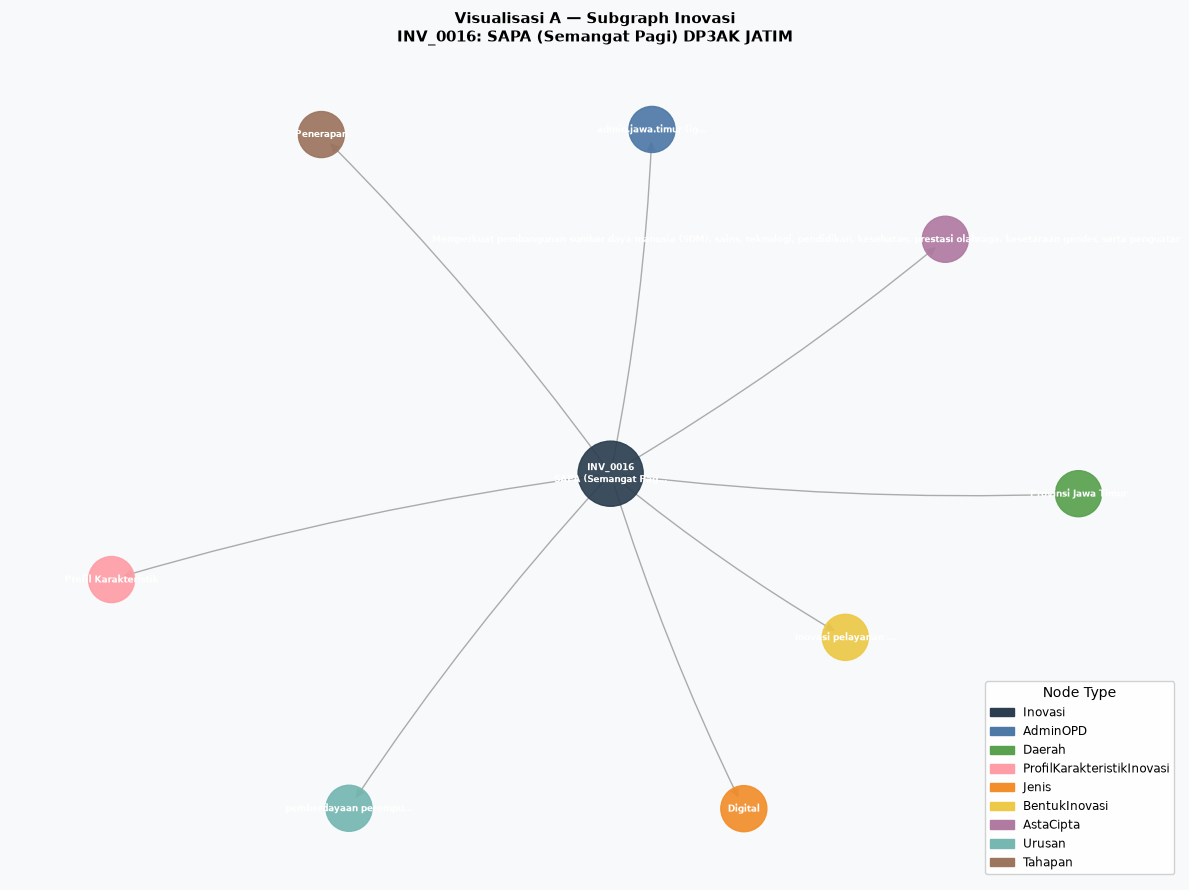

In [36]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import networkx as nx
import math

# Ambil inovasi yang sama dengan Traversal 1
vis_inv_id = target_inv
vis_judul  = G.nodes[vis_inv_id].get("judul_inovasi","")

# Bangun subgraph
SG_A = nx.DiGraph()

type_color_A = {
    "Inovasi"                    : "#2C3E50",
    "AdminOPD"                   : "#4E79A7",
    "Daerah"                     : "#59A14F",
    "ProfilEkosistemInovasi"     : "#E15759",
    "ProfilKarakteristikInovasi" : "#FF9DA7",
    "Jenis"                      : "#F28E2B",
    "BentukInovasi"              : "#EDC948",
    "AstaCipta"                  : "#B07AA1",
    "Urusan"                     : "#76B7B2",
    "Tahapan"                    : "#9C755F",
}

node_labels_A = {}
node_colors_A = {}

def add_node_A(nid, data):
    ntype = data.get("type","")
    if ntype == "Inovasi":
        label = nid + "\n" + data.get("judul_inovasi","")[:18] + "…"
    elif ntype == "AdminOPD":
        n = data.get("nama_opd","")
        label = (n[:20]+"…") if len(n)>20 else n
    elif ntype == "Daerah":
        label = data.get("nama_daerah","")
    elif ntype == "Jenis":
        label = data.get("nama_jenis","")
    elif ntype == "BentukInovasi":
        n = data.get("nama_bentuk","")
        label = (n[:18]+"…") if len(n)>18 else n
    elif ntype == "AstaCipta":
        label = data.get("nama_asta_cipta","")
    elif ntype == "Urusan":
        n = data.get("nama_urusan","")
        label = (n[:20]+"…") if len(n)>20 else n
    elif ntype == "Tahapan":
        label = data.get("nama_tahapan","")
    elif "Profil" in ntype:
        label = data.get("nama_profil","")[:20]
    else:
        label = nid
    SG_A.add_node(nid)
    node_labels_A[nid] = label
    node_colors_A[nid] = type_color_A.get(ntype, "#AAA")

# Node pusat
add_node_A(vis_inv_id, G.nodes[vis_inv_id])

# Tambah tetangga langsung (out)
edge_colors_A = []
for u, v, data in G.out_edges(vis_inv_id, data=True):
    if data.get("weighted"):
        continue
    add_node_A(v, G.nodes[v])
    SG_A.add_edge(u, v)
    edge_colors_A.append("#777")

# Jalur ke profil via daerah
daerah_neighbors = [v for u,v,d in G.out_edges(vis_inv_id, data=True) if d.get("relation")=="BERADA_DI"]
for did in daerah_neighbors:
    for u2,v2,d2 in G.out_edges(did, data=True):
        if d2.get("relation") == "TERMASUK_PROFIL_EKOSISTEM":
            add_node_A(v2, G.nodes[v2])
            SG_A.add_edge(did, v2)
            edge_colors_A.append("#E15759")

pos_A = nx.spring_layout(SG_A, seed=7, k=2.5)
# Paksa center node di tengah
pos_A[vis_inv_id] = (0.0, 0.0)

fig, ax = plt.subplots(figsize=(12, 9))
ax.set_facecolor("#F8F9FA")
fig.patch.set_facecolor("#F8F9FA")

n_colors_list = [node_colors_A.get(n, "#AAA") for n in SG_A.nodes()]
n_sizes       = [2200 if n == vis_inv_id else 1100 for n in SG_A.nodes()]

nx.draw_networkx_nodes(SG_A, pos_A, ax=ax, node_color=n_colors_list,
                       node_size=n_sizes, alpha=0.92)
nx.draw_networkx_labels(SG_A, pos_A, labels=node_labels_A, ax=ax,
                        font_size=6.5, font_color="white", font_weight="bold")
nx.draw_networkx_edges(SG_A, pos_A, ax=ax, edge_color=edge_colors_A,
                       alpha=0.6, arrows=True, arrowsize=13,
                       connectionstyle="arc3,rad=0.04")

legend_items = [mpatches.Patch(color=v, label=k) for k,v in type_color_A.items()
                if k in {G.nodes[n].get("type","") for n in SG_A.nodes()}]
ax.legend(handles=legend_items, loc="lower right", fontsize=8.5,
          framealpha=0.88, title="Node Type")
judul_short = vis_judul[:50]+"…" if len(vis_judul)>50 else vis_judul
ax.set_title(f"Visualisasi A — Subgraph Inovasi\n{vis_inv_id}: {judul_short}",
             fontsize=11, fontweight="bold", pad=12)
ax.axis("off")
plt.tight_layout()
plt.show()

### Visualisasi B — Profil Ekosistem → Daerah → Inovasi

Subgraph satu profil ekosistem, semua daerah yang masuk, dan sampel inovasi di setiap daerah.

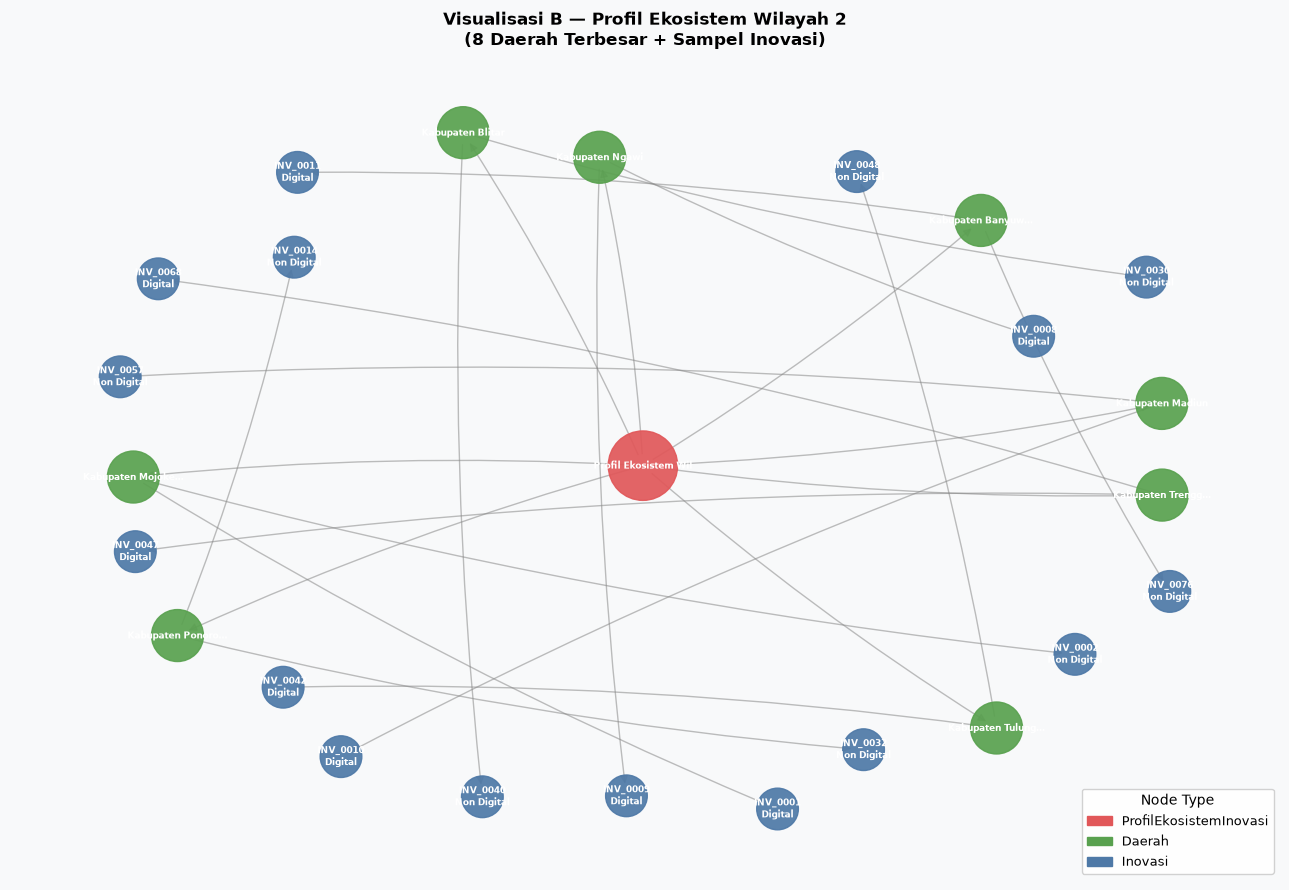

In [37]:
# ==============================================================
# VISUALISASI B — Profile Ecosystem → Daerah → Inovasi (sample)
# ==============================================================

SG_B    = nx.DiGraph()
labels_B = {}
colors_B = {}

type_color_B = {
    "ProfilEkosistemInovasi": "#E15759",
    "Daerah"                : "#59A14F",
    "Inovasi"               : "#4E79A7",
    "Jenis"                 : "#F28E2B",
    "Urusan"                : "#76B7B2",
}

def add_B(nid, ntype, label):
    SG_B.add_node(nid)
    labels_B[nid] = label
    colors_B[nid] = type_color_B.get(ntype, "#AAA")

vis_profil_B = target_profil
profil_nama_B = G.nodes[vis_profil_B].get("nama_profil","")
add_B(vis_profil_B, "ProfilEkosistemInovasi", profil_nama_B[:20])

# Daerah dalam profil
daerah_in_B = [u for u,v,d in G.in_edges(vis_profil_B, data=True)
               if d.get("relation")=="TERMASUK_PROFIL_EKOSISTEM"]

# Batasi 8 daerah terbesar agar terbaca
daerah_size = [(did, sum(1 for u,v,d in G.in_edges(did, data=True)
                         if d.get("relation")=="BERADA_DI")) for did in daerah_in_B]
daerah_size_sorted = sorted(daerah_size, key=lambda x: -x[1])[:8]

for did, n_inv in daerah_size_sorted:
    d_nama = G.nodes[did].get("nama_daerah","")
    d_label = (d_nama[:16]+"…") if len(d_nama)>16 else d_nama
    add_B(did, "Daerah", d_label)
    SG_B.add_edge(vis_profil_B, did)

    # Ambil 2 inovasi saja per daerah
    inv_sample = [u for u,v,d in G.in_edges(did, data=True)
                  if d.get("relation")=="BERADA_DI"][:2]
    for inv_id in inv_sample:
        nd = G.nodes[inv_id]
        j = nd.get("jenis","")
        inv_label = f"{inv_id}\n{j}"
        add_B(inv_id, "Inovasi", inv_label)
        SG_B.add_edge(did, inv_id)

pos_B = nx.spring_layout(SG_B, seed=42, k=2.8)
pos_B[vis_profil_B] = (0.0, 0.0)

fig2, ax2 = plt.subplots(figsize=(13, 9))
ax2.set_facecolor("#F8F9FA")
fig2.patch.set_facecolor("#F8F9FA")

nc_B = [colors_B.get(n, "#AAA") for n in SG_B.nodes()]
ns_B = [2500 if n==vis_profil_B else (1400 if G.nodes.get(n,{}).get("type")=="Daerah" else 900)
        for n in SG_B.nodes()]

nx.draw_networkx_nodes(SG_B, pos_B, ax=ax2, node_color=nc_B, node_size=ns_B, alpha=0.92)
nx.draw_networkx_labels(SG_B, pos_B, labels=labels_B, ax=ax2,
                        font_size=6.5, font_color="white", font_weight="bold")
nx.draw_networkx_edges(SG_B, pos_B, ax=ax2, edge_color="#888",
                       alpha=0.55, arrows=True, arrowsize=12,
                       connectionstyle="arc3,rad=0.04")

legend_B = [mpatches.Patch(color=v, label=k) for k,v in type_color_B.items()
            if k in {G.nodes.get(n,{}).get("type","") for n in SG_B.nodes()}]
ax2.legend(handles=legend_B, loc="lower right", fontsize=9,
           framealpha=0.88, title="Node Type")
ax2.set_title(f"Visualisasi B — {profil_nama_B}\n(8 Daerah Terbesar + Sampel Inovasi)",
              fontsize=12, fontweight="bold", pad=12)
ax2.axis("off")
plt.tight_layout()
plt.show()

### Visualisasi C — Weighted Profile Graph

Profil → Jenis/Urusan/Tahapan/Bentuk dengan edge berlabel persentase dan ketebalan ∝ weight.

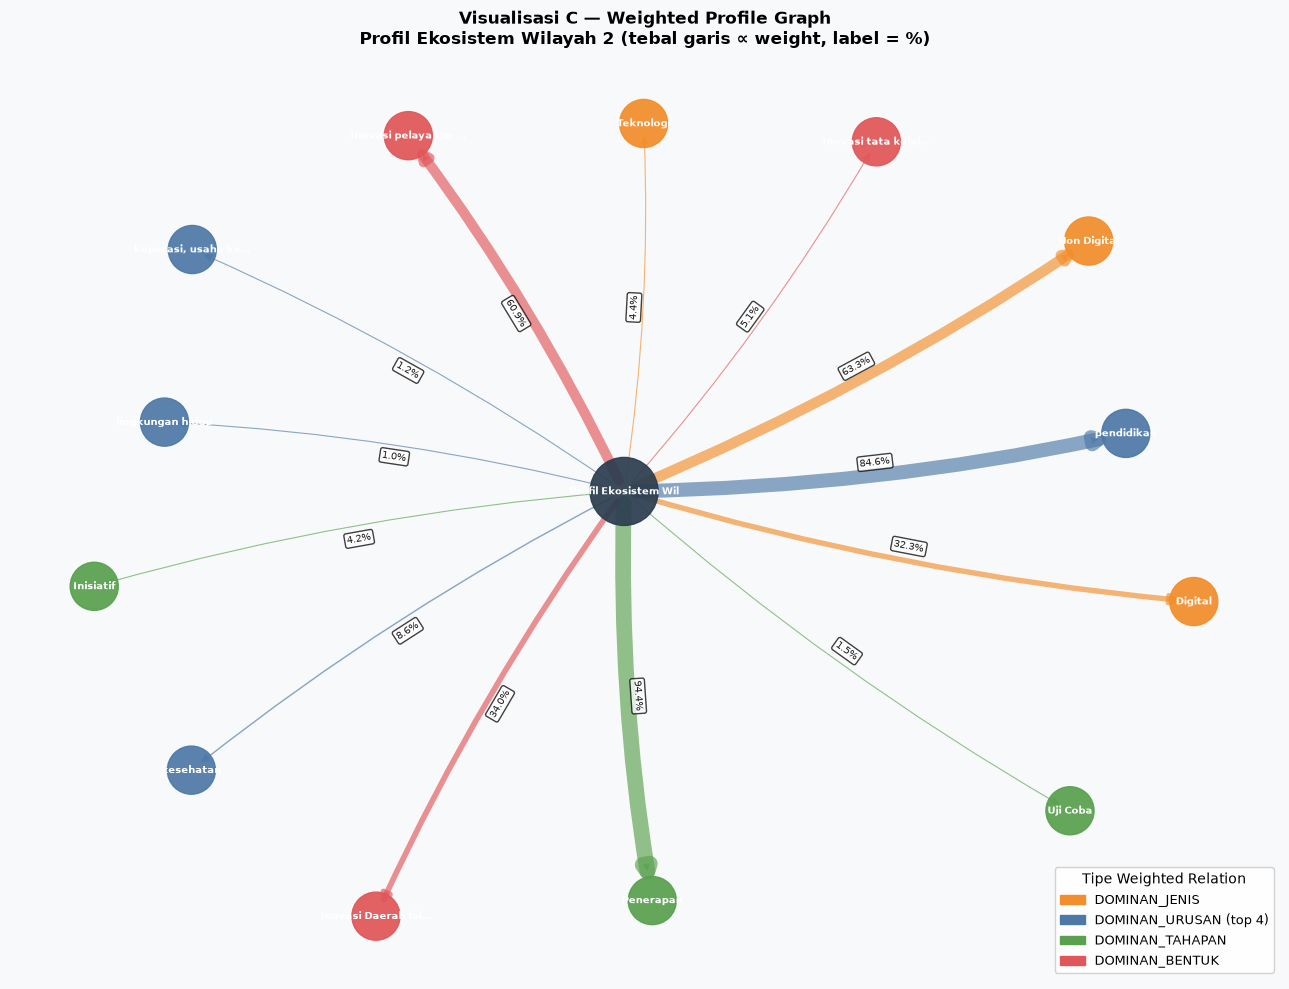

In [38]:
# ==============================================================
# VISUALISASI C — WEIGHTED PROFILE GRAPH (label % pada edge)
# ==============================================================

SG_C    = nx.DiGraph()
labels_C = {}
colors_C = {}
edge_weights_C = []
edge_labels_C  = {}
edge_colors_C  = []

type_color_C = {
    "ProfilEkosistemInovasi": "#2C3E50",
    "Jenis"                 : "#F28E2B",
    "Urusan"                : "#4E79A7",
    "Tahapan"               : "#59A14F",
    "BentukInovasi"         : "#E15759",
}

vis_profil_C = target_profil
p_nama_C = G.nodes[vis_profil_C].get("nama_profil","")
SG_C.add_node(vis_profil_C)
labels_C[vis_profil_C] = p_nama_C[:20]
colors_C[vis_profil_C] = type_color_C["ProfilEkosistemInovasi"]

rel_color_map = {
    "DOMINAN_JENIS"   : "#F28E2B",
    "DOMINAN_URUSAN"  : "#4E79A7",
    "DOMINAN_TAHAPAN" : "#59A14F",
    "DOMINAN_BENTUK"  : "#E15759",
}
rel_tgt_type = {
    "DOMINAN_JENIS"  : "Jenis",
    "DOMINAN_URUSAN" : "Urusan",
    "DOMINAN_TAHAPAN": "Tahapan",
    "DOMINAN_BENTUK" : "BentukInovasi",
}
# Untuk urusan, ambil top-4 saja agar tidak penuh
max_urusan = 4

urusan_added = 0
for u, v, data in G.out_edges(vis_profil_C, data=True):
    if not data.get("weighted"):
        continue
    rel = data.get("relation","")
    if rel == "DOMINAN_URUSAN":
        if urusan_added >= max_urusan:
            continue
        urusan_added += 1
    tgt_data = G.nodes[v]
    tgt_type = tgt_data.get("type","")
    if tgt_type == "Jenis":
        label = tgt_data.get("nama_jenis","")
    elif tgt_type == "Urusan":
        n = tgt_data.get("nama_urusan","")
        label = (n[:18]+"…") if len(n)>18 else n
    elif tgt_type == "Tahapan":
        label = tgt_data.get("nama_tahapan","")
    elif tgt_type == "BentukInovasi":
        n = tgt_data.get("nama_bentuk","")
        label = (n[:18]+"…") if len(n)>18 else n
    else:
        label = v
    SG_C.add_node(v)
    labels_C[v] = label
    colors_C[v] = type_color_C.get(tgt_type, "#AAA")
    SG_C.add_edge(u, v)
    w = data.get("weight", 0)
    pct = data.get("percentage", 0)
    edge_weights_C.append(max(0.8, w * 12))
    edge_labels_C[(u, v)] = f"{pct:.1f}%"
    edge_colors_C.append(rel_color_map.get(rel, "#888"))

pos_C = nx.spring_layout(SG_C, seed=13, k=2.4)
pos_C[vis_profil_C] = (0.0, 0.0)

fig3, ax3 = plt.subplots(figsize=(13, 10))
ax3.set_facecolor("#F8F9FA")
fig3.patch.set_facecolor("#F8F9FA")

nc_C = [colors_C.get(n,"#AAA") for n in SG_C.nodes()]
ns_C = [2400 if n==vis_profil_C else 1200 for n in SG_C.nodes()]

nx.draw_networkx_nodes(SG_C, pos_C, ax=ax3, node_color=nc_C, node_size=ns_C, alpha=0.93)
nx.draw_networkx_labels(SG_C, pos_C, labels=labels_C, ax=ax3,
                        font_size=7, font_color="white", font_weight="bold")

edges_list = list(SG_C.edges())
for i, (eu, ev) in enumerate(edges_list):
    lw = edge_weights_C[i] if i < len(edge_weights_C) else 1.0
    ec = edge_colors_C[i] if i < len(edge_colors_C) else "#888"
    nx.draw_networkx_edges(SG_C, pos_C, edgelist=[(eu,ev)], ax=ax3,
                           width=lw, edge_color=ec, alpha=0.65,
                           arrows=True, arrowsize=13,
                           connectionstyle="arc3,rad=0.05")

# Edge labels
nx.draw_networkx_edge_labels(SG_C, pos_C, edge_labels=edge_labels_C, ax=ax3,
                              font_size=7.5, font_color="#222",
                              bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.75))

legend_C = [
    mpatches.Patch(color="#F28E2B", label="DOMINAN_JENIS"),
    mpatches.Patch(color="#4E79A7", label="DOMINAN_URUSAN (top 4)"),
    mpatches.Patch(color="#59A14F", label="DOMINAN_TAHAPAN"),
    mpatches.Patch(color="#E15759", label="DOMINAN_BENTUK"),
]
ax3.legend(handles=legend_C, loc="lower right", fontsize=9,
           framealpha=0.88, title="Tipe Weighted Relation")
ax3.set_title(f"Visualisasi C — Weighted Profile Graph\n{p_nama_C} (tebal garis ∝ weight, label = %)",
              fontsize=12, fontweight="bold", pad=14)
ax3.axis("off")
plt.tight_layout()
plt.show()

### 4.11 — Validasi Graph vs Data Tabular

Membandingkan hasil traversal graph dengan hasil agregasi langsung dari `kg_source_df`. Jika ada perbedaan, akan diidentifikasi penyebabnya.

In [39]:
# ==============================================================
# VALIDASI: GRAPH vs TABULAR
# ==============================================================

print("=== VALIDASI GRAPH vs TABULAR ===\n")
ok_all = True

def check(label, graph_val, tabular_val, allow_diff=False):
    global ok_all
    match = "✓" if graph_val == tabular_val else ("~" if allow_diff else "✗")
    if match == "✗":
        ok_all = False
    print(f"  [{match}] {label}")
    print(f"       Graph    : {graph_val}")
    print(f"       Tabular  : {tabular_val}")
    if graph_val != tabular_val:
        print(f"       Selisih  : {abs(graph_val - tabular_val) if isinstance(graph_val, (int,float)) else 'N/A'}")
    print()

# 1. Total inovasi
graph_total = type_count.get("Inovasi",0)
tab_total   = len(kg_source_df)
check("Total Inovasi", graph_total, tab_total)

# 2. Inovasi Digital
graph_digital = len(find_innovations_by_jenis("Digital"))
tab_digital   = len(kg_source_df[kg_source_df["Jenis"]=="Digital"])
check("Inovasi Digital", graph_digital, tab_digital)

# 3. Inovasi Urusan Pendidikan
graph_pend = len(find_innovations_by_urusan("pendidikan"))
tab_pend   = len(kg_source_df[kg_source_df["Urusan Utama"].str.lower().str.strip()=="pendidikan"])
check("Inovasi Urusan Pendidikan", graph_pend, tab_pend)

# 4. Inovasi di daerah terbesar (dari traversal 2)
graph_daerah = len(find_innovations_by_daerah(target_daerah_nama))
tab_daerah   = len(kg_source_df[kg_source_df["Daerah"]==target_daerah_nama])
check(f"Inovasi di {target_daerah_nama}", graph_daerah, tab_daerah)

# 5. Inovasi di profil terbesar
# Graph: traversal Profil → Daerah → Inovasi
daerah_in_target = [u for u,v,d in G.in_edges(target_profil, data=True)
                    if d.get("relation")=="TERMASUK_PROFIL_EKOSISTEM"]
graph_profil_inv = sum(
    len([u for u,v,d in G.in_edges(did, data=True) if d.get("relation")=="BERADA_DI"])
    for did in daerah_in_target
)
# Tabular: kg_source_df filter Jenis_Cluster + Cluster
cluster_id = nodes_profil_ekosistem.loc[
    nodes_profil_ekosistem["profil_ekosistem_id"]==target_profil, "source_cluster_id"
].values[0]
tab_profil_inv = len(kg_source_df[
    (kg_source_df["Jenis_Cluster"]=="Cluster_Wilayah") &
    (kg_source_df["Cluster"]==cluster_id)
])
check(f"Inovasi di {target_profil_nama}", graph_profil_inv, tab_profil_inv)

print("-" * 50)
print("Catatan: Perbedaan kecil bisa terjadi jika ada inovasi di daerah yang")
print("tidak masuk nodes_daerah (filtered karena nilai tidak valid).")
if ok_all:
    print("\nSeluruh validasi Graph vs Tabular konsisten.")
else:
    print("\nTerdapat perbedaan. Lihat detail di atas.")

=== VALIDASI GRAPH vs TABULAR ===

  [✓] Total Inovasi
       Graph    : 679
       Tabular  : 679

  [✓] Inovasi Digital
       Graph    : 234
       Tabular  : 234

  [✓] Inovasi Urusan Pendidikan
       Graph    : 381
       Tabular  : 381

  [✓] Inovasi di Kabupaten Madiun
       Graph    : 61
       Tabular  : 61

  [✓] Inovasi di Profil Ekosistem Wilayah 2
       Graph    : 409
       Tabular  : 409

--------------------------------------------------
Catatan: Perbedaan kecil bisa terjadi jika ada inovasi di daerah yang
tidak masuk nodes_daerah (filtered karena nilai tidak valid).

Seluruh validasi Graph vs Tabular konsisten.


### 4.12 — Export Graph

Graph disimpan dalam tiga format:
- **GraphML** — format standar yang bisa dibaca oleh Gephi, yEd, dan library graph lainnya.
- **CSV Nodes** — semua node dengan propertinya.
- **CSV Edges** — semua edge dengan propertinya.

In [40]:
# ==============================================================
# EXPORT GRAPH
# ==============================================================

import warnings

# ------ 1. GraphML ------
# GraphML tidak support None; ganti dengan string kosong
G_export = G.copy()
for nid, data in G_export.nodes(data=True):
    for k, v in list(data.items()):
        if v is None:
            G_export.nodes[nid][k] = ""
        elif isinstance(v, float) and v != v:  # NaN check
            G_export.nodes[nid][k] = ""
        elif not isinstance(v, (str, int, float, bool)):
            G_export.nodes[nid][k] = str(v)

for u, v, key, data in G_export.edges(data=True, keys=True):
    for k, val in list(data.items()):
        if val is None:
            G_export[u][v][key][k] = ""
        elif not isinstance(val, (str, int, float, bool)):
            G_export[u][v][key][k] = str(val)

graphml_path = "innovation_knowledge_graph.graphml"
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    nx.write_graphml(G_export, graphml_path)
print(f"[SAVED] {graphml_path}")

# ------ 2. CSV Nodes ------
node_rows = []
for nid, data in G.nodes(data=True):
    row = {"node_id": nid}
    row.update({k: (str(v) if v is not None else "") for k, v in data.items()})
    node_rows.append(row)
df_nodes_export = pd.DataFrame(node_rows)
df_nodes_export.to_csv("knowledge_graph_nodes.csv", index=False, encoding="utf-8-sig")
print(f"[SAVED] knowledge_graph_nodes.csv  ({len(df_nodes_export)} rows)")

# ------ 3. CSV Edges ------
edge_rows = []
for u, v, data in G.edges(data=True):
    row = {
        "source_id"   : u,
        "target_id"   : v,
        "relation"    : data.get("relation",""),
        "weighted"    : data.get("weighted", False),
        "weight"      : data.get("weight",""),
        "count"       : data.get("count",""),
        "total"       : data.get("total",""),
        "percentage"  : data.get("percentage",""),
    }
    edge_rows.append(row)
df_edges_export = pd.DataFrame(edge_rows)
df_edges_export.to_csv("knowledge_graph_edges.csv", index=False, encoding="utf-8-sig")
print(f"[SAVED] knowledge_graph_edges.csv  ({len(df_edges_export)} rows)")
print()
print(f"Export selesai. Total node: {len(df_nodes_export)}, Total edge: {len(df_edges_export)}")

[SAVED] innovation_knowledge_graph.graphml
[SAVED] knowledge_graph_nodes.csv  (1073 rows)
[SAVED] knowledge_graph_edges.csv  (5817 rows)

Export selesai. Total node: 1073, Total edge: 5817


---

# STEP 4 CHECKPOINT — KNOWLEDGE GRAPH

Knowledge Graph berhasil dibangun menggunakan `networkx.MultiDiGraph`. Berikut ringkasan akhir seluruh komponen yang sudah ada.

In [41]:
# ==============================================================
# STEP 4 CHECKPOINT — RINGKASAN AKHIR
# ==============================================================

print("=" * 60)
print("  STEP 4 CHECKPOINT — KNOWLEDGE GRAPH")
print("=" * 60)

# 1 & 2. Total node & edge
print(f"\n1. Total Node : {G.number_of_nodes()}")
print(f"2. Total Edge : {G.number_of_edges()}")

# 3. Node distribution
print("\n3. Node Distribution:")
for t, c in sorted(type_count.items()):
    print(f"   {t:<38}: {c:>5}")

# 4. Edge distribution
print("\n4. Relationship Distribution:")
for r, c in sorted(rel_count.items()):
    tag = "[weighted]" if r.startswith("DOMINAN") else "[faktual] "
    print(f"   {r:<35} {tag}: {c:>5}")

# 5. Weighted vs Unweighted
print(f"\n5. Weighted Edge   : {n_w}")
print(f"   Unweighted Edge : {n_uw}")

# 6. Contoh traversal inovasi (rekapitulasi)
print(f"\n6. Contoh Traversal Inovasi: {target_inv}")
print(f"   Judul: {G.nodes[target_inv].get('judul_inovasi','')[:55]}")
rels = get_relationships(target_inv)
for r, c in rels.items():
    print(f"   {r}: {c}")

# 7. Traversal Daerah → Profil
print(f"\n7. Traversal Daerah → Profil:")
print(f"   Daerah  : {target_daerah_nama}")
if profil_ids_daerah:
    print(f"   Profil  : {G.nodes[profil_ids_daerah[0]].get('nama_profil','')}")
print(f"   Inovasi : {len(inv_di_daerah)}")

# 8. Multi-hop query
print(f"\n8. Multi-hop Query (Digital + Pendidikan + {profil_nama_query}):")
print(f"   Hasil   : {len(result_ids)} inovasi")

# 9. Weighted traversal (sampel)
print(f"\n9. Weighted Traversal ({w_profil_nama}):")
sample_w = sorted(
    [(d.get("relation"), G.nodes[v].get("nama_jenis",G.nodes[v].get("nama_tahapan",G.nodes[v].get("nama_urusan",v))),
      d.get("percentage",0))
     for u,v,d in G.out_edges(w_profil_id, data=True) if d.get("weighted")],
    key=lambda x: -x[2]
)[:5]
for rel, val, pct in sample_w:
    print(f"   {rel} → {val}: {pct:.2f}%")

# 10. Validasi Graph vs Tabular
print(f"\n10. Validasi Graph vs Tabular: {'LOLOS' if ok_all else 'ADA PERBEDAAN (lihat detail)'}")

# 11. Export files
import os
for fname in ["innovation_knowledge_graph.graphml",
              "knowledge_graph_nodes.csv",
              "knowledge_graph_edges.csv"]:
    size = os.path.getsize(fname) // 1024 if os.path.exists(fname) else 0
    print(f"\n11. {fname} ({size} KB)")

print()
print("=" * 60)
print("KESIMPULAN:")
print("=" * 60)
print("""
Knowledge Graph telah berhasil dibangun sebagai graph aktual yang
mengintegrasikan entity, relationship faktual, dan weighted relationship.
Graph dapat digunakan untuk melakukan traversal dari inovasi menuju OPD,
daerah, profil, jenis, urusan, dan tahapan, termasuk query multi-hop
dan eksplorasi karakteristik berbobot.
""")

  STEP 4 CHECKPOINT — KNOWLEDGE GRAPH

1. Total Node : 1073
2. Total Edge : 5817

3. Node Distribution:
   AdminOPD                              :   292
   AstaCipta                             :     8
   BentukInovasi                         :     3
   Daerah                                :    36
   Inovasi                               :   679
   Jenis                                 :     3
   ProfilEkosistemInovasi                :     3
   ProfilKarakteristikInovasi            :     3
   Tahapan                               :     3
   Urusan                                :    43

4. Relationship Distribution:
   BERADA_DI                           [faktual] :   678
   BERADA_DI_TAHAPAN                   [faktual] :   679
   BERBENTUK                           [faktual] :   679
   BERJENIS                            [faktual] :   679
   BERPILAR                            [faktual] :   587
   BERSINGGUNGAN_DENGAN                [faktual] :   795
   DICIRIKAN_PROFIL              

# STEP 5 — Graph Retrieval Layer

Tahap ini menyiapkan mekanisme pengambilan evidence dari Knowledge Graph berdasarkan kriteria terstruktur. Retrieval dilakukan melalui relationship pada graph, sehingga hasil dapat ditelusuri kembali ke jalur hubungan yang digunakan.

Fokus tahap ini adalah **graph traversal → evidence → retrieval context**. Belum digunakan LLM, embedding, vector database, atau chatbot.

In [42]:
# ==============================================================
# 5.1 — UTILITAS RETRIEVAL
# ==============================================================

import pandas as pd
import numpy as np

def _node_type(node_id):
    return G.nodes[node_id].get("type", "") if node_id in G else ""

def _node_name(node_id):
    if node_id not in G:
        return str(node_id)
    d = G.nodes[node_id]
    name_keys = {
        "Inovasi": "judul_inovasi",
        "AdminOPD": "nama_opd",
        "Daerah": "nama_daerah",
        "ProfilEkosistemInovasi": "nama_profil",
        "ProfilKarakteristikInovasi": "nama_profil",
        "Jenis": "nama_jenis",
        "BentukInovasi": "nama_bentuk",
        "AstaCipta": "nama_asta_cipta",
        "Urusan": "nama_urusan",
        "Tahapan": "nama_tahapan",
    }
    key = name_keys.get(d.get("type"))
    return str(d.get(key, node_id)) if key else str(node_id)

def _nodes_by_type(node_type):
    return [nid for nid, d in G.nodes(data=True) if d.get("type") == node_type]

def _find_nodes(node_type, name):
    """Pencarian nama node secara exact lalu partial, case-insensitive."""
    name_norm = str(name).strip().lower()
    exact, partial = [], []
    for nid in _nodes_by_type(node_type):
        current = _node_name(nid).strip().lower()
        if current == name_norm:
            exact.append(nid)
        elif name_norm in current:
            partial.append(nid)
    return exact or partial

def _incoming(node_id, relation):
    return [
        u for u, v, d in G.in_edges(node_id, data=True)
        if d.get("relation") == relation
    ]

def _outgoing(node_id, relation):
    return [
        v for u, v, d in G.out_edges(node_id, data=True)
        if d.get("relation") == relation
    ]

def _resolve_one(node_type, value):
    if value is None:
        return []
    if isinstance(value, (list, tuple, set)):
        result = []
        for x in value:
            result.extend(_resolve_one(node_type, x))
        return list(dict.fromkeys(result))
    if value in G and G.nodes[value].get("type") == node_type:
        return [value]
    return _find_nodes(node_type, value)

print("Utilitas retrieval siap.")

Utilitas retrieval siap.


In [43]:
# ==============================================================
# 5.2 — RETRIEVAL BERBASIS GRAPH
# ==============================================================

REL_PROFILE_EKO = "TERMASUK_PROFIL_EKOSISTEM"
REL_PROFILE_PROV = "DICIRIKAN_PROFIL"

def _innovation_ids_from_target(target_ids, relation):
    result = set()
    for tid in target_ids:
        result.update(_incoming(tid, relation))
    return result

def retrieve_innovations(
    profil=None,
    daerah=None,
    jenis=None,
    urusan=None,
    tahapan=None,
    opd=None,
    asta_cipta=None,
    limit=None
):
    """
    Retrieval hanya menggunakan relationship pada Knowledge Graph.

    Jalur profil wilayah:
        ProfilEkosistem ← Daerah ← Inovasi

    Jalur profil provinsi:
        ProfilKarakteristik ← Inovasi

    Filter lain:
        Inovasi → Jenis/Urusan/Tahapan/OPD/Asta Cipta
    """
    candidates = set(_nodes_by_type("Inovasi"))

    # --- Profil ---
    if profil is not None:
        profile_nodes = []
        profile_nodes.extend(_resolve_one("ProfilEkosistemInovasi", profil))
        profile_nodes.extend(_resolve_one("ProfilKarakteristikInovasi", profil))
        profile_nodes = list(dict.fromkeys(profile_nodes))

        profile_candidates = set()

        for pid in profile_nodes:
            ptype = _node_type(pid)
            if ptype == "ProfilEkosistemInovasi":
                daerah_ids = _incoming(pid, REL_PROFILE_EKO)
                for did in daerah_ids:
                    profile_candidates.update(_incoming(did, "BERADA_DI"))
            elif ptype == "ProfilKarakteristikInovasi":
                profile_candidates.update(_incoming(pid, REL_PROFILE_PROV))

        candidates &= profile_candidates

    # --- Daerah ---
    if daerah is not None:
        daerah_ids = _resolve_one("Daerah", daerah)
        candidates &= _innovation_ids_from_target(daerah_ids, "BERADA_DI")

    # --- Jenis ---
    if jenis is not None:
        jenis_ids = _resolve_one("Jenis", jenis)
        candidates &= _innovation_ids_from_target(jenis_ids, "BERJENIS")

    # --- Urusan Utama ---
    if urusan is not None:
        urusan_ids = _resolve_one("Urusan", urusan)
        candidates &= _innovation_ids_from_target(
            urusan_ids, "MENANGANI_URUSAN"
        )

    # --- Tahapan ---
    if tahapan is not None:
        tahap_ids = _resolve_one("Tahapan", tahapan)
        candidates &= _innovation_ids_from_target(
            tahap_ids, "BERADA_DI_TAHAPAN"
        )

    # --- OPD ---
    if opd is not None:
        opd_ids = _resolve_one("AdminOPD", opd)
        candidates &= _innovation_ids_from_target(
            opd_ids, "DIKELOLA_OLEH"
        )

    # --- Asta Cipta ---
    if asta_cipta is not None:
        asta_ids = _resolve_one("AstaCipta", asta_cipta)
        candidates &= _innovation_ids_from_target(
            asta_ids, "BERPILAR"
        )

    rows = []
    for iid in sorted(candidates):
        d = G.nodes[iid]

        # Ambil nama daerah dari relationship, bukan hanya property.
        daerah_ids = _outgoing(iid, "BERADA_DI")
        daerah_names = [_node_name(x) for x in daerah_ids]

        opd_ids = _outgoing(iid, "DIKELOLA_OLEH")
        opd_names = [_node_name(x) for x in opd_ids]

        jenis_ids = _outgoing(iid, "BERJENIS")
        jenis_names = [_node_name(x) for x in jenis_ids]

        urusan_ids = _outgoing(iid, "MENANGANI_URUSAN")
        urusan_names = [_node_name(x) for x in urusan_ids]

        tahap_ids = _outgoing(iid, "BERADA_DI_TAHAPAN")
        tahap_names = [_node_name(x) for x in tahap_ids]

        rows.append({
            "inovasi_id": iid,
            "judul": d.get("judul_inovasi", ""),
            "daerah": "; ".join(daerah_names),
            "opd": "; ".join(opd_names),
            "jenis": "; ".join(jenis_names),
            "urusan": "; ".join(urusan_names),
            "tahapan": "; ".join(tahap_names),
            "kematangan": d.get("kematangan", np.nan),
            "tingkat_kematangan": d.get("tingkat_kematangan", ""),
        })

    result = pd.DataFrame(rows)

    if limit is not None and not result.empty:
        result = result.head(int(limit))

    return result.reset_index(drop=True)

print("Fungsi retrieve_innovations siap.")

Fungsi retrieve_innovations siap.


In [44]:
# ==============================================================
# 5.3 — WEIGHTED PROFILE RETRIEVAL
# ==============================================================

def retrieve_profile_characteristics(profil):
    """Mengambil seluruh relationship berbobot dari satu profil."""
    profile_nodes = []
    profile_nodes.extend(_resolve_one("ProfilEkosistemInovasi", profil))
    profile_nodes.extend(_resolve_one("ProfilKarakteristikInovasi", profil))
    profile_nodes = list(dict.fromkeys(profile_nodes))

    rows = []
    for pid in profile_nodes:
        for _, target, data in G.out_edges(pid, data=True):
            if not data.get("weighted", False):
                continue

            rows.append({
                "profil_id": pid,
                "profil": _node_name(pid),
                "relationship": data.get("relation", ""),
                "target_id": target,
                "target": _node_name(target),
                "weight": float(data.get("weight", np.nan)),
                "percentage": float(data.get("percentage", np.nan)),
                "count": data.get("count", np.nan),
                "total": data.get("total", np.nan),
            })

    return pd.DataFrame(rows)

def build_retrieval_context(result_df, weighted_df=None, max_items=20):
    """
    Membuat context terstruktur.
    Tidak melakukan interpretasi atau menghasilkan jawaban.
    """
    lines = ["=== RETRIEVAL CONTEXT ==="]

    if result_df is None or result_df.empty:
        lines.append("INNOVATION_EVIDENCE: tidak ditemukan.")
    else:
        lines.append(f"INNOVATION_EVIDENCE: {len(result_df)} hasil")
        for _, row in result_df.head(max_items).iterrows():
            lines.append(
                f"- {row['inovasi_id']} | {row['judul']} | "
                f"Daerah={row['daerah']} | OPD={row['opd']} | "
                f"Jenis={row['jenis']} | Urusan={row['urusan']} | "
                f"Tahapan={row['tahapan']} | "
                f"Kematangan={row['kematangan']}"
            )

    if weighted_df is not None and not weighted_df.empty:
        lines.extend(["", "PROFILE_WEIGHTED_CHARACTERISTICS:"])
        for _, row in weighted_df.iterrows():
            lines.append(
                f"- {row['relationship']} | {row['target']} | "
                f"weight={row['weight']:.4f} | "
                f"percentage={row['percentage']:.2f}% | "
                f"count={row['count']} / total={row['total']}"
            )

    return "\n".join(lines)

print("Weighted retrieval dan context builder siap.")

Weighted retrieval dan context builder siap.


In [45]:
# ==============================================================
# 5.4 — EVIDENCE DENGAN JALUR TRAVERSAL
# ==============================================================

def build_evidence_for_innovation(iid):
    """
    Menyimpan fakta dan jalur hubungan yang menyebabkan sebuah
    inovasi dapat ditemukan di graph.
    """
    if iid not in G or G.nodes[iid].get("type") != "Inovasi":
        return []

    evidence = []

    for _, target, data in G.out_edges(iid, data=True):
        relation = data.get("relation", "")
        target_type = _node_type(target)

        if data.get("weighted", False):
            continue

        evidence.append({
            "source_id": iid,
            "source_type": "Inovasi",
            "source_name": _node_name(iid),
            "relationship": relation,
            "target_id": target,
            "target_type": target_type,
            "target_name": _node_name(target),
            "properties": {
                "kematangan": G.nodes[iid].get("kematangan"),
                "tingkat_kematangan": G.nodes[iid].get("tingkat_kematangan"),
            }
        })

    # Jalur Inovasi → Daerah → Profil Ekosistem
    for did in _outgoing(iid, "BERADA_DI"):
        for pid in _outgoing(did, REL_PROFILE_EKO):
            evidence.append({
                "source_id": did,
                "source_type": "Daerah",
                "source_name": _node_name(did),
                "relationship": REL_PROFILE_EKO,
                "target_id": pid,
                "target_type": _node_type(pid),
                "target_name": _node_name(pid),
                "properties": {
                    "path": f"{iid} → {did} → {pid}"
                }
            })

    # Jalur langsung Inovasi → Profil Karakteristik Provinsi
    for pid in _outgoing(iid, REL_PROFILE_PROV):
        evidence.append({
            "source_id": iid,
            "source_type": "Inovasi",
            "source_name": _node_name(iid),
            "relationship": REL_PROFILE_PROV,
            "target_id": pid,
            "target_type": _node_type(pid),
            "target_name": _node_name(pid),
            "properties": {
                "path": f"{iid} → {pid}"
            }
        })

    return evidence

def build_evidence_from_results(result_df):
    evidence = []
    if result_df is None or result_df.empty:
        return evidence

    for iid in result_df["inovasi_id"]:
        evidence.extend(build_evidence_for_innovation(iid))

    return evidence

print("Evidence builder siap.")

Evidence builder siap.


## 5.5 — Skenario Retrieval

Skenario menggunakan nilai yang benar-benar tersedia pada graph. Untuk contoh multi-hop, dipilih profil ekosistem dengan jumlah inovasi terbesar agar hasil retrieval tidak kosong hanya karena kombinasi filter tidak tersedia.

In [46]:
# ==============================================================
# 5.5 — SKENARIO A: PROFIL → DAERAH
# ==============================================================

scenario_profile = target_profil if "target_profil" in globals() else None

print("SCENARIO A")
print("Pertanyaan: Daerah apa saja yang memiliki profil ekosistem tertentu?")
print(f"Profil: {scenario_profile}")

if scenario_profile:
    daerah_ids = _incoming(scenario_profile, REL_PROFILE_EKO)

    rows = []
    for did in daerah_ids:
        inv_ids = _incoming(did, "BERADA_DI")
        rows.append({
            "daerah_id": did,
            "daerah": _node_name(did),
            "profil_id": scenario_profile,
            "profil": _node_name(scenario_profile),
            "jumlah_inovasi": len(inv_ids)
        })

    scenario_A = pd.DataFrame(rows).sort_values(
        "jumlah_inovasi", ascending=False
    ).reset_index(drop=True)
else:
    scenario_A = pd.DataFrame()

display(scenario_A)

SCENARIO A
Pertanyaan: Daerah apa saja yang memiliki profil ekosistem tertentu?
Profil: PROFILE_EKO_02


,daerah_id,daerah,profil_id,profil,jumlah_inovasi
0,DAERAH_12,Kabupaten Madiun,PROFILE_EKO_02,Profil Ekosistem Wilayah 2,61
1,DAERAH_02,Kabupaten Banyuwangi,PROFILE_EKO_02,Profil Ekosistem Wilayah 2,42
2,DAERAH_21,Kabupaten Ponorogo,PROFILE_EKO_02,Profil Ekosistem Wilayah 2,33
3,DAERAH_28,Kabupaten Tulungagung,PROFILE_EKO_02,Profil Ekosistem Wilayah 2,29
4,DAERAH_15,Kabupaten Mojokerto,PROFILE_EKO_02,Profil Ekosistem Wilayah 2,28
5,DAERAH_03,Kabupaten Blitar,PROFILE_EKO_02,Profil Ekosistem Wilayah 2,26
6,DAERAH_26,Kabupaten Trenggalek,PROFILE_EKO_02,Profil Ekosistem Wilayah 2,24
7,DAERAH_17,Kabupaten Ngawi,PROFILE_EKO_02,Profil Ekosistem Wilayah 2,23
8,DAERAH_27,Kabupaten Tuban,PROFILE_EKO_02,Profil Ekosistem Wilayah 2,22
9,DAERAH_22,Kabupaten Probolinggo,PROFILE_EKO_02,Profil Ekosistem Wilayah 2,18


In [47]:
# ==============================================================
# 5.6 — SKENARIO B: MULTI-HOP
# ==============================================================

# Gunakan nilai aktual dari dataset.
target_jenis = "Digital"
target_urusan = "pendidikan"

scenario_B = retrieve_innovations(
    profil=scenario_profile,
    jenis=target_jenis,
    urusan=target_urusan
)

print("SCENARIO B")
print(
    f"Pertanyaan: Inovasi {target_jenis} pada urusan "
    f"{target_urusan} dalam {scenario_profile}?"
)
print()
print("Jalur traversal:")
print("Profil → Daerah → Inovasi → Jenis + Urusan")
print(f"Jumlah hasil: {len(scenario_B)}")

display(scenario_B.head(20))

SCENARIO B
Pertanyaan: Inovasi Digital pada urusan pendidikan dalam PROFILE_EKO_02?

Jalur traversal:
Profil → Daerah → Inovasi → Jenis + Urusan
Jumlah hasil: 108


,inovasi_id,judul,daerah,opd,jenis,urusan,tahapan,kematangan,tingkat_kematangan
0,INV_0008,SPORTOFOLIO - Portfolio Digital Pembelajaran PJOK di Indonesia,Kabupaten Ngawi,"SMAN 1 SINE, KAB. NGAWI (jatimprov.dispendik.sman1sine)",Digital,pendidikan,Penerapan,0.0,Sedang
1,INV_0009,SMANSI-ku - Aplikasi Panduan Informasi Untuk Siswa SMAN 1 SINE,Kabupaten Ngawi,"SMAN 1 SINE, KAB. NGAWI (jatimprov.dispendik.sman1sine)",Digital,pendidikan,Penerapan,0.0,Sedang
2,INV_0010,‘E-KOMITE’ SISTEM MONITORING PELAYANAN PARTISIPASI SUMBANGAN MASYARAKAT UNTUK PENINGKATAN MUTU PENDIDIKAN,Kabupaten Madiun,"SMK NEGERI 1 KARE, KAB MADIUN (jatimprov.dispendik.smkn1kare)",Digital,pendidikan,Penerapan,0.0,Sedang
3,INV_0036,"Legen Tuban (LitErasi, GENeralisasi, dan Teknologi Untuk digitalisasi tuBAN)",Kabupaten Tuban,SMK NEGERI RENGEL TUBAN (iga2024.smkn.rengel.tuban),Digital,pendidikan,Penerapan,95.0,Sedang
4,INV_0042,One Semester One Project,Kabupaten Tulungagung,SMA NEGERI 1 KAUMAN TULUNGAGUNG (iga2024.sman1.kauman.tulungagung),Digital,pendidikan,Penerapan,18.0,Sedang
5,INV_0044,Melog ( Melek Tekhnologi),Kabupaten Mojokerto,SLB Semesta Kab. Mojokerto (iga2024.slb.semesta.mojokerto),Digital,pendidikan,Penerapan,22.0,Sedang
6,INV_0047,PENGEMBANGAN PEMBELAJARAN BERPIHAK PADA MURID MELALUI PROGAM SATU SAKSI ( SATU GURU SATU AKSI NYATA PMM) DI SMAN 1 B...,Kabupaten Trenggalek,SMA NEGERI 1 BENDUNGAN TRENGGALEK (iga2024.sman1.bendungan.trenggalek),Digital,pendidikan,Penerapan,83.0,Sedang
7,INV_0051,INOVASI APLIKASI PERPUSTAKAAN SEKOLAH BERBASIS WEB,Kabupaten Nganjuk,SMKN 1 NGANJUK (iga2024.smkn1.nganjuk),Digital,pendidikan,Penerapan,51.0,Sedang
8,INV_0064,KULINER (Kuliah Literasi dan Numerasi) SMARIDUTA,Kabupaten Tulungagung,SMA NEGERI 1 KEDUNGWARU TULUNGAGUNG (iga2024.sman1.kedungwaru.tulungagung),Digital,pendidikan,Penerapan,104.0,Sedang
9,INV_0065,E-POINT (Layanan Elektronik Rekapitulasi Point Pelanggaran Siswa),Kota Blitar,SMKS ISLAM 1 KOTA BLITAR (iga2024.smks.islam.1.blitar),Digital,pendidikan,Penerapan,58.0,Sedang


In [48]:
# ==============================================================
# 5.7 — SKENARIO C: PROFIL + WEIGHT
# ==============================================================

scenario_C_weighted = retrieve_profile_characteristics(scenario_profile)

print("SCENARIO C")
print("Pertanyaan: Apa karakteristik profil ekosistem tertentu?")
print(f"Profil: {scenario_profile}")
print()
print("Jalur retrieval:")
print("Profil → weighted Jenis / Urusan / Tahapan / Bentuk")

display(scenario_C_weighted)

SCENARIO C
Pertanyaan: Apa karakteristik profil ekosistem tertentu?
Profil: PROFILE_EKO_02

Jalur retrieval:
Profil → weighted Jenis / Urusan / Tahapan / Bentuk


,profil_id,profil,relationship,target_id,target,weight,percentage,count,total
0,PROFILE_EKO_02,Profil Ekosistem Wilayah 2,DOMINAN_JENIS,JENIS_02,Non Digital,0.633252,63.33,259,409
1,PROFILE_EKO_02,Profil Ekosistem Wilayah 2,DOMINAN_JENIS,JENIS_01,Digital,0.322738,32.27,132,409
2,PROFILE_EKO_02,Profil Ekosistem Wilayah 2,DOMINAN_JENIS,JENIS_03,Teknologi,0.044010,4.40,18,409
3,PROFILE_EKO_02,Profil Ekosistem Wilayah 2,DOMINAN_URUSAN,URUSAN_027,pendidikan,0.845966,84.60,346,409
4,PROFILE_EKO_02,Profil Ekosistem Wilayah 2,DOMINAN_URUSAN,URUSAN_012,kesehatan,0.085575,8.56,35,409
5,PROFILE_EKO_02,Profil Ekosistem Wilayah 2,DOMINAN_URUSAN,URUSAN_019,"koperasi, usaha kecil, dan menengah",0.012225,1.22,5,409
6,PROFILE_EKO_02,Profil Ekosistem Wilayah 2,DOMINAN_URUSAN,URUSAN_020,lingkungan hidup,0.009780,0.98,4,409
7,PROFILE_EKO_02,Profil Ekosistem Wilayah 2,DOMINAN_URUSAN,URUSAN_024,pemberdayaan masyarakat dan desa,0.009780,0.98,4,409
8,PROFILE_EKO_02,Profil Ekosistem Wilayah 2,DOMINAN_URUSAN,URUSAN_021,pangan,0.007335,0.73,3,409
9,PROFILE_EKO_02,Profil Ekosistem Wilayah 2,DOMINAN_URUSAN,URUSAN_028,pendidikan dan pelatihan,0.007335,0.73,3,409


In [49]:
# ==============================================================
# 5.8 — STRUCTURED EVIDENCE DAN RETRIEVAL CONTEXT
# ==============================================================

evidence_B = build_evidence_from_results(scenario_B)

context_B = build_retrieval_context(
    scenario_B,
    weighted_df=scenario_C_weighted,
    max_items=20
)

print("=== STRUCTURED EVIDENCE ===")
print(f"Jumlah evidence: {len(evidence_B)}")
display(pd.DataFrame(evidence_B).head(20))

print("\n=== RETRIEVAL CONTEXT ===\n")
print(context_B[:8000])

=== STRUCTURED EVIDENCE ===
Jumlah evidence: 982


,source_id,source_type,source_name,relationship,target_id,target_type,target_name,properties
0,INV_0008,Inovasi,SPORTOFOLIO - Portfolio Digital Pembelajaran PJOK di Indonesia,DIKELOLA_OLEH,OPD_176,AdminOPD,"SMAN 1 SINE, KAB. NGAWI (jatimprov.dispendik.sman1sine)","{'kematangan': 0.0, 'tingkat_kematangan': 'Sedang'}"
1,INV_0008,Inovasi,SPORTOFOLIO - Portfolio Digital Pembelajaran PJOK di Indonesia,BERADA_DI,DAERAH_17,Daerah,Kabupaten Ngawi,"{'kematangan': 0.0, 'tingkat_kematangan': 'Sedang'}"
2,INV_0008,Inovasi,SPORTOFOLIO - Portfolio Digital Pembelajaran PJOK di Indonesia,BERJENIS,JENIS_01,Jenis,Digital,"{'kematangan': 0.0, 'tingkat_kematangan': 'Sedang'}"
3,INV_0008,Inovasi,SPORTOFOLIO - Portfolio Digital Pembelajaran PJOK di Indonesia,BERBENTUK,BENTUK_01,BentukInovasi,Inovasi Daerah lainnya sesuai dengan Urusan Pemerintahan yang menjadi kewenangan Daerah,"{'kematangan': 0.0, 'tingkat_kematangan': 'Sedang'}"
4,INV_0008,Inovasi,SPORTOFOLIO - Portfolio Digital Pembelajaran PJOK di Indonesia,MENANGANI_URUSAN,URUSAN_027,Urusan,pendidikan,"{'kematangan': 0.0, 'tingkat_kematangan': 'Sedang'}"
5,INV_0008,Inovasi,SPORTOFOLIO - Portfolio Digital Pembelajaran PJOK di Indonesia,BERSINGGUNGAN_DENGAN,URUSAN_011,Urusan,kepemudaan dan olah raga,"{'kematangan': 0.0, 'tingkat_kematangan': 'Sedang'}"
6,INV_0008,Inovasi,SPORTOFOLIO - Portfolio Digital Pembelajaran PJOK di Indonesia,BERSINGGUNGAN_DENGAN,URUSAN_006,Urusan,kearsipan,"{'kematangan': 0.0, 'tingkat_kematangan': 'Sedang'}"
7,INV_0008,Inovasi,SPORTOFOLIO - Portfolio Digital Pembelajaran PJOK di Indonesia,BERSINGGUNGAN_DENGAN,URUSAN_028,Urusan,pendidikan dan pelatihan,"{'kematangan': 0.0, 'tingkat_kematangan': 'Sedang'}"
8,INV_0008,Inovasi,SPORTOFOLIO - Portfolio Digital Pembelajaran PJOK di Indonesia,BERSINGGUNGAN_DENGAN,URUSAN_005,Urusan,fungsi penunjang lainnya sesuai dengan ketentuan peraturan perundang-undangan,"{'kematangan': 0.0, 'tingkat_kematangan': 'Sedang'}"
9,INV_0008,Inovasi,SPORTOFOLIO - Portfolio Digital Pembelajaran PJOK di Indonesia,BERADA_DI_TAHAPAN,TAHAPAN_02,Tahapan,Penerapan,"{'kematangan': 0.0, 'tingkat_kematangan': 'Sedang'}"



=== RETRIEVAL CONTEXT ===

=== RETRIEVAL CONTEXT ===
INNOVATION_EVIDENCE: 108 hasil
- INV_0008 | SPORTOFOLIO - Portfolio Digital Pembelajaran PJOK di Indonesia | Daerah=Kabupaten Ngawi | OPD=SMAN 1 SINE, KAB. NGAWI  (jatimprov.dispendik.sman1sine) | Jenis=Digital | Urusan=pendidikan | Tahapan=Penerapan | Kematangan=0.0
- INV_0009 | SMANSI-ku - Aplikasi Panduan Informasi Untuk Siswa SMAN 1 SINE | Daerah=Kabupaten Ngawi | OPD=SMAN 1 SINE, KAB. NGAWI  (jatimprov.dispendik.sman1sine) | Jenis=Digital | Urusan=pendidikan | Tahapan=Penerapan | Kematangan=0.0
- INV_0010 | ‘E-KOMITE’ SISTEM MONITORING PELAYANAN PARTISIPASI SUMBANGAN MASYARAKAT UNTUK PENINGKATAN  MUTU PENDIDIKAN | Daerah=Kabupaten Madiun | OPD=SMK NEGERI 1 KARE, KAB MADIUN (jatimprov.dispendik.smkn1kare) | Jenis=Digital | Urusan=pendidikan | Tahapan=Penerapan | Kematangan=0.0
- INV_0036 | Legen Tuban (LitErasi, GENeralisasi, dan Teknologi Untuk digitalisasi tuBAN) | Daerah=Kabupaten Tuban | OPD=SMK NEGERI RENGEL TUBAN (iga2024.

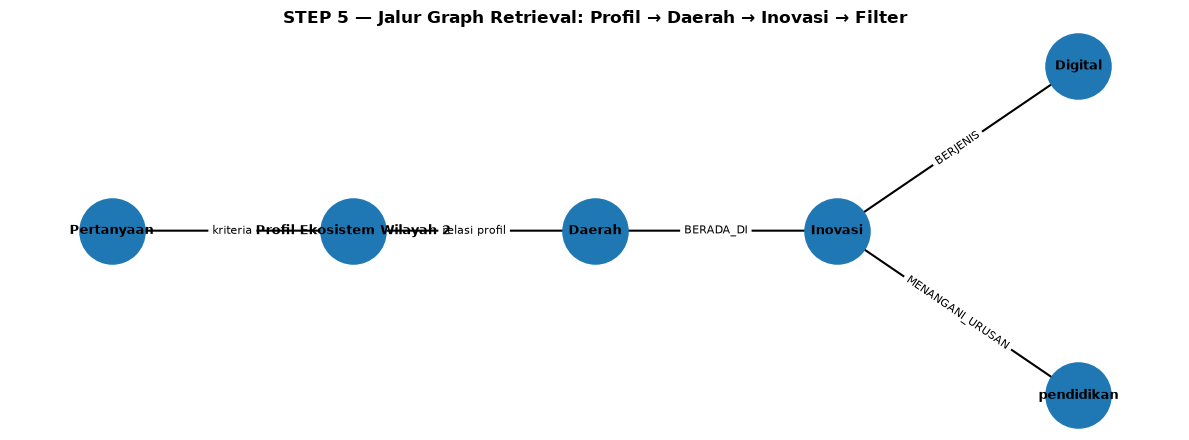

In [50]:
# ==============================================================
# 5.9 — VISUALISASI RETRIEVAL PATH
# ==============================================================

import matplotlib.pyplot as plt
import networkx as nx

R = nx.DiGraph()

root = "Pertanyaan"
profile_label = _node_name(scenario_profile) if scenario_profile else "Profil"
region_label = "Daerah"
innovation_label = "Inovasi"
jenis_label = target_jenis
urusan_label = target_urusan

R.add_edges_from([
    (root, profile_label),
    (profile_label, region_label),
    (region_label, innovation_label),
    (innovation_label, jenis_label),
    (innovation_label, urusan_label),
])

pos = {
    root: (0, 0),
    profile_label: (1.7, 0),
    region_label: (3.4, 0),
    innovation_label: (5.1, 0),
    jenis_label: (6.8, 0.8),
    urusan_label: (6.8, -0.8),
}

fig, ax = plt.subplots(figsize=(12, 4.5))
nx.draw_networkx_nodes(R, pos, ax=ax, node_size=2200)
nx.draw_networkx_edges(R, pos, ax=ax, arrows=True, arrowsize=18, width=1.5)
nx.draw_networkx_labels(R, pos, ax=ax, font_size=9, font_weight="bold")
nx.draw_networkx_edge_labels(
    R, pos,
    edge_labels={
        (root, profile_label): "kriteria",
        (profile_label, region_label): "relasi profil",
        (region_label, innovation_label): "BERADA_DI",
        (innovation_label, jenis_label): "BERJENIS",
        (innovation_label, urusan_label): "MENANGANI_URUSAN",
    },
    ax=ax,
    font_size=8
)

ax.set_title(
    "STEP 5 — Jalur Graph Retrieval: Profil → Daerah → Inovasi → Filter",
    fontsize=12,
    fontweight="bold"
)
ax.axis("off")
plt.tight_layout()
plt.show()

In [51]:
# ==============================================================
# 5.10 — VALIDASI RETRIEVAL VS DATA TABULAR
# ==============================================================

print("=== VALIDASI GRAPH RETRIEVAL VS TABULAR ===\n")

validation_rows = []

# Total inovasi
graph_total = len(retrieve_innovations())
tab_total = len(kg_source_df)
validation_rows.append({
    "metric": "Total inovasi",
    "graph": graph_total,
    "tabular": tab_total,
    "match": graph_total == tab_total
})

# Digital
graph_digital = len(retrieve_innovations(jenis="Digital"))
tab_digital = int(
    kg_source_df["Jenis"].astype(str).str.strip().eq("Digital").sum()
)
validation_rows.append({
    "metric": "Inovasi Digital",
    "graph": graph_digital,
    "tabular": tab_digital,
    "match": graph_digital == tab_digital
})

# Pendidikan
graph_pendidikan = len(retrieve_innovations(urusan="pendidikan"))
tab_pendidikan = int(
    kg_source_df["Urusan Utama"].astype(str).str.strip().str.lower().eq("pendidikan").sum()
)
validation_rows.append({
    "metric": "Urusan Utama pendidikan",
    "graph": graph_pendidikan,
    "tabular": tab_pendidikan,
    "match": graph_pendidikan == tab_pendidikan
})

# Daerah target STEP 4
if "target_daerah_nama" in globals():
    graph_daerah = len(retrieve_innovations(daerah=target_daerah_nama))
    tab_daerah = int(
        kg_source_df["Daerah"].astype(str).str.strip().eq(
            str(target_daerah_nama).strip()
        ).sum()
    )
    validation_rows.append({
        "metric": f"Inovasi di {target_daerah_nama}",
        "graph": graph_daerah,
        "tabular": tab_daerah,
        "match": graph_daerah == tab_daerah
    })

# Profil target STEP 4
if target_profil is not None:
    graph_profil = len(retrieve_innovations(profil=target_profil))

    cluster_row = nodes_profil_ekosistem[
        nodes_profil_ekosistem["profil_ekosistem_id"] == target_profil
    ]
    if not cluster_row.empty:
        source_cluster = cluster_row.iloc[0]["source_cluster_id"]
        tab_profil = int(
            (
                (kg_source_df["Jenis_Cluster"] == "Cluster_Wilayah") &
                (kg_source_df["Cluster"] == source_cluster)
            ).sum()
        )
        validation_rows.append({
            "metric": f"Inovasi di {target_profil}",
            "graph": graph_profil,
            "tabular": tab_profil,
            "match": graph_profil == tab_profil
        })

validation_retrieval = pd.DataFrame(validation_rows)
display(validation_retrieval)

if validation_retrieval["match"].all():
    print("✓ Seluruh validasi retrieval konsisten dengan data tabular.")
else:
    print("⚠ Masih ada perbedaan pada retrieval. Periksa metric yang bertanda False.")

=== VALIDASI GRAPH RETRIEVAL VS TABULAR ===



,metric,graph,tabular,match
0,Total inovasi,679,679,True
1,Inovasi Digital,234,234,True
2,Urusan Utama pendidikan,381,381,True
3,Inovasi di Kabupaten Madiun,61,61,True
4,Inovasi di PROFILE_EKO_02,409,409,True


✓ Seluruh validasi retrieval konsisten dengan data tabular.


# STEP 5 CHECKPOINT — GRAPH RETRIEVAL

Graph Retrieval Layer telah disiapkan untuk mengambil evidence berdasarkan relationship pada Knowledge Graph.

Output utama:

- retrieval berdasarkan profil, daerah, jenis, urusan, tahapan, OPD, dan Asta Cipta;
- retrieval Profil → Daerah → Inovasi;
- multi-hop retrieval;
- weighted characteristics sebagai evidence tambahan;
- structured evidence beserta jalur hubungan;
- retrieval context yang siap menjadi input tahap Graph-based RAG;
- visualisasi retrieval path;
- validasi terhadap data tabular.

Pada tahap ini belum ada generasi jawaban. Retrieval hanya mengambil fakta dan konteks yang tersedia pada graph.